# Educational Resources and WAEC Outcomes in Nigerian Secondary Schools (2016–2021)

This notebook follows the same steps as the original Group 6 notebook (load → explore → clean) and applies them to every
cleaned CSV from 2016 to 2021, for both **educational resources** (students, teachers, classrooms, toilets) and
**student outcomes** (WAEC results). It then combines them into a state-by-sector panel and uses
**correlation analysis** and **partial correlation** to find which resources are most closely associated with the share of
candidates who obtain **five credits including English and Mathematics**.

**Data folder.** The code expects the `Cleaned CSVs` folder (unzipped from `Cleaned CSVs.zip`) to sit next to the
notebook. On Google Colab, upload the zip to `/content` and run the first code cell, which unzips it.

# IMPORTING THE REQUIRED LIBRARIES

In [1]:
# No extra libraries are needed: pandas, numpy, scipy, statsmodels and seaborn are pre-installed on Colab

In [2]:
import os
import zipfile
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

# LOADING THE DATAFRAMES

In [3]:
# Unzipping the data if only the zip file is present (e.g. on Colab)
if not os.path.isdir("Cleaned CSVs") and os.path.exists("Cleaned CSVs.zip"):
    with zipfile.ZipFile("Cleaned CSVs.zip") as z:
        z.extractall(".")

# Defining the data folders
RES_DIR = "Cleaned CSVs/Educational Resources"
OUT_DIR = "Cleaned CSVs/Student Outcomes"

## 2016

In [4]:
# Private student data
priv_stud_16 = pd.read_csv(f"{RES_DIR}/2016/Cleaned 2016 Private Student Data.csv")

In [5]:
# Private teacher data
priv_teach_16 = pd.read_csv(f"{RES_DIR}/2016/Cleaned 2016 Private Teacher Data.csv")

In [6]:
# Public student data
pub_stud_16 = pd.read_csv(f"{RES_DIR}/2016/Cleaned 2016 Public Student Data.csv")

In [7]:
# Public teacher data
pub_teach_16 = pd.read_csv(f"{RES_DIR}/2016/Cleaned 2016 Public Teacher Data.csv")

In [8]:
# Private waec data
priv_waec_16 = pd.read_csv(f"{OUT_DIR}/Cleaned 2016 Private WAEC Data.csv")

In [9]:
# Public waec data
pub_waec_16 = pd.read_csv(f"{OUT_DIR}/Cleaned 2016 Public WAEC Data.csv")

## 2017

In [10]:
# Private student data
priv_stud_17 = pd.read_csv(f"{RES_DIR}/2017/Cleaned 2017 Private Student Data.csv")

In [11]:
# Public student data
pub_stud_17 = pd.read_csv(f"{RES_DIR}/2017/Cleaned 2017 Public Student Data.csv")

In [12]:
# Public teacher data
pub_teach_17 = pd.read_csv(f"{RES_DIR}/2017/Cleaned 2017 Public Teacher Data.csv")

In [13]:
# Private waec data
priv_waec_17 = pd.read_csv(f"{OUT_DIR}/Cleaned 2017 Private WAEC Data.csv")

In [14]:
# Public waec data
pub_waec_17 = pd.read_csv(f"{OUT_DIR}/Cleaned 2017 Public WAEC Data.csv")

## 2018

In [15]:
# Private student data
priv_stud_18 = pd.read_csv(f"{RES_DIR}/2018/Cleaned 2018 Private Student Data.csv")

In [16]:
# Private teacher data
priv_teach_18 = pd.read_csv(f"{RES_DIR}/2018/Cleaned 2018 Private Teacher Data.csv")

In [17]:
# Public student data
pub_stud_18 = pd.read_csv(f"{RES_DIR}/2018/Cleaned 2018 Public Student Data.csv")

In [18]:
# Public teacher data
pub_teach_18 = pd.read_csv(f"{RES_DIR}/2018/Cleaned 2018 Public Teacher Data.csv")

In [19]:
# Private waec data
priv_waec_18 = pd.read_csv(f"{OUT_DIR}/Cleaned 2018 Private WAEC Data.csv")

In [20]:
# Public waec data
pub_waec_18 = pd.read_csv(f"{OUT_DIR}/Cleaned 2018 Public WAEC Data.csv")

## 2019

In [21]:
# Classroom data
class_19 = pd.read_csv(f"{RES_DIR}/2019/Cleaned 2019 Classroom Data.csv")

In [22]:
# Private student data
priv_stud_19 = pd.read_csv(f"{RES_DIR}/2019/Cleaned 2019 Private Student Data.csv")

In [23]:
# Private teacher data
priv_teach_19 = pd.read_csv(f"{RES_DIR}/2019/Cleaned 2019 Private Teacher Data.csv")

In [24]:
# Private toilet data
priv_toilet_19 = pd.read_csv(f"{RES_DIR}/2019/Cleaned 2019 Private Toilet Data.csv")

In [25]:
# Public student data
pub_stud_19 = pd.read_csv(f"{RES_DIR}/2019/Cleaned 2019 Public Student Data.csv")

In [26]:
# Public teacher data
pub_teach_19 = pd.read_csv(f"{RES_DIR}/2019/Cleaned 2019 Public Teacher Data.csv")

In [27]:
# Public toilet data
pub_toilet_19 = pd.read_csv(f"{RES_DIR}/2019/Cleaned 2019 Public Toilet Data.csv")

In [28]:
# Private waec data
priv_waec_19 = pd.read_csv(f"{OUT_DIR}/Cleaned 2019 Private WAEC Data.csv")

In [29]:
# Public waec data
pub_waec_19 = pd.read_csv(f"{OUT_DIR}/Cleaned 2019 Public WAEC Data.csv")

## 2020

In [30]:
# Classroom data
class_20 = pd.read_csv(f"{RES_DIR}/2020/Cleaned 2020 Classroom Data.csv")

In [31]:
# Private student data
priv_stud_20 = pd.read_csv(f"{RES_DIR}/2020/Cleaned 2020 Private Student Data.csv")

In [32]:
# Private teacher data
priv_teach_20 = pd.read_csv(f"{RES_DIR}/2020/Cleaned 2020 Private Teacher Data.csv")

In [33]:
# Private toilet data
priv_toilet_20 = pd.read_csv(f"{RES_DIR}/2020/Cleaned 2020 Private Toilet Data.csv")

In [34]:
# Public student data
pub_stud_20 = pd.read_csv(f"{RES_DIR}/2020/Cleaned 2020 Public Student Data.csv")

In [35]:
# Public teacher data
pub_teach_20 = pd.read_csv(f"{RES_DIR}/2020/Cleaned 2020 Public Teacher Data.csv")

In [36]:
# Public toilet data
pub_toilet_20 = pd.read_csv(f"{RES_DIR}/2020/Cleaned 2020 Public Toilet Data.csv")

In [37]:
# Private waec data
priv_waec_20 = pd.read_csv(f"{OUT_DIR}/Cleaned 2020 Private WAEC Data.csv")

In [38]:
# Public waec data
pub_waec_20 = pd.read_csv(f"{OUT_DIR}/Cleaned 2020 Public WAEC Data.csv")

## 2021

In [39]:
# Classroom data
class_21 = pd.read_csv(f"{RES_DIR}/2021/Cleaned 2021 Classroom Data.csv")

In [40]:
# Private student data
priv_stud_21 = pd.read_csv(f"{RES_DIR}/2021/Cleaned 2021 Private Student Data.csv")

In [41]:
# Private teacher data
priv_teach_21 = pd.read_csv(f"{RES_DIR}/2021/Cleaned 2021 Private Teacher Data.csv")

In [42]:
# Private toilet data
priv_toilet_21 = pd.read_csv(f"{RES_DIR}/2021/Cleaned 2021 Private Toilet Data.csv")

In [43]:
# Public student data
pub_stud_21 = pd.read_csv(f"{RES_DIR}/2021/Cleaned 2021 Public Student Data.csv")

In [44]:
# Public teacher data
pub_teach_21 = pd.read_csv(f"{RES_DIR}/2021/Cleaned 2021 Public Teacher Data.csv")

In [45]:
# Public toilet data
pub_toilet_21 = pd.read_csv(f"{RES_DIR}/2021/Cleaned 2021 Public Toilet Data.csv")

In [46]:
# Private waec data
priv_waec_21 = pd.read_csv(f"{OUT_DIR}/Cleaned 2021 Private WAEC Data.csv")

In [47]:
# Public waec data
pub_waec_21 = pd.read_csv(f"{OUT_DIR}/Cleaned 2021 Public WAEC Data.csv")

# PERFORMING EDA

For every DataFrame we look at the first and last five records, the number of rows and columns, the column names, the
data types, the number of missing values and a statistical summary, exactly as in the original notebook. The steps are
wrapped in one function so each dataset gets the same checks.

In [48]:
# Defining a function to explore a DataFrame
def explore(df, name):
    print(f"{'=' * 20} {name} {'=' * 20}")
    # Viewing the first five records of the DataFrame
    display(df.head())
    # Viewing the last five records of the DataFrame
    display(df.tail())
    # Viewing the number of rows and columns in the DataFrame
    print("Shape:", df.shape)
    # Viewing the column names of the DataFrame
    print("Columns:", df.columns.to_list())
    # Viewing the data types of the DataFrame
    print("\nData types:"); print(df.dtypes.to_string())
    # Viewing the number of missing values in the DataFrame
    print("\nMissing values:"); print(df.isnull().sum().to_string())
    # Viewing a statistical summary of the DataFrame
    display(df.describe())

## 2016

### Private Student Data

In [49]:
explore(priv_stud_16, "2016 Private Student Data")

==================== 2016 Private Student Data ====================


,state,number_of_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
0,Abia,194,2242.0,2356.0,2215,2566,2611,2808,7068,7730,14798
1,Adamawa,96,989.0,884.0,845,802,646,579,2480,2265,4745
2,Akwa Ibom,87,1562.0,1737.0,1673,1823,1799,2249,5034,5809,10843
3,Anambra,541,1058.0,978.0,1104,977,1078,1120,3240,3075,6315
4,Bauchi,188,4882.0,5240.0,4354,4669,4068,4296,13304,14205,27509


,state,number_of_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
33,Sokoto,43,993.0,1038.0,935,940,703,804,2631,2782,5413
34,Taraba,195,3913.0,3267.0,3184,2657,3019,2509,10116,8433,18549
35,Yobe,32,928.0,1144.0,722,1023,732,1041,2382,3208,5590
36,Zamfara,104,17820.0,7335.0,17269,7326,18073,7674,53162,22335,75497
37,National,12758,164672.0,156319.0,155494,148735,146933,139408,467099,444462,911561


Shape: (38, 11)
Columns: ['state', 'number_of_schools', 'ss1_male', 'ss1_female', 'ss2_male', 'ss2_female', 'ss3_male', 'ss3_female', 'total_male', 'total_female', 'total_students']

Data types:
state                    str
number_of_schools      int64
ss1_male             float64
ss1_female           float64
ss2_male               int64
ss2_female             int64
ss3_male               int64
ss3_female             int64
total_male             int64
total_female           int64
total_students         int64

Missing values:
state                0
number_of_schools    0
ss1_male             1
ss1_female           1
ss2_male             0
ss2_female           0
ss3_male             0
ss3_female           0
total_male           0
total_female         0
total_students       0


,number_of_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
count,38.000000,37.000000,37.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,671.473684,8899.027027,8447.918919,8183.894737,7828.157895,7733.315789,7337.263158,24584.157895,23392.736842,47976.894737
std,2100.228762,26758.375971,25387.317767,24974.595384,23876.655647,23610.934934,22362.658020,75005.000624,71303.106386,146218.270509
min,3.000000,282.000000,289.000000,60.000000,35.000000,69.000000,44.000000,209.000000,144.000000,353.000000
25%,98.000000,1107.000000,1144.000000,1151.000000,1105.500000,1070.500000,1139.000000,3322.750000,3349.750000,6572.750000
50%,187.000000,2919.000000,2968.000000,2630.000000,2562.500000,2554.500000,2507.500000,7839.000000,7709.000000,15324.500000
75%,398.750000,6158.000000,7030.000000,5939.000000,6251.500000,5137.500000,5162.250000,17850.000000,18457.000000,36265.000000
max,12758.000000,164672.000000,156319.000000,155494.000000,148735.000000,146933.000000,139408.000000,467099.000000,444462.000000,911561.000000


### Private Teacher Data

In [50]:
explore(priv_teach_16, "2016 Private Teacher Data")

==================== 2016 Private Teacher Data ====================


,state,teachers_male,teachers_female,teachers_total,quaified_teachers_male,quaified_teachers_female,quaified_teachers_total
0,Abia,1481.0,1953.0,3434.0,377.0,638.0,1015.0
1,Adamawa,780.0,571.0,1351.0,234.0,133.0,367.0
2,Akwa Ibom,1168.0,786.0,1954.0,273.0,227.0,500.0
3,Anambra,1087.0,1007.0,2094.0,526.0,718.0,1244.0
4,Bauchi,466.0,144.0,610.0,255.0,66.0,321.0


,state,teachers_male,teachers_female,teachers_total,quaified_teachers_male,quaified_teachers_female,quaified_teachers_total
33,Sokoto,1671.0,1575.0,3246.0,1451.0,1309.0,2760.0
34,Taraba,6448.0,3190.0,9638.0,4482.0,1865.0,6347.0
35,Yobe,712.0,279.0,991.0,188.0,97.0,285.0
36,Zamfara,1354.0,947.0,2301.0,1047.0,781.0,1828.0
37,National,125533.0,135874.0,261407.0,75821.0,87070.0,162891.0


Shape: (38, 7)
Columns: ['state', 'teachers_male', 'teachers_female', 'teachers_total', 'quaified_teachers_male', 'quaified_teachers_female', 'quaified_teachers_total']

Data types:
state                           str
teachers_male               float64
teachers_female             float64
teachers_total              float64
quaified_teachers_male      float64
quaified_teachers_female    float64
quaified_teachers_total     float64

Missing values:
state                       0
teachers_male               1
teachers_female             1
teachers_total              1
quaified_teachers_male      1
quaified_teachers_female    1
quaified_teachers_total     1


,teachers_male,teachers_female,teachers_total,quaified_teachers_male,quaified_teachers_female,quaified_teachers_total
count,37.000000,37.000000,37.000000,37.000000,37.000000,37.000000
mean,6785.567568,7344.540541,14130.108108,4098.432432,4706.486486,8804.918919
std,20355.673118,22459.483848,42704.139608,12441.745190,14652.866977,27019.589685
min,203.000000,144.000000,397.000000,63.000000,66.000000,149.000000
25%,1087.000000,832.000000,1809.000000,273.000000,353.000000,687.000000
50%,2236.000000,1938.000000,4174.000000,979.000000,781.000000,1557.000000
75%,5393.000000,3485.000000,8684.000000,3372.000000,1723.000000,4498.000000
max,125533.000000,135874.000000,261407.000000,75821.000000,87070.000000,162891.000000


### Public Student Data

In [51]:
explore(pub_stud_16, "2016 Public Student Data")

==================== 2016 Public Student Data ====================


,state,num_schools,sss1_male,sss1_female,sss2_male,sss2_female,sss3_male,sss3_female,total_male,total_female,total_students
0,Abia,164,2124,3148,1774,2794,1614,2245,5512,8187,13699
1,Adamawa,273,12753,10028,17246,12291,13067,10415,43066,32734,75800
2,Akwa Ibom,241,24971,26538,76065,24588,24046,22840,125082,73966,199048
3,Anambra,257,9874,11358,8362,10078,5691,7095,23927,28531,52458
4,Bauchi,176,21590,12724,20363,10950,19873,9537,61826,33211,95037


,state,num_schools,sss1_male,sss1_female,sss2_male,sss2_female,sss3_male,sss3_female,total_male,total_female,total_students
33,Sokoto,86,16352,9017,15179,8254,16078,7795,47609,25066,72675
34,Taraba,185,7206,5118,6549,4571,5504,3833,19259,13522,32781
35,Yobe,50,10139,5035,8791,3805,7205,3015,26135,11855,37990
36,Zamfara,146,17820,7335,17269,7326,18073,7674,53162,22335,75497
37,National,8930,688763,597800,697791,560559,563539,455296,1950093,1613655,3563748


Shape: (38, 11)
Columns: ['state', 'num_schools', 'sss1_male', 'sss1_female', 'sss2_male', 'sss2_female', 'sss3_male', 'sss3_female', 'total_male', 'total_female', 'total_students']

Data types:
state               str
num_schools       int64
sss1_male         int64
sss1_female       int64
sss2_male         int64
sss2_female       int64
sss3_male         int64
sss3_female       int64
total_male        int64
total_female      int64
total_students    int64

Missing values:
state             0
num_schools       0
sss1_male         0
sss1_female       0
sss2_male         0
sss2_female       0
sss3_male         0
sss3_female       0
total_male        0
total_female      0
total_students    0


,num_schools,sss1_male,sss1_female,sss2_male,sss2_female,sss3_male,sss3_female,total_male,total_female,total_students
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,3.800000e+01,3.800000e+01,3.800000e+01
mean,470.000000,36250.684211,31463.157895,36725.842105,29503.105263,29659.947368,23962.947368,1.026365e+05,8.492921e+04,1.875657e+05
std,1413.899496,109599.158813,95433.921172,111217.438961,89342.785270,89598.922477,72609.562859,3.101389e+05,2.573223e+05,5.671840e+05
min,50.000000,2124.000000,3148.000000,1774.000000,2794.000000,1614.000000,2245.000000,5.512000e+03,8.187000e+03,1.369900e+04
25%,167.000000,9940.250000,7299.750000,8837.000000,7207.500000,7468.250000,6289.250000,2.593250e+04,2.130900e+04,4.996600e+04
50%,249.000000,13797.500000,11594.500000,14922.000000,11456.500000,13119.000000,9959.000000,4.232650e+04,3.198050e+04,7.593650e+04
75%,301.500000,24125.750000,20054.750000,22627.250000,18568.000000,19794.250000,14689.000000,6.794600e+04,5.269000e+04,1.196652e+05
max,8930.000000,688763.000000,597800.000000,697791.000000,560559.000000,563539.000000,455296.000000,1.950093e+06,1.613655e+06,3.563748e+06


### Public Teacher Data

In [52]:
explore(pub_teach_16, "2016 Public Teacher Data")

==================== 2016 Public Teacher Data ====================


,state,male,female,total,qualified_male,qualified_female,qualified_total
0,Abia,444,1209,1653,380,1003,1383
1,Adamawa,2260,905,3165,2048,789,2837
2,Akwa Ibom,1960,1477,3437,1442,1105,2547
3,Anambra,1102,5513,6615,1000,5056,6056
4,Bauchi,3584,1178,4762,2812,1023,3835


,state,male,female,total,qualified_male,qualified_female,qualified_total
33,Sokoto,1488,455,1943,1251,407,1658
34,Taraba,987,369,1356,879,319,1198
35,Yobe,1030,281,1311,853,219,1072
36,Zamfara,1727,470,2197,1563,442,2005
37,National,80416,56452,136868,68553,49440,117993


Shape: (38, 7)
Columns: ['state', 'male', 'female', 'total', 'qualified_male', 'qualified_female', 'qualified_total']

Data types:
state                 str
male                int64
female              int64
total               int64
qualified_male      int64
qualified_female    int64
qualified_total     int64

Missing values:
state               0
male                0
female              0
total               0
qualified_male      0
qualified_female    0
qualified_total     0


,male,female,total,qualified_male,qualified_female,qualified_total
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,4232.421053,2971.157895,7203.578947,3608.052632,2602.105263,6210.157895
std,12743.388034,9009.270920,21702.011275,10864.764004,7899.648948,18718.302092
min,444.000000,248.000000,1311.000000,380.000000,176.000000,1072.000000
25%,1220.000000,535.250000,2028.250000,1062.250000,456.500000,1793.250000
50%,2090.500000,1188.000000,3272.500000,1679.000000,1013.000000,2759.500000
75%,2728.500000,1928.500000,4750.250000,2293.750000,1774.000000,3992.000000
max,80416.000000,56452.000000,136868.000000,68553.000000,49440.000000,117993.000000


### Private WAEC Data

In [53]:
explore(priv_waec_16, "2016 Private WAEC Data")

==================== 2016 Private WAEC Data ====================


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
0,Abia,309,276,585,65,59,124,39,27,66,35,25,60,11,9.0,10
1,Adamawa,140,80,220,24,6,30,9,4,13,9,4,13,6,5.0,5
2,Akwa Ibom,1039,985,2024,262,248,510,146,131,277,125,113,238,12,11.0,11
3,Anambra,823,846,1669,200,236,436,183,188,371,138,144,282,16,17.0,16
4,Bauchi,124,54,178,17,6,23,13,3,16,11,3,14,8,5.0,7


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
33,Sokoto,136,93,229,11,19,30,8,12,20,7,12,19,5,12.0,8
34,Taraba,107,49,156,7,1,8,6,0,6,3,0,3,2,NaN,1
35,Yobe,29,4,33,9,0,9,7,0,7,7,0,7,24,NaN,21
36,Zamfara,127,25,152,9,3,12,18,2,20,6,0,6,4,NaN,3
37,Nigeria,88352,84469,172821,38549,40226,78775,36581,36686,73267,31130,31947,63077,35,37.0,36


Shape: (38, 16)
Columns: ['state', 'cands_male', 'cands_female', 'cands_total', 'creds_5_eng_male', 'creds_5_eng_female', 'creds_5_eng_total', 'creds_5_maths_male', 'creds_5_maths_female', 'creds_5_maths_total', 'creds_5_eng_maths_male', 'creds_5_eng_maths_female', 'creds_5_eng_maths_total', 'creds_5_eng_maths_male_pct', 'creds_5_eng_maths_female_pct', 'creds_5_eng_maths_total_pct']

Data types:
state                               str
cands_male                        int64
cands_female                      int64
cands_total                       int64
creds_5_eng_male                  int64
creds_5_eng_female                int64
creds_5_eng_total                 int64
creds_5_maths_male                int64
creds_5_maths_female              int64
creds_5_maths_total               int64
creds_5_eng_maths_male            int64
creds_5_eng_maths_female          int64
creds_5_eng_maths_total           int64
creds_5_eng_maths_male_pct        int64
creds_5_eng_maths_female_pct    float64
c

,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,35.000000,38.000000
mean,4650.105263,4445.736842,9095.842105,2028.894737,2117.157895,4146.052632,1925.315789,1930.842105,3856.157895,1638.421053,1681.421053,3319.842105,17.710526,18.171429,17.368421
std,15394.903781,14954.698307,30344.405361,6947.450681,7343.976515,14290.340444,6672.465986,6800.072287,13471.127055,5680.885550,5923.331931,11603.032370,11.922969,12.985253,12.373514
min,29.000000,4.000000,33.000000,3.000000,0.000000,5.000000,2.000000,0.000000,3.000000,1.000000,0.000000,2.000000,1.000000,2.000000,1.000000
25%,171.000000,109.000000,251.500000,25.500000,20.000000,39.500000,22.750000,10.000000,32.750000,16.250000,9.250000,22.250000,8.000000,8.500000,7.250000
50%,669.500000,549.500000,1218.500000,179.000000,138.000000,333.500000,128.000000,74.500000,209.500000,111.000000,71.500000,186.500000,16.000000,15.000000,16.000000
75%,1580.250000,1368.000000,2877.750000,471.750000,330.250000,801.750000,408.500000,232.750000,629.250000,323.250000,199.000000,508.500000,24.000000,24.000000,23.000000
max,88352.000000,84469.000000,172821.000000,38549.000000,40226.000000,78775.000000,36581.000000,36686.000000,73267.000000,31130.000000,31947.000000,63077.000000,47.000000,49.000000,48.000000


### Public WAEC Data

In [54]:
explore(pub_waec_16, "2016 Public WAEC Data")

==================== 2016 Public WAEC Data ====================


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
0,Abia,24322,27405,51727,20403,23564,43967,18485,20688,39173,17264,19526,36790,71,71,71
1,Adamawa,14209,9956,24165,7736,5335,13071,7211,5058,12269,6097,4210,10307,42,42,42
2,Akwa Ibom,29079,30900,59979,17410,19378,36788,16960,18705,35665,14225,15669,29894,48,50,49
3,Anambra,18153,22392,40545,14919,18833,33752,13956,17040,30996,12724,15790,28514,70,70,70
4,Bauchi,19539,9975,29514,6999,4582,11581,7870,4877,12747,5848,3761,9609,29,37,32


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
33,Sokoto,18486,7288,25774,6202,2793,8995,7524,4252,11776,5171,2434,7605,28,33,29
34,Taraba,11350,7233,18583,8166,5187,13353,7959,5006,12965,7026,4393,11419,61,60,61
35,Yobe,9568,3810,13378,1731,815,2546,1736,1022,2758,1227,629,1856,12,16,13
36,Zamfara,19774,7647,27421,4066,1959,6025,5610,2805,8415,3061,1421,4482,15,18,16
37,Nigeria,825485,718489,1543974,491942,475887,967829,491539,459191,950730,412383,395397,807780,50,55,52


Shape: (38, 16)
Columns: ['state', 'cands_male', 'cands_female', 'cands_total', 'creds_5_eng_male', 'creds_5_eng_female', 'creds_5_eng_total', 'creds_5_maths_male', 'creds_5_maths_female', 'creds_5_maths_total', 'creds_5_eng_maths_male', 'creds_5_eng_maths_female', 'creds_5_eng_maths_total', 'creds_5_eng_maths_male_pct', 'creds_5_eng_maths_female_pct', 'creds_5_eng_maths_total_pct']

Data types:
state                             str
cands_male                      int64
cands_female                    int64
cands_total                     int64
creds_5_eng_male                int64
creds_5_eng_female              int64
creds_5_eng_total               int64
creds_5_maths_male              int64
creds_5_maths_female            int64
creds_5_maths_total             int64
creds_5_eng_maths_male          int64
creds_5_eng_maths_female        int64
creds_5_eng_maths_total         int64
creds_5_eng_maths_male_pct      int64
creds_5_eng_maths_female_pct    int64
creds_5_eng_maths_total_pct    

,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
count,38.000000,38.000000,3.800000e+01,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,43445.894737,37814.421053,8.126032e+04,25891.526316,25046.421053,50937.947368,25870.289474,24167.815789,50038.105263,21704.210526,20810.289474,42514.500000,47.578947,49.447368,48.289474
std,130849.566109,114247.550797,2.450229e+05,78198.727667,75880.406674,154054.835875,78080.418675,73137.219434,151193.222917,65596.101859,63085.747365,128663.729642,17.424170,16.485370,17.212359
min,8866.000000,3810.000000,1.337800e+04,1731.000000,815.000000,2546.000000,1736.000000,1022.000000,2758.000000,1227.000000,629.000000,1856.000000,12.000000,16.000000,13.000000
25%,14984.250000,9260.750000,2.415075e+04,6760.000000,5224.000000,12699.000000,7247.500000,5019.000000,12032.000000,5208.250000,4255.750000,9976.250000,36.250000,39.500000,36.500000
50%,19383.500000,18410.500000,3.809550e+04,12432.500000,10901.500000,22860.000000,12770.000000,11299.500000,24021.000000,9895.500000,8845.500000,18737.500000,51.000000,52.000000,51.500000
75%,28803.500000,25260.500000,5.159925e+04,16947.500000,18773.750000,35353.250000,16782.250000,17780.250000,34501.000000,14490.500000,15759.750000,29549.000000,61.000000,59.500000,60.750000
max,825485.000000,718489.000000,1.543974e+06,491942.000000,475887.000000,967829.000000,491539.000000,459191.000000,950730.000000,412383.000000,395397.000000,807780.000000,74.000000,75.000000,75.000000


## 2017

### Private Student Data

In [55]:
explore(priv_stud_17, "2017 Private Student Data")

==================== 2017 Private Student Data ====================


,state,num_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
0,Abia,1095,7136,7608,6531,6298,5593,6114,19260,20020,39280
1,Adamawa*,96,989,884,845,802,646,579,2480,2265,4745
2,Akwa Ibom,488,3614,3904,4134,4502,4049,4287,11797,12693,24490
3,Anambra,556,1094,1008,1134,1008,1113,1155,3341,3171,6512
4,Bauchi,215,5438,5959,4715,5273,4675,4956,14828,16188,31016


,state,num_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
33,Sokoto,42,971,981,848,783,554,607,2373,2371,4744
34,Taraba,216,4546,3919,3786,3220,3494,2924,11826,10063,21889
35,Yobe,87,1743,1560,2259,2555,1997,2105,5999,6220,12219
36,Zamfara,82,2079,1864,1476,1317,1104,977,4659,4158,8817
37,National,13423,157957,161739,148161,152111,137851,141353,443969,455203,899172


Shape: (38, 11)
Columns: ['state', 'num_schools', 'ss1_male', 'ss1_female', 'ss2_male', 'ss2_female', 'ss3_male', 'ss3_female', 'total_male', 'total_female', 'total_students']

Data types:
state               str
num_schools       int64
ss1_male          int64
ss1_female        int64
ss2_male          int64
ss2_female        int64
ss3_male          int64
ss3_female        int64
total_male        int64
total_female      int64
total_students    int64

Missing values:
state             0
num_schools       0
ss1_male          0
ss1_female        0
ss2_male          0
ss2_female        0
ss3_male          0
ss3_female        0
total_male        0
total_female      0
total_students    0


,num_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,706.473684,8313.526316,8512.578947,7797.947368,8005.842105,7255.315789,7439.631579,23366.789474,23958.052632,47324.842105
std,2168.674383,25349.504388,25972.685191,23818.890414,24487.399885,22215.279929,22803.716520,71373.643974,73248.895037,144618.179266
min,11.000000,175.000000,210.000000,179.000000,172.000000,115.000000,142.000000,469.000000,524.000000,993.000000
25%,108.750000,1314.250000,1298.500000,1323.250000,1391.750000,1118.500000,1199.250000,3744.000000,3986.250000,7783.750000
50%,215.500000,3516.500000,3575.500000,3068.000000,3053.500000,2932.000000,2623.500000,9516.500000,9401.000000,18796.500000
75%,445.500000,5380.250000,5776.000000,4654.500000,5080.250000,4484.250000,4869.750000,14521.000000,15550.000000,30024.000000
max,13423.000000,157957.000000,161739.000000,148161.000000,152111.000000,137851.000000,141353.000000,443969.000000,455203.000000,899172.000000


### Public Student Data

In [56]:
explore(pub_stud_17, "2017 Public Student Data")

==================== 2017 Public Student Data ====================


,state,num_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_male_and_female
0,Abia,233,2163,3016,1828,2653,1526,2165,5517,7834,13351
1,Adamawa*,298,12753,10028,17246,12291,13067,10415,43066,32734,75800
2,Akwa Ibom,250,17344,17818,16457,16987,12768,13070,46569,47875,94444
3,Anambra,257,8506,10196,8330,10549,6209,8510,23045,29255,52300
4,Bauchi,190,21597,13212,22464,12378,20741,10393,64802,35983,100785


,state,num_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_male_and_female
33,Sokoto,111,16026,7704,18149,9038,18040,7891,52215,24633,76848
34,Taraba,210,8497,6317,6741,12149,6585,4614,21823,23080,44903
35,Yobe,48,5096,2276,5342,2175,4453,1580,14891,6031,20922
36,Zamfara,153,15047,7810,15996,6748,16733,6732,7776,21290,69066
37,National,9015,67559,588645,644623,547468,538345,429502,1858560,1565615,3424175


Shape: (38, 11)
Columns: ['state', 'num_schools', 'ss1_male', 'ss1_female', 'ss2_male', 'ss2_female', 'ss3_male', 'ss3_female', 'total_male', 'total_female', 'total_male_and_female']

Data types:
state                      str
num_schools              int64
ss1_male                 int64
ss1_female               int64
ss2_male                 int64
ss2_female               int64
ss3_male                 int64
ss3_female               int64
total_male               int64
total_female             int64
total_male_and_female    int64

Missing values:
state                    0
num_schools              0
ss1_male                 0
ss1_female               0
ss2_male                 0
ss2_female               0
ss3_male                 0
ss3_female               0
total_male               0
total_female             0
total_male_and_female    0


,num_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_male_and_female
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,3.800000e+01,3.800000e+01,3.800000e+01
mean,474.473684,19556.605263,30981.315789,33927.526316,28814.105263,28333.947368,22605.368421,9.676632e+04,8.240079e+04,1.802197e+05
std,1427.099624,15389.696911,93768.156629,102453.114868,87146.718914,85634.918704,68480.899563,2.956834e+05,2.493141e+05,5.445479e+05
min,48.000000,2163.000000,2276.000000,1828.000000,2175.000000,1526.000000,1580.000000,5.517000e+03,6.031000e+03,1.335100e+04
25%,187.000000,8581.000000,7641.000000,8361.750000,7788.250000,7190.750000,6578.250000,2.306225e+04,2.191525e+04,5.122525e+04
50%,253.500000,14862.000000,12608.500000,14718.000000,12162.000000,12521.500000,9687.000000,3.928250e+04,3.479900e+04,7.480500e+04
75%,294.500000,22152.750000,17561.250000,22376.250000,16554.750000,18168.250000,12932.250000,6.414950e+04,4.668850e+04,9.986300e+04
max,9015.000000,67559.000000,588645.000000,644623.000000,547468.000000,538345.000000,429502.000000,1.858560e+06,1.565615e+06,3.424175e+06


### Public Teacher Data

In [57]:
explore(pub_teach_17, "2017 Public Teacher Data")

==================== 2017 Public Teacher Data ====================


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,504,1545,2049,504.0,1545.0,2049.0
1,Adamawa,3040,1476,4516,2282.0,922.0,3204.0
2,Akwa Ibom,923,981,1904,923.0,981.0,1904.0
3,Anambra,1004,5349,6353,910.0,4932.0,5842.0
4,Bauchi,3662,1268,4930,2923.0,1056.0,3979.0


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
33,Sokoto,2098,702,2800,1818.0,650.0,2468.0
34,Taraba,918,251,1169,809.0,216.0,1025.0
35,Yobe,2167,549,2716,1381.0,424.0,1805.0
36,Zamfara,1804,414,2218,1586.0,380.0,1966.0
37,National,100365,74255,174620,66463.0,48546.0,115009.0


Shape: (38, 7)
Columns: ['state', 'teachers_male', 'teachers_female', 'teachers_total', 'qualified_teachers_male', 'qualified_teachers_female', 'qualified_teachers_total']

Data types:
state                            str
teachers_male                  int64
teachers_female                int64
teachers_total                 int64
qualified_teachers_male      float64
qualified_teachers_female    float64
qualified_teachers_total     float64

Missing values:
state                        0
teachers_male                0
teachers_female              0
teachers_total               0
qualified_teachers_male      1
qualified_teachers_female    1
qualified_teachers_total     1


,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
count,38.000000,38.000000,38.000000,37.000000,37.000000,37.000000
mean,5282.368421,3908.157895,9190.526316,3592.594595,2624.108108,6216.702703
std,15924.378487,11825.649010,27686.809071,10703.167855,7870.583279,18517.682764
min,504.000000,230.000000,1169.000000,224.000000,156.000000,380.000000
25%,1826.500000,711.750000,2632.000000,923.000000,414.000000,1828.000000
50%,2471.500000,1517.000000,4143.000000,1532.000000,971.000000,2468.000000
75%,3536.500000,3242.500000,6336.250000,2525.000000,1610.000000,4702.000000
max,100365.000000,74255.000000,174620.000000,66463.000000,48546.000000,115009.000000


### Private WAEC Data

In [58]:
explore(priv_waec_17, "2017 Private WAEC Data")

==================== 2017 Private WAEC Data ====================


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
0,Abia,331,279,610,128.0,116.0,244.0,106.0,105.0,211.0,96.0,99.0,195.0,29.0,35.0,32.0
1,Adamawa,178,135,313,3.0,2.0,5.0,2.0,NaN,2.0,2.0,NaN,2.0,1.0,NaN,0.0
2,Akwa Ibom,614,578,1192,97.0,84.0,181.0,55.0,43.0,98.0,51.0,42.0,93.0,8.0,7.0,7.0
3,Anambra,550,576,1126,120.0,107.0,227.0,57.0,42.0,99.0,50.0,37.0,87.0,9.0,6.0,7.0
4,Bauchi,78,35,113,7.0,6.0,13.0,7.0,NaN,7.0,6.0,NaN,6.0,7.0,NaN,5.0


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
33,Sokoto,95,54,149,13.0,2.0,15.0,4.0,NaN,4.0,4.0,NaN,4.0,4.0,NaN,2.0
34,Taraba,105,42,147,5.0,2.0,7.0,4.0,NaN,4.0,3.0,NaN,3.0,2.0,NaN,2.0
35,Yobe,24,3,27,3.0,NaN,3.0,1.0,NaN,1.0,1.0,NaN,1.0,4.0,NaN,3.0
36,Zamfara,30,18,48,3.0,NaN,3.0,2.0,NaN,2.0,1.0,NaN,1.0,3.0,NaN,2.0
37,Nigeria,67299,65959,133258,24452.0,25011.0,49463.0,20019.0,20327.0,40346.0,15891.0,16109.0,32000.0,23.0,24.0,24.0


Shape: (38, 16)
Columns: ['state', 'cands_male', 'cands_female', 'cands_total', 'creds_5_eng_male', 'creds_5_eng_female', 'creds_5_eng_total', 'creds_5_maths_male', 'creds_5_maths_female', 'creds_5_maths_total', 'creds_5_eng_maths_male', 'creds_5_eng_maths_female', 'creds_5_eng_maths_total', 'creds_5_eng_maths_male_pct', 'creds_5_eng_maths_female_pct', 'creds_5_eng_maths_total_pct']

Data types:
state                               str
cands_male                        int64
cands_female                      int64
cands_total                       int64
creds_5_eng_male                float64
creds_5_eng_female              float64
creds_5_eng_total               float64
creds_5_maths_male              float64
creds_5_maths_female            float64
creds_5_maths_total             float64
creds_5_eng_maths_male          float64
creds_5_eng_maths_female        float64
creds_5_eng_maths_total         float64
creds_5_eng_maths_male_pct      float64
creds_5_eng_maths_female_pct    float64
c

,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
count,38.000000,38.000000,38.000000,37.000000,35.000000,37.000000,37.000000,31.000000,37.000000,36.000000,30.000000,36.000000,36.000000,30.000000,36.000000
mean,3542.052632,3471.526316,7013.578947,1321.729730,1429.200000,2673.675676,1082.108108,1311.419355,2180.864865,882.833333,1073.933333,1777.777778,11.944444,12.866667,11.333333
std,11729.287803,11626.541492,23353.693976,4460.673888,4743.525146,9081.362346,3672.176729,4121.323410,7464.999829,2943.903332,3304.760286,5978.372875,9.319548,11.113004,10.000000
min,24.000000,3.000000,27.000000,3.000000,1.000000,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,139.750000,91.500000,229.500000,13.000000,14.500000,16.000000,15.000000,25.000000,20.000000,9.750000,20.500000,16.750000,4.000000,5.250000,3.750000
50%,497.500000,412.500000,896.000000,96.000000,84.000000,181.000000,57.000000,58.000000,99.000000,50.500000,52.500000,90.000000,10.000000,8.500000,9.000000
75%,1152.000000,1086.250000,2240.500000,277.000000,247.500000,533.000000,174.000000,150.000000,327.000000,145.500000,131.000000,270.750000,17.250000,18.250000,15.750000
max,67299.000000,65959.000000,133258.000000,24452.000000,25011.000000,49463.000000,20019.000000,20327.000000,40346.000000,15891.000000,16109.000000,32000.000000,39.000000,40.000000,40.000000


### Public WAEC Data

In [59]:
explore(pub_waec_17, "2017 Public WAEC Data")

==================== 2017 Public WAEC Data ====================


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
0,Abia,23649,26023,49672,19317,21712,41029,20727,22931,43658,17928,20084,38012,75,77,76
1,Adamawa,15291,10664,25955,7084,4841,11925,9510,6649,16159,6479,4434,10913,42,41,42
2,Akwa Ibom,26952,28200,55152,17974,19951,37925,18872,20796,39668,15941,17642,33583,59,62,60
3,Anambra,19011,23650,42661,15291,18719,34010,15819,19382,35201,13828,16687,30515,72,70,71
4,Bauchi,24307,12112,36419,5733,3916,9649,8461,5359,13820,5082,3429,8511,20,28,23


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
33,Sokoto,19329,8344,27673,7864,4124,11988,9939,4904,14843,7309,3461,10770,37,41,38
34,Taraba,13644,8110,21754,7852,4614,12466,9499,5574,15073,7081,4114,11195,51,50,51
35,Yobe,9307,3990,13297,2509,1527,4036,3665,2406,6071,2172,1378,3550,23,34,26
36,Zamfara,20252,7944,28196,6400,2980,9380,9281,5122,14403,5563,2720,8283,27,34,29
37,Nigeria,829468,728984,1558452,488004,476756,964760,571532,537125,1108657,447498,433541,881039,53,59,56


Shape: (38, 16)
Columns: ['state', 'cands_male', 'cands_female', 'cands_total', 'creds_5_eng_male', 'creds_5_eng_female', 'creds_5_eng_total', 'creds_5_maths_male', 'creds_5_maths_female', 'creds_5_maths_total', 'creds_5_eng_maths_male', 'creds_5_eng_maths_female', 'creds_5_eng_maths_total', 'creds_5_eng_maths_male_pct', 'creds_5_eng_maths_female_pct', 'creds_5_eng_maths_total_pct']

Data types:
state                             str
cands_male                      int64
cands_female                    int64
cands_total                     int64
creds_5_eng_male                int64
creds_5_eng_female              int64
creds_5_eng_total               int64
creds_5_maths_male              int64
creds_5_maths_female            int64
creds_5_maths_total             int64
creds_5_eng_maths_male          int64
creds_5_eng_maths_female        int64
creds_5_eng_maths_total         int64
creds_5_eng_maths_male_pct      int64
creds_5_eng_maths_female_pct    int64
creds_5_eng_maths_total_pct    

,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
count,38.000000,38.000000,3.800000e+01,38.000000,38.000000,38.000000,38.000000,38.000000,3.800000e+01,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,43654.947368,38366.131579,8.202108e+04,25683.894737,25092.184211,50776.078947,30080.026316,28269.421053,5.834945e+04,23552.000000,22817.710526,46369.710526,51.631579,54.368421,52.763158
std,131503.063159,115935.904187,2.473659e+05,77551.390049,75999.831846,153526.341246,90752.319007,85531.299309,1.762501e+05,71153.875587,69155.363938,140286.338904,17.857425,16.290307,17.397475
min,9047.000000,3990.000000,1.329700e+04,1889.000000,1152.000000,3041.000000,3374.000000,1623.000000,4.997000e+03,1029.000000,633.000000,1662.000000,8.000000,11.000000,9.000000
25%,15504.750000,10085.750000,2.624975e+04,7561.500000,4898.250000,12624.750000,9501.750000,6828.250000,1.596325e+04,7094.750000,4560.000000,11955.250000,42.000000,43.500000,43.000000
50%,20226.000000,17914.000000,3.899700e+04,11295.000000,9593.500000,20641.500000,13871.500000,11592.000000,2.645050e+04,9788.500000,8433.500000,18022.000000,52.500000,55.000000,53.500000
75%,25828.250000,25004.500000,4.961525e+04,16992.000000,18699.500000,34175.000000,18998.000000,20174.750000,3.868025e+04,15720.750000,16893.250000,31771.000000,64.750000,66.000000,64.750000
max,829468.000000,728984.000000,1.558452e+06,488004.000000,476756.000000,964760.000000,571532.000000,537125.000000,1.108657e+06,447498.000000,433541.000000,881039.000000,81.000000,82.000000,82.000000


## 2018

### Private Student Data

In [60]:
explore(priv_stud_18, "2018 Private Student Data")

==================== 2018 Private Student Data ====================


,state,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
0,Abia**,7136,7608,6531,6298,5593,6114,19260,20020,39280
1,Adamawa,2577,2524,2110,2016,1486,1572,6173,6112,12285
2,Akwa-Ibom,2912,3326,2757,2998,2709,3029,8378,9353,17731
3,Anambra,7802,9201,7398,8563,6269,7851,21469,25615,47084
4,Bauchi,6116,6999,5555,6262,5054,5677,16725,18938,35663


,state,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
33,Sokoto,1422,1397,1183,1174,607,1400,3212,3971,7183
34,Taraba,4546,3919,3786,3220,3494,2924,11826,10063,21889
35,Yobe,1436,1703,1255,1445,1078,1288,3769,4436,8205
36,Zamfara,1010,931,1941,657,659,1316,3610,2904,6514
37,Total,164270,170430,153061,157629,145509,149738,462840,477797,940637


Shape: (38, 10)
Columns: ['state', 'ss1_male', 'ss1_female', 'ss2_male', 'ss2_female', 'ss3_male', 'ss3_female', 'total_male', 'total_female', 'total_students']

Data types:
state               str
ss1_male          int64
ss1_female        int64
ss2_male          int64
ss2_female        int64
ss3_male          int64
ss3_female        int64
total_male        int64
total_female      int64
total_students    int64

Missing values:
state             0
ss1_male          0
ss1_female        0
ss2_male          0
ss2_female        0
ss3_male          0
ss3_female        0
total_male        0
total_female      0
total_students    0


,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,8645.789474,8970.000000,8055.842105,8296.263158,7658.368421,7880.947368,24360.000000,25147.210526,49507.210526
std,26388.500734,27393.291306,24645.820813,25428.665408,23461.564266,24149.471267,74482.762643,76958.998237,151433.494677
min,155.000000,173.000000,129.000000,128.000000,300.000000,247.000000,705.000000,710.000000,1415.000000
25%,1491.750000,1597.750000,1292.250000,1327.500000,1070.500000,1295.000000,3696.250000,4006.250000,7699.750000
50%,2942.500000,3104.000000,2722.500000,2757.000000,2823.000000,2440.500000,8259.000000,8206.500000,16229.500000
75%,6029.000000,6737.500000,5264.250000,5950.750000,4533.500000,5109.000000,15866.250000,18050.500000,32873.250000
max,164270.000000,170430.000000,153061.000000,157629.000000,145509.000000,149738.000000,462840.000000,477797.000000,940637.000000


### Private Teacher Data

In [61]:
explore(priv_teach_18, "2018 Private Teacher Data")

==================== 2018 Private Teacher Data ====================


,state,qualified_male,qualified_female,qualified_teachers,non_qualified_male,non_qualified_female,non_qualified_teachers,total_male,total_female,total_teachers
0,Abia,877.0,1066.0,1943.0,NaN,NaN,NaN,877.0,1066.0,1943.0
1,Adamawa,3820.0,2760.0,6580.0,1616.0,1464.0,3080.0,5436.0,4224.0,9660.0
2,Akwa-Ibom,153.0,131.0,284.0,633.0,524.0,1157.0,786.0,655.0,1441.0
3,Anambra,541.0,700.0,1241.0,460.0,501.0,961.0,1001.0,1201.0,2202.0
4,Bauchi,6804.0,3135.0,9939.0,2669.0,1439.0,4108.0,9473.0,4574.0,14047.0


,state,qualified_male,qualified_female,qualified_teachers,non_qualified_male,non_qualified_female,non_qualified_teachers,total_male,total_female,total_teachers
33,Sokoto,2001.0,1809.0,3810.0,207.0,265.0,472.0,2208.0,2074.0,4282.0
34,Taraba,4836.0,2222.0,7058.0,2324.0,1650.0,3974.0,7160.0,3872.0,11032.0
35,Yobe,1049.0,557.0,1606.0,379.0,281.0,660.0,1428.0,838.0,2266.0
36,Zamfara,1789.0,1103.0,2892.0,572.0,369.0,941.0,2361.0,1472.0,3833.0
37,Total,59632.0,50395.0,110027.0,51026.0,63354.0,114380.0,110658.0,113749.0,224407.0


Shape: (38, 10)
Columns: ['state', 'qualified_male', 'qualified_female', 'qualified_teachers', 'non_qualified_male', 'non_qualified_female', 'non_qualified_teachers', 'total_male', 'total_female', 'total_teachers']

Data types:
state                         str
qualified_male            float64
qualified_female          float64
qualified_teachers        float64
non_qualified_male        float64
non_qualified_female      float64
non_qualified_teachers    float64
total_male                float64
total_female              float64
total_teachers            float64

Missing values:
state                     0
qualified_male            5
qualified_female          5
qualified_teachers        5
non_qualified_male        5
non_qualified_female      5
non_qualified_teachers    5
total_male                4
total_female              4
total_teachers            4


,qualified_male,qualified_female,qualified_teachers,non_qualified_male,non_qualified_female,non_qualified_teachers,total_male,total_female,total_teachers
count,33.000000,33.000000,33.000000,33.000000,33.000000,33.000000,34.000000,34.000000,34.000000
mean,3614.060606,3054.242424,6668.303030,3092.484848,3839.636364,6932.121212,6509.294118,6691.117647,13200.411765
std,10262.204408,8690.850901,18914.867455,9090.641909,12050.126781,21059.691520,18727.611041,19746.212864,38359.050134
min,38.000000,20.000000,58.000000,32.000000,5.000000,37.000000,214.000000,159.000000,373.000000
25%,266.000000,264.000000,495.000000,479.000000,313.000000,941.000000,911.500000,858.500000,1735.250000
50%,991.000000,769.000000,1732.000000,809.000000,531.000000,1321.000000,1981.500000,1317.000000,3490.000000
75%,3493.000000,2533.000000,5999.000000,1616.000000,1464.000000,3080.000000,5210.750000,4486.500000,9311.750000
max,59632.000000,50395.000000,110027.000000,51026.000000,63354.000000,114380.000000,110658.000000,113749.000000,224407.000000


### Public Student Data

In [62]:
explore(pub_stud_18, "2018 Public Student Data")

==================== 2018 Public Student Data ====================


,state,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
0,Abia,1829,2098,1589,1968,1509,1628,4927,5694,10621
1,Adamawa,16988,13814,16648,13198,13849,11004,47485,38016,85501
2,Akwa-Ibom,23235,24431,21281,23226,18802,19514,63318,67171,130489
3,Anambra,10839,12663,9062,11280,6842,8044,26743,31987,58730
4,Bauchi,24436,15274,24449,14025,20945,12226,69830,41525,111355


,state,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
33,Sokoto,17844,9580,17208,9466,14267,7698,49319,26744,76063
34,Taraba,8498,6277,7945,6048,6665,4614,23108,16939,40047
35,Yobe,11375,3371,13234,3346,8381,2760,32990,9477,42467
36,Zamfara,15435,8420,14659,8010,14101,7842,44195,24272,68467
37,Total,688052,600671,638467,556561,606641,501102,1933160,1658334,3591494


Shape: (38, 10)
Columns: ['state', 'ss1_male', 'ss1_female', 'ss2_male', 'ss2_female', 'ss3_male', 'ss3_female', 'total_male', 'total_female', 'total_students']

Data types:
state               str
ss1_male          int64
ss1_female        int64
ss2_male          int64
ss2_female        int64
ss3_male          int64
ss3_female        int64
total_male        int64
total_female      int64
total_students    int64

Missing values:
state             0
ss1_male          0
ss1_female        0
ss2_male          0
ss2_female        0
ss3_male          0
ss3_female        0
total_male        0
total_female      0
total_students    0


,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,3.800000e+01,3.800000e+01,3.800000e+01
mean,36213.263158,31614.263158,33603.526316,29292.684211,31928.473684,26373.789474,1.017453e+05,8.728074e+04,1.890260e+05
std,109453.474083,95701.094872,101534.342462,88666.673527,96742.276995,79929.182112,3.073774e+05,2.640633e+05,5.712789e+05
min,1829.000000,2098.000000,1589.000000,1968.000000,1509.000000,1628.000000,4.927000e+03,5.694000e+03,1.062100e+04
25%,9412.250000,8084.000000,8308.250000,7437.500000,7310.250000,6413.750000,2.431750e+04,2.203900e+04,4.642800e+04
50%,15160.000000,13238.500000,13974.500000,11934.000000,13030.500000,10272.500000,4.307400e+04,3.744900e+04,7.555800e+04
75%,24284.750000,19379.750000,23657.000000,20262.500000,19044.250000,17686.750000,7.124600e+04,6.091475e+04,1.304255e+05
max,688052.000000,600671.000000,638467.000000,556561.000000,606641.000000,501102.000000,1.933160e+06,1.658334e+06,3.591494e+06


### Public Teacher Data

In [63]:
explore(pub_teach_18, "2018 Public Teacher Data")

==================== 2018 Public Teacher Data ====================


,state,qual_teachers_male,qual_teachers_female,qual_teachers_total,non_qual_teachers_male,non_qual_teachers_female,non_qual_teachers_total,teachers_male,teachers_female,teachers_total
0,Abia,108,288,396,345.0,1215.0,1560.0,453,1503,1956
1,Adamawa,2747,991,3738,510.0,140.0,650.0,3257,1131,4388
2,Akwa-Ibom,590,491,1081,2791.0,1942.0,4733.0,3381,2433,5814
3,Anambra,600,4359,4959,159.0,200.0,359.0,759,4559,5318
4,Bauchi,2706,1074,3780,779.0,212.0,991.0,3485,1286,4771


,state,qual_teachers_male,qual_teachers_female,qual_teachers_total,non_qual_teachers_male,non_qual_teachers_female,non_qual_teachers_total,teachers_male,teachers_female,teachers_total
33,Sokoto,2072,747,2819,254.0,85.0,339.0,2326,832,3158
34,Taraba,1558,562,2120,201.0,61.0,262.0,1759,623,2382
35,Yobe,1281,483,1764,248.0,95.0,343.0,1529,578,2107
36,Zamfara,1661,488,2149,183.0,29.0,212.0,1844,517,2361
37,Total,65307,51238,116545,29577.0,23173.0,52750.0,94884,74411,169295


Shape: (38, 10)
Columns: ['state', 'qual_teachers_male', 'qual_teachers_female', 'qual_teachers_total', 'non_qual_teachers_male', 'non_qual_teachers_female', 'non_qual_teachers_total', 'teachers_male', 'teachers_female', 'teachers_total']

Data types:
state                           str
qual_teachers_male            int64
qual_teachers_female          int64
qual_teachers_total           int64
non_qual_teachers_male      float64
non_qual_teachers_female    float64
non_qual_teachers_total     float64
teachers_male                 int64
teachers_female               int64
teachers_total                int64

Missing values:
state                       0
qual_teachers_male          0
qual_teachers_female        0
qual_teachers_total         0
non_qual_teachers_male      1
non_qual_teachers_female    1
non_qual_teachers_total     1
teachers_male               0
teachers_female             0
teachers_total              0


,qual_teachers_male,qual_teachers_female,qual_teachers_total,non_qual_teachers_male,non_qual_teachers_female,non_qual_teachers_total,teachers_male,teachers_female,teachers_total
count,38.000000,38.000000,38.000000,37.000000,37.000000,37.000000,38.000000,38.000000,38.000000
mean,3437.210526,2696.736842,6133.947368,1598.756757,1252.594595,2851.351351,4993.894737,3916.368421,8910.263158
std,10375.713535,8210.149351,18540.434917,4802.390420,3806.046114,8592.117102,15019.567151,11838.388576,26813.145153
min,61.000000,20.000000,81.000000,7.000000,7.000000,14.000000,344.000000,120.000000,464.000000
25%,839.750000,484.250000,1715.250000,254.000000,100.000000,359.000000,1772.500000,846.000000,2716.000000
50%,1587.500000,830.000000,2395.000000,345.000000,212.000000,650.000000,2508.000000,1595.000000,4324.000000
75%,2736.750000,1568.500000,4377.750000,1219.000000,617.000000,1672.000000,3374.500000,3348.250000,6209.750000
max,65307.000000,51238.000000,116545.000000,29577.000000,23173.000000,52750.000000,94884.000000,74411.000000,169295.000000


### Private WAEC Data

In [64]:
explore(priv_waec_18, "2018 Private WAEC Data")

==================== 2018 Private WAEC Data ====================


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
0,Abia,308,291,599,176.0,176.0,352.0,172.0,170.0,342.0,155.0,153.0,308.0,50,52,51
1,Adamawa,91,56,147,6.0,4.0,10.0,8.0,4.0,12.0,4.0,1.0,5.0,4,1,3
2,Akwa Ibom,352,362,714,79.0,72.0,151.0,56.0,59.0,115.0,46.0,45.0,91.0,13,12,12
3,Anambra,465,482,947,109.0,101.0,210.0,84.0,61.0,145.0,66.0,51.0,117.0,14,10,12
4,Bauchi,38,23,61,11.0,3.0,14.0,6.0,2.0,8.0,6.0,2.0,8.0,15,8,13


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
33,Sokoto,69,36,105,17.0,12.0,29.0,13.0,10.0,23.0,13.0,10.0,23.0,18,27,21
34,Taraba,48,27,75,4.0,NaN,4.0,3.0,1.0,4.0,3.0,NaN,3.0,6,0,4
35,Yobe,5,1,6,1.0,NaN,1.0,1.0,NaN,1.0,1.0,NaN,1.0,20,0,16
36,Zamfara,15,9,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0
37,Nigeria,54417,55561,109978,22947.0,24175.0,47122.0,23331.0,24103.0,47434.0,18335.0,18849.0,37184.0,33,33,33


Shape: (38, 16)
Columns: ['state', 'cands_male', 'cands_female', 'cands_total', 'creds_5_eng_male', 'creds_5_eng_female', 'creds_5_eng_total', 'creds_5_maths_male', 'creds_5_maths_female', 'creds_5_maths_total', 'creds_5_eng_maths_male', 'creds_5_eng_maths_female', 'creds_5_eng_maths_total', 'creds_5_eng_maths_male_pct', 'creds_5_eng_maths_female_pct', 'creds_5_eng_maths_total_pct']

Data types:
state                               str
cands_male                        int64
cands_female                      int64
cands_total                       int64
creds_5_eng_male                float64
creds_5_eng_female              float64
creds_5_eng_total               float64
creds_5_maths_male              float64
creds_5_maths_female            float64
creds_5_maths_total             float64
creds_5_eng_maths_male          float64
creds_5_eng_maths_female        float64
creds_5_eng_maths_total         float64
creds_5_eng_maths_male_pct        int64
creds_5_eng_maths_female_pct      int64
c

,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
count,38.000000,38.000000,38.000000,37.000000,34.000000,37.000000,37.000000,33.000000,37.000000,37.000000,32.000000,37.000000,38.000000,38.000000,38.000000
mean,2864.052632,2924.263158,5788.315789,1240.378378,1422.058824,2547.135135,1261.135135,1460.787879,2564.000000,991.081081,1178.062500,2009.945946,16.105263,13.710526,15.289474
std,9528.485470,9806.137269,19333.807691,4231.333690,4690.224030,8738.567398,4375.334788,4845.085505,8965.513259,3444.101886,3853.477164,7042.445909,13.015146,15.142401,13.649884
min,5.000000,1.000000,6.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000
25%,88.750000,63.250000,153.500000,11.000000,13.500000,18.000000,11.000000,10.000000,14.000000,7.000000,9.500000,9.000000,6.000000,2.250000,5.250000
50%,357.500000,333.500000,709.000000,86.000000,93.000000,158.000000,64.000000,59.000000,108.000000,57.000000,48.000000,91.000000,13.500000,10.500000,12.000000
75%,818.500000,809.000000,1608.000000,204.000000,243.500000,364.000000,172.000000,159.000000,335.000000,155.000000,137.250000,271.000000,19.500000,15.000000,17.500000
max,54417.000000,55561.000000,109978.000000,22947.000000,24175.000000,47122.000000,23331.000000,24103.000000,47434.000000,18335.000000,18849.000000,37184.000000,50.000000,56.000000,52.000000


### Public WAEC Data

In [65]:
explore(pub_waec_18, "2018 Public WAEC Data")

==================== 2018 Public WAEC Data ====================


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
0,Abia,22502,24966,47468,19711,22056,41767,20239,22426,42665,18484,20572,39056,82,82,82
1,Adamawa,12664,9373,22037,4952,3527,8479,7623,5632,13255,4521,3090,7611,35,32,34
2,Akwa Ibom,26651,28246,54897,14875,16796,31671,19265,21486,40751,13901,15682,29583,52,55,53
3,Anambra,19942,24608,44550,12619,15794,28413,14755,17701,32456,10308,12589,22897,51,51,51
4,Bauchi,27015,15172,42187,5596,4380,9976,9080,6427,15507,4887,3650,8537,18,24,20


,state,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
32,Rivers,31062,33943,65005,25710,28656,54366,27307,29951,57258,23995,26592,50587,77,78,77
33,Sokoto,17395,8689,26084,6028,3435,9463,9836,5761,15597,5584,3293,8877,32,37,34
34,Yobe,11819,5079,16898,2411,1249,3660,4280,2568,6848,1657,1017,2674,14,20,15
35,Zamfara,20146,8335,28481,2575,1359,3934,8589,4868,13457,2249,1155,3404,11,13,11
36,Nigeria,822941,748595,1571536,419699,429370,849069,534871,523183,1058054,374871,381855,756726,45,51,48


Shape: (37, 16)
Columns: ['state', 'cands_male', 'cands_female', 'cands_total', 'creds_5_eng_male', 'creds_5_eng_female', 'creds_5_eng_total', 'creds_5_maths_male', 'creds_5_maths_female', 'creds_5_maths_total', 'creds_5_eng_maths_male', 'creds_5_eng_maths_female', 'creds_5_eng_maths_total', 'creds_5_eng_maths_male_pct', 'creds_5_eng_maths_female_pct', 'creds_5_eng_maths_total_pct']

Data types:
state                             str
cands_male                      int64
cands_female                    int64
cands_total                     int64
creds_5_eng_male                int64
creds_5_eng_female              int64
creds_5_eng_total               int64
creds_5_maths_male              int64
creds_5_maths_female            int64
creds_5_maths_total             int64
creds_5_eng_maths_male          int64
creds_5_eng_maths_female        int64
creds_5_eng_maths_total         int64
creds_5_eng_maths_male_pct      int64
creds_5_eng_maths_female_pct    int64
creds_5_eng_maths_total_pct    

,cands_male,cands_female,cands_total,creds_5_eng_male,creds_5_eng_female,creds_5_eng_total,creds_5_maths_male,creds_5_maths_female,creds_5_maths_total,creds_5_eng_maths_male,creds_5_eng_maths_female,creds_5_eng_maths_total,creds_5_eng_maths_male_pct,creds_5_eng_maths_female_pct,creds_5_eng_maths_total_pct
count,37.000000,37.000000,3.700000e+01,37.000000,37.000000,37.000000,37.000000,37.000000,3.700000e+01,37.000000,37.000000,37.000000,37.000000,37.000000,37.000000
mean,44197.756757,40268.810811,8.446657e+04,22519.621622,23096.378378,45616.000000,28700.486486,28132.540541,5.683303e+04,20111.135135,20536.891892,40648.027027,43.027027,45.432432,43.945946
std,132154.524063,120567.976279,2.526589e+05,67709.142616,69467.973993,137162.336955,86057.947038,84386.872285,1.704239e+05,60512.792597,61813.287404,122314.623650,18.573408,17.558696,18.242115
min,9491.000000,5079.000000,1.632800e+04,1451.000000,1049.000000,2636.000000,3606.000000,1918.000000,5.979000e+03,1225.000000,888.000000,2113.000000,7.000000,12.000000,9.000000
25%,16208.000000,9980.000000,2.608400e+04,6028.000000,4914.000000,11480.000000,9080.000000,7524.000000,1.559700e+04,5284.000000,4616.000000,9914.000000,32.000000,32.000000,33.000000
50%,20146.000000,18073.000000,3.910800e+04,9101.000000,9029.000000,17667.000000,12534.000000,11377.000000,2.516700e+04,8463.000000,7932.000000,16395.000000,47.000000,50.000000,48.000000
75%,26651.000000,24966.000000,5.159000e+04,14858.000000,16008.000000,29971.000000,18625.000000,20652.000000,3.927700e+04,12965.000000,14789.000000,27754.000000,54.000000,57.000000,54.000000
max,822941.000000,748595.000000,1.571536e+06,419699.000000,429370.000000,849069.000000,534871.000000,523183.000000,1.058054e+06,374871.000000,381855.000000,756726.000000,82.000000,82.000000,82.000000


## 2019

### Classroom Data

In [66]:
explore(class_19, "2019 Classroom Data")

==================== 2019 Classroom Data ====================


,state,pub_classrooms_good,pub_classrooms_bad,pub_classrooms_total,priv_classrooms_good,priv_classrooms_bad,priv_classrooms_total,classrooms_good,classrooms_bad,classrooms_total
0,Abia,583.0,423.0,1006.0,1390.0,174.0,1564.0,1973.0,597.0,2570.0
1,Adamawa,1836.0,497.0,2333.0,1169.0,152.0,1321.0,3005.0,649.0,3654.0
2,Akwa-Ibom,2825.0,1701.0,4526.0,1457.0,324.0,1781.0,4282.0,2025.0,6307.0
3,Anambra,3062.0,184.0,3246.0,1111.0,20.0,1131.0,4173.0,204.0,4377.0
4,Bauchi,2334.0,34.0,2368.0,1132.0,566.0,1698.0,3466.0,600.0,4066.0


,state,pub_classrooms_good,pub_classrooms_bad,pub_classrooms_total,priv_classrooms_good,priv_classrooms_bad,priv_classrooms_total,classrooms_good,classrooms_bad,classrooms_total
33,Sokoto,1129.0,314.0,1443.0,155.0,18.0,173.0,1284.0,332.0,1616.0
34,Taraba,1274.0,26.0,1300.0,NaN,NaN,NaN,1274.0,26.0,1300.0
35,Yobe,831.0,119.0,950.0,796.0,221.0,1017.0,1627.0,340.0,1967.0
36,Zamfara,399.0,42.0,441.0,571.0,11.0,582.0,970.0,53.0,1023.0
37,National,60460.0,23269.0,83729.0,106196.0,8154.0,114350.0,166656.0,31423.0,198079.0


Shape: (38, 10)
Columns: ['state', 'pub_classrooms_good', 'pub_classrooms_bad', 'pub_classrooms_total', 'priv_classrooms_good', 'priv_classrooms_bad', 'priv_classrooms_total', 'classrooms_good', 'classrooms_bad', 'classrooms_total']

Data types:
state                        str
pub_classrooms_good      float64
pub_classrooms_bad       float64
pub_classrooms_total     float64
priv_classrooms_good     float64
priv_classrooms_bad      float64
priv_classrooms_total    float64
classrooms_good          float64
classrooms_bad           float64
classrooms_total         float64

Missing values:
state                    0
pub_classrooms_good      2
pub_classrooms_bad       2
pub_classrooms_total     2
priv_classrooms_good     8
priv_classrooms_bad      8
priv_classrooms_total    8
classrooms_good          2
classrooms_bad           2
classrooms_total         2


,pub_classrooms_good,pub_classrooms_bad,pub_classrooms_total,priv_classrooms_good,priv_classrooms_bad,priv_classrooms_total,classrooms_good,classrooms_bad,classrooms_total
count,36.000000,36.000000,36.000000,30.000000,30.000000,30.000000,36.000000,36.000000,36.000000
mean,3358.888889,1292.722222,4651.611111,7079.733333,543.600000,7623.333333,9258.666667,1745.722222,11004.388889
std,9868.620163,3846.868007,13648.999462,20083.707964,1473.106865,21483.873829,27900.736202,5154.845995,32888.638098
min,178.000000,23.000000,309.000000,1.000000,0.000000,9.000000,178.000000,23.000000,1023.000000
25%,975.250000,92.750000,1298.500000,874.750000,31.750000,1045.500000,1306.500000,235.000000,1943.000000
50%,1507.000000,422.500000,2150.500000,1537.000000,187.000000,1807.500000,3156.000000,624.500000,3592.000000
75%,2453.750000,1020.750000,3003.750000,2879.000000,418.000000,3286.500000,5225.250000,1548.000000,6542.500000
max,60460.000000,23269.000000,83729.000000,106196.000000,8154.000000,114350.000000,166656.000000,31423.000000,198079.000000


### Private Student Data

In [67]:
explore(priv_stud_19, "2019 Private Student Data")

==================== 2019 Private Student Data ====================


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,3412,3840,7252,3376,3455,6831,3408,3607,7015,10196,10902,21098
1,Adamawa,8010,6472,14482,7674,6105,13779,6314,5160,11474,21998,17737,39735
2,Akwa Ibom,11456,12390,23846,11616,12566,24182,13599,12906,26505,36671,37862,74533
3,Anambra,2700,2765,5465,2545,2848,5393,2442,2721,5163,7687,8334,16021
4,Bauchi,5758,5976,11734,5075,5036,10111,16889,22426,39315,27722,33438,61160


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
33,Sokoto,2908,2823,5731,1782,1930,3712,1172,1296,2468,5862,6049,11911
34,Taraba,4802,4402,9204,3856,3386,7242,3029,2935,5964,11687,10723,22410
35,Yobe,1595,2325,3920,1356,2165,3521,1109,1621,2730,4060,6111,10171
36,Zamfara,721,1150,1871,565,994,1559,521,718,1239,1807,2862,4669
37,National,269190,274718,543908,258421,266563,524984,259899,276394,536293,787510,817675,1605185


Shape: (38, 13)
Columns: ['state', 'ss1_male', 'ss1_female', 'ss1_total', 'ss2_male', 'ss2_female', 'ss2_total', 'ss3_male', 'ss3_female', 'ss3_total', 'total_male', 'total_female', 'total_students']

Data types:
state               str
ss1_male          int64
ss1_female        int64
ss1_total         int64
ss2_male          int64
ss2_female        int64
ss2_total         int64
ss3_male          int64
ss3_female        int64
ss3_total         int64
total_male        int64
total_female      int64
total_students    int64

Missing values:
state             0
ss1_male          0
ss1_female        0
ss1_total         0
ss2_male          0
ss2_female        0
ss2_total         0
ss3_male          0
ss3_female        0
ss3_total         0
total_male        0
total_female      0
total_students    0


,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,3.800000e+01
mean,14167.894737,14458.842105,28626.736842,13601.105263,14029.631579,27630.736842,13678.894737,14547.052632,28225.947368,41447.894737,43035.526316,8.448342e+04
std,42902.153968,43787.846095,86684.675095,41250.215568,42562.890199,83807.592465,41564.714914,44218.234823,85773.255595,125666.714645,130487.142304,2.561371e+05
min,717.000000,678.000000,1395.000000,564.000000,417.000000,996.000000,205.000000,227.000000,432.000000,1572.000000,1704.000000,3.446000e+03
25%,3299.500000,3090.250000,6451.000000,2842.000000,2916.500000,5652.750000,2505.750000,2614.250000,5296.750000,8354.750000,9209.500000,1.704400e+04
50%,5756.500000,6045.000000,11470.000000,5271.000000,5433.500000,11084.500000,4931.000000,5030.500000,10785.000000,16616.000000,17095.500000,3.530250e+04
75%,10983.500000,9662.500000,21698.000000,11126.500000,10118.000000,21902.250000,11377.500000,11501.250000,22554.000000,33045.000000,32236.500000,6.431150e+04
max,269190.000000,274718.000000,543908.000000,258421.000000,266563.000000,524984.000000,259899.000000,276394.000000,536293.000000,787510.000000,817675.000000,1.605185e+06


### Private Teacher Data

In [68]:
explore(priv_teach_19, "2019 Private Teacher Data")

==================== 2019 Private Teacher Data ====================


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,623.0,1029.0,1652.0,507.0,834.0,1341.0
1,Adamawa,2468.0,1303.0,3771.0,1385.0,425.0,1810.0
2,Akwa-Ibom,1939.0,3038.0,4977.0,1939.0,3038.0,4977.0
3,Anambra,644.0,783.0,1427.0,591.0,777.0,1368.0
4,Bauchi,1741.0,813.0,2554.0,1341.0,630.0,1971.0


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
33,Sokoto,2220.0,2237.0,4457.0,2035.0,1977.0,4012.0
34,Taraba,4468.0,2489.0,6957.0,3503.0,1333.0,4836.0
35,Yobe,1222.0,718.0,1940.0,1028.0,487.0,1515.0
36,Zamfara,948.0,594.0,1542.0,195.0,106.0,301.0
37,National,122444.0,142689.0,265133.0,83409.0,92085.0,175494.0


Shape: (38, 7)
Columns: ['state', 'teachers_male', 'teachers_female', 'teachers_total', 'qualified_teachers_male', 'qualified_teachers_female', 'qualified_teachers_total']

Data types:
state                            str
teachers_male                float64
teachers_female              float64
teachers_total               float64
qualified_teachers_male      float64
qualified_teachers_female    float64
qualified_teachers_total     float64

Missing values:
state                        0
teachers_male                1
teachers_female              1
teachers_total               1
qualified_teachers_male      1
qualified_teachers_female    1
qualified_teachers_total     1


,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
count,37.000000,37.000000,37.000000,37.000000,37.000000,37.000000
mean,6618.594595,7712.918919,14322.081081,4508.594595,4977.567568,9486.162162
std,19944.149661,24122.116658,43815.445893,13577.151983,15372.919342,28861.139791
min,52.000000,65.000000,117.000000,15.000000,0.000000,15.000000
25%,931.000000,641.000000,1542.000000,519.000000,425.000000,993.000000
50%,2297.000000,1494.000000,3907.000000,1810.000000,834.000000,2849.000000
75%,4468.000000,3097.000000,7346.000000,3113.000000,2997.000000,4977.000000
max,122444.000000,142689.000000,265133.000000,83409.000000,92085.000000,175494.000000


### Private Toilet Data

In [69]:
explore(priv_toilet_19, "2019 Private Toilet Data")

==================== 2019 Private Toilet Data ====================


,state,toilet_student_male,toilet_student_female,toilet_student_total,toilet_teacher_male,toilet_teacher_female,toilet_teacher_total
0,Abia,NaN,NaN,NaN,NaN,NaN,NaN
1,Adamawa,NaN,NaN,NaN,NaN,NaN,NaN
2,Akwa Ibom,NaN,NaN,NaN,NaN,NaN,NaN
3,Anambra,395.0,339.0,734.0,220.0,113.0,333.0
4,Bauchi,NaN,NaN,NaN,NaN,NaN,NaN


,state,toilet_student_male,toilet_student_female,toilet_student_total,toilet_teacher_male,toilet_teacher_female,toilet_teacher_total
33,Sokoto,NaN,NaN,NaN,NaN,NaN,NaN
34,Taraba,112.0,90.0,202.0,25.0,23.0,48.0
35,Yobe,9.0,8.0,17.0,56.0,0.0,56.0
36,Zamfara,953.0,823.0,669.0,679.0,433.0,429.0
37,National,26867.0,27311.0,58073.0,13375.0,14588.0,27302.0


Shape: (38, 7)
Columns: ['state', 'toilet_student_male', 'toilet_student_female', 'toilet_student_total', 'toilet_teacher_male', 'toilet_teacher_female', 'toilet_teacher_total']

Data types:
state                        str
toilet_student_male      float64
toilet_student_female    float64
toilet_student_total     float64
toilet_teacher_male      float64
toilet_teacher_female    float64
toilet_teacher_total     float64

Missing values:
state                     0
toilet_student_male      17
toilet_student_female    17
toilet_student_total     16
toilet_teacher_male      17
toilet_teacher_female    17
toilet_teacher_total     17


,toilet_student_male,toilet_student_female,toilet_student_total,toilet_teacher_male,toilet_teacher_female,toilet_teacher_total
count,21.000000,21.000000,22.000000,21.000000,21.000000,21.000000
mean,2558.761905,2601.047619,5279.363636,1323.761905,1339.380952,2600.190476
std,6231.316289,6390.348116,13059.731564,2977.570904,3242.826552,6095.176975
min,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000
25%,248.000000,336.000000,775.500000,220.000000,113.000000,333.000000
50%,564.000000,613.000000,1180.500000,493.000000,438.000000,904.000000
75%,1059.000000,1061.000000,2573.500000,679.000000,545.000000,1090.000000
max,26867.000000,27311.000000,58073.000000,13375.000000,14588.000000,27302.000000


### Public Student Data

In [70]:
explore(pub_stud_19, "2019 Public Student Data")

==================== 2019 Public Student Data ====================


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,1614,1986,3600,1472,1651,3123,1281,1511,2792,4367,5148,9515
1,Adamawa,12807,11115,23922,14793,13792,28585,12516,11366,23882,40116,36273,76389
2,Akwa-Ibom,31780,34087,65867,27957,29499,57456,21767,22951,44718,81504,86537,168041
3,Anambra,11903,12976,24879,10150,11315,21465,7537,9261,16798,29590,33552,63142
4,Bauchi,22214,11157,33371,19938,8746,28684,31940,25883,57823,74092,45786,119878


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
33,Sokoto,18681,10448,29129,18749,9837,28586,18603,9701,28304,56033,29986,86019
34,Taraba,9573,6960,16533,8559,6337,14896,7175,5390,12565,25307,18687,43994
35,Yobe,11663,5241,16904,10460,4571,15031,9133,4581,13714,31256,14393,45649
36,Zamfara,16752,9471,26223,15938,10223,26161,16470,10129,26599,49160,29823,78983
37,National,743525,670395,1413920,697253,615994,1313247,614532,546569,1161101,2055310,1832958,3888268


Shape: (38, 13)
Columns: ['state', 'ss1_male', 'ss1_female', 'ss1_total', 'ss2_male', 'ss2_female', 'ss2_total', 'ss3_male', 'ss3_female', 'ss3_total', 'total_male', 'total_female', 'total_students']

Data types:
state               str
ss1_male          int64
ss1_female        int64
ss1_total         int64
ss2_male          int64
ss2_female        int64
ss2_total         int64
ss3_male          int64
ss3_female        int64
ss3_total         int64
total_male        int64
total_female      int64
total_students    int64

Missing values:
state             0
ss1_male          0
ss1_female        0
ss1_total         0
ss2_male          0
ss2_female        0
ss2_total         0
ss3_male          0
ss3_female        0
ss3_total         0
total_male        0
total_female      0
total_students    0


,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
count,38.000000,38.000000,3.800000e+01,38.000000,38.000000,3.800000e+01,38.000000,38.000000,3.800000e+01,3.800000e+01,3.800000e+01,3.800000e+01
mean,39132.894737,35283.947368,7.441684e+04,36697.526316,32420.736842,6.911826e+04,32343.789474,28766.789474,6.111058e+04,1.081742e+05,9.647147e+04,2.046457e+05
std,118324.056643,106829.995338,2.251115e+05,110891.043367,98161.925795,2.090023e+05,97885.107501,87169.037066,1.850093e+05,3.269896e+05,2.920327e+05,6.188936e+05
min,1614.000000,1986.000000,3.600000e+03,1472.000000,1651.000000,3.123000e+03,1281.000000,1511.000000,2.792000e+03,4.367000e+03,5.148000e+03,9.515000e+03
25%,10534.000000,9317.250000,1.915975e+04,9153.750000,6605.250000,1.526250e+04,7533.250000,7030.500000,1.465525e+04,2.637775e+04,2.094150e+04,4.549000e+04
50%,15752.500000,12938.500000,2.994800e+04,15794.000000,14030.500000,2.870200e+04,14401.500000,11308.500000,2.588700e+04,4.451750e+04,3.938050e+04,8.233050e+04
75%,27612.250000,26829.500000,5.534425e+04,25577.250000,24078.250000,4.701400e+04,22638.750000,23043.250000,4.661075e+04,7.530025e+04,7.514675e+04,1.434350e+05
max,743525.000000,670395.000000,1.413920e+06,697253.000000,615994.000000,1.313247e+06,614532.000000,546569.000000,1.161101e+06,2.055310e+06,1.832958e+06,3.888268e+06


### Public Teacher Data

In [71]:
explore(pub_teach_19, "2019 Public Teacher Data")

==================== 2019 Public Teacher Data ====================


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,623,1029,1652,507,834,1341
1,Adamawa,4611,1785,6396,2538,625,3163
2,Akwa-Ibom,3594,4053,7647,3594,4053,7647
3,Anambra,731,4534,5265,731,4534,5265
4,Bauchi,4436,1484,5920,3525,1248,4773


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
33,Sokoto,2146,641,2787,1916,581,2497
34,Taraba,7990,5927,13917,1715,492,2207
35,Yobe,1569,593,2162,1327,487,1814
36,Zamfara,1642,391,2033,149,20,169
37,National,114766,96830,211596,69263,74765,144028


Shape: (38, 7)
Columns: ['state', 'teachers_male', 'teachers_female', 'teachers_total', 'qualified_teachers_male', 'qualified_teachers_female', 'qualified_teachers_total']

Data types:
state                          str
teachers_male                int64
teachers_female              int64
teachers_total               int64
qualified_teachers_male      int64
qualified_teachers_female    int64
qualified_teachers_total     int64

Missing values:
state                        0
teachers_male                0
teachers_female              0
teachers_total               0
qualified_teachers_male      0
qualified_teachers_female    0
qualified_teachers_total     0


,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,6040.315789,5096.315789,11136.526316,3790.210526,3790.210526,7582.131579
std,18225.062389,15437.270430,33595.607924,10984.983960,11977.215124,22913.002356
min,410.000000,32.000000,442.000000,149.000000,20.000000,169.000000
25%,1873.250000,1033.750000,3395.250000,760.750000,488.250000,1459.250000
50%,2619.000000,1674.000000,4896.000000,2204.500000,1132.500000,3742.000000
75%,3889.250000,4649.500000,7644.750000,2881.500000,3174.750000,5405.750000
max,114766.000000,96830.000000,211596.000000,69263.000000,74765.000000,144028.000000


### Public Toilet Data

In [72]:
explore(pub_toilet_19, "2019 Public Toilet Data")

==================== 2019 Public Toilet Data ====================


,state,student_male,student_female,student_total,teacher_male,teacher_female,teacher_total
0,Abia,NaN,NaN,NaN,NaN,NaN,NaN
1,Adamawa,NaN,NaN,NaN,NaN,NaN,NaN
2,Akwa Ibom,NaN,NaN,NaN,NaN,NaN,NaN
3,Anambra,831.0,1150.0,1981.0,295.0,412.0,707.0
4,Bauchi,NaN,NaN,NaN,NaN,NaN,NaN


,state,student_male,student_female,student_total,teacher_male,teacher_female,teacher_total
33,Sokoto,NaN,NaN,NaN,NaN,NaN,NaN
34,Taraba,80.0,67.0,147.0,15.0,16.0,31.0
35,Yobe,174.0,180.0,354.0,71.0,4.0,73.0
36,Zamfara,14428.0,6914.0,13829.0,6672.0,13788.0,6424.0
37,National,32896.0,24872.0,55064.0,16227.0,22263.0,24445.0


Shape: (38, 7)
Columns: ['state', 'student_male', 'student_female', 'student_total', 'teacher_male', 'teacher_female', 'teacher_total']

Data types:
state                 str
student_male      float64
student_female    float64
student_total     float64
teacher_male      float64
teacher_female    float64
teacher_total     float64

Missing values:
state              0
student_male      13
student_female    13
student_total     11
teacher_male      13
teacher_female    13
teacher_total     13


,student_male,student_female,student_total,teacher_male,teacher_female,teacher_total
count,25.000000,25.000000,27.000000,25.000000,25.000000,25.00000
mean,2631.680000,1989.760000,4078.814815,1298.160000,1781.040000,1955.60000
std,6964.659292,5058.151641,10692.792163,3395.092226,5060.237128,4918.20694
min,80.000000,67.000000,147.000000,15.000000,4.000000,31.00000
25%,271.000000,235.000000,562.000000,161.000000,136.000000,296.00000
50%,483.000000,462.000000,1234.000000,322.000000,272.000000,628.00000
75%,926.000000,926.000000,1916.500000,521.000000,474.000000,865.00000
max,32896.000000,24872.000000,55064.000000,16227.000000,22263.000000,24445.00000


### Private WAEC Data

In [73]:
explore(priv_waec_19, "2019 Private WAEC Data")

==================== 2019 Private WAEC Data ====================


,state,private_cand_male,private_cand_female,private_cand_total,priv_cred_5_eng_male,priv_cred_5_eng_female,priv_cred_5_eng_total,priv_cred_5_maths_male,priv_cred_5_maths_female,priv_cred_5_maths_total,priv_cred_5_eng_maths_male,priv_cred_5_eng_maths_female,priv_cred_5_eng_maths_total,priv_cred_5_eng_maths_pct
0,Abia,17671,19856,37527,16786,19098,35884,17114,19361,36475,16540,18863,35403,94.34
1,Adamawa,2803,2303,5106,1978,1620,3598,2322,1833,4155,1899,1520,3419,66.96
2,Akwa Ibom,8617,9403,18020,6870,7630,14500,7816,8595,16411,6685,7376,14061,78.03
3,Anambra,12664,15722,28386,10497,13006,23503,10828,13313,24141,9753,11945,21698,76.44
4,Bauchi,4227,3359,7586,2749,2196,4945,3425,2754,6179,2521,2008,4529,59.70


,state,private_cand_male,private_cand_female,private_cand_total,priv_cred_5_eng_male,priv_cred_5_eng_female,priv_cred_5_eng_total,priv_cred_5_maths_male,priv_cred_5_maths_female,priv_cred_5_maths_total,priv_cred_5_eng_maths_male,priv_cred_5_eng_maths_female,priv_cred_5_eng_maths_total,priv_cred_5_eng_maths_pct
33,Sokoto,1056,874,1930,867,749,1616,986,838,1824,840,731,1571,81.39
34,Taraba,3260,2476,5736,2306,1760,4066,2581,1952,4533,2002,1531,3533,61.59
35,Yobe,1488,1424,2912,652,683,1335,1095,1051,2146,571,577,1148,39.42
36,Zamfara,1656,1154,2810,949,720,1669,1440,1041,2481,849,651,1500,53.38
37,Total,346329,364223,710552,276270,299924,576194,298239,317077,615316,261006,282580,543586,76.50


Shape: (38, 14)
Columns: ['state', 'private_cand_male', 'private_cand_female', 'private_cand_total', 'priv_cred_5_eng_male', 'priv_cred_5_eng_female', 'priv_cred_5_eng_total', 'priv_cred_5_maths_male', 'priv_cred_5_maths_female', 'priv_cred_5_maths_total', 'priv_cred_5_eng_maths_male', 'priv_cred_5_eng_maths_female', 'priv_cred_5_eng_maths_total', 'priv_cred_5_eng_maths_pct']

Data types:
state                               str
private_cand_male                 int64
private_cand_female               int64
private_cand_total                int64
priv_cred_5_eng_male              int64
priv_cred_5_eng_female            int64
priv_cred_5_eng_total             int64
priv_cred_5_maths_male            int64
priv_cred_5_maths_female          int64
priv_cred_5_maths_total           int64
priv_cred_5_eng_maths_male        int64
priv_cred_5_eng_maths_female      int64
priv_cred_5_eng_maths_total       int64
priv_cred_5_eng_maths_pct       float64

Missing values:
state                          

,private_cand_male,private_cand_female,private_cand_total,priv_cred_5_eng_male,priv_cred_5_eng_female,priv_cred_5_eng_total,priv_cred_5_maths_male,priv_cred_5_maths_female,priv_cred_5_maths_total,priv_cred_5_eng_maths_male,priv_cred_5_eng_maths_female,priv_cred_5_eng_maths_total,priv_cred_5_eng_maths_pct
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,18226.315789,19167.842105,37394.157895,14539.789474,15784.736842,30324.526316,15696.052632,16687.657895,32383.710526,13736.447368,14872.026316,28608.473684,72.239211
std,55507.960959,58493.746383,113993.882359,44401.839365,48303.118478,92700.527647,47862.933695,50995.672045,98852.310762,41981.160569,45549.656803,87526.579273,11.512064
min,288.000000,265.000000,553.000000,218.000000,202.000000,420.000000,257.000000,228.000000,485.000000,217.000000,198.000000,415.000000,39.420000
25%,3336.250000,2696.750000,6107.250000,2416.750000,1869.000000,4285.750000,2660.750000,2173.500000,4880.250000,2131.750000,1694.500000,3782.000000,65.267500
50%,7185.500000,7374.500000,14554.500000,6119.000000,6170.500000,12289.500000,6244.000000,6360.000000,12604.000000,5462.500000,5339.500000,10802.000000,74.710000
75%,12265.000000,13944.750000,27278.500000,10176.000000,10694.750000,21421.500000,10529.500000,12017.750000,23344.500000,9514.000000,10248.250000,20629.000000,80.102500
max,346329.000000,364223.000000,710552.000000,276270.000000,299924.000000,576194.000000,298239.000000,317077.000000,615316.000000,261006.000000,282580.000000,543586.000000,94.340000


### Public WAEC Data

In [74]:
explore(pub_waec_19, "2019 Public WAEC Data")

==================== 2019 Public WAEC Data ====================


,state,pub_cands_male,pub_cands_female,pub_cands_total,pub_creds_5_eng_male,pub_creds_5_eng_female,pub_creds_5_eng_total,pub_creds_5_maths_male,pub_creds_5_maths_female,pub_creds_5_maths_total,pub_cred_5_eng_maths_male,pub_cred_5_eng_maths_female,pub_cred_5_eng_maths_total,pub_cred_5_eng_maths_pct
0,Abia,4262,5053,9315,3656,4575,8231,3946,4759,8705,3623,4496,8119,87.16
1,Adamawa,8852,6550,15402,5038,3998,9036,5836,4599,10435,4724,3729,8453,54.88
2,Akwa Ibom,17629,18662,36291,9282,10227,19509,10778,11736,22514,8414,9265,17679,48.71
3,Anambra,7725,10078,17803,5998,7379,13377,6361,8075,14436,5623,6843,12466,70.02
4,Bauchi,22761,13334,36095,5350,3964,9314,8271,5951,14222,4827,3530,8357,23.15


,state,pub_cands_male,pub_cands_female,pub_cands_total,pub_creds_5_eng_male,pub_creds_5_eng_female,pub_creds_5_eng_total,pub_creds_5_maths_male,pub_creds_5_maths_female,pub_creds_5_maths_total,pub_cred_5_eng_maths_male,pub_cred_5_eng_maths_female,pub_cred_5_eng_maths_total,pub_cred_5_eng_maths_pct
33,Sokoto,19810,9673,29483,11358,5283,16641,13229,7404,20633,10609,4978,15587,52.87
34,Taraba,7215,5075,12290,5653,3912,9565,5922,4144,10066,5168,3608,8776,71.41
35,Yobe,9843,3746,13589,1814,386,2200,3076,1673,4749,1775,356,2131,15.68
36,Zamfara,19763,8473,28236,4699,2901,7600,9449,4547,13996,3878,2395,6273,22.22
37,Total,475680,403751,879431,249965,234472,484437,307082,279263,586345,231397,216412,447809,50.92


Shape: (38, 14)
Columns: ['state', 'pub_cands_male', 'pub_cands_female', 'pub_cands_total', 'pub_creds_5_eng_male', 'pub_creds_5_eng_female', 'pub_creds_5_eng_total', 'pub_creds_5_maths_male', 'pub_creds_5_maths_female', 'pub_creds_5_maths_total', 'pub_cred_5_eng_maths_male', 'pub_cred_5_eng_maths_female', 'pub_cred_5_eng_maths_total', 'pub_cred_5_eng_maths_pct']

Data types:
state                              str
pub_cands_male                   int64
pub_cands_female                 int64
pub_cands_total                  int64
pub_creds_5_eng_male             int64
pub_creds_5_eng_female           int64
pub_creds_5_eng_total            int64
pub_creds_5_maths_male           int64
pub_creds_5_maths_female         int64
pub_creds_5_maths_total          int64
pub_cred_5_eng_maths_male        int64
pub_cred_5_eng_maths_female      int64
pub_cred_5_eng_maths_total       int64
pub_cred_5_eng_maths_pct       float64

Missing values:
state                          0
pub_cands_male           

,pub_cands_male,pub_cands_female,pub_cands_total,pub_creds_5_eng_male,pub_creds_5_eng_female,pub_creds_5_eng_total,pub_creds_5_maths_male,pub_creds_5_maths_female,pub_creds_5_maths_total,pub_cred_5_eng_maths_male,pub_cred_5_eng_maths_female,pub_cred_5_eng_maths_total,pub_cred_5_eng_maths_pct
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,25035.789474,21250.052632,46285.842105,13156.052632,12340.631579,25496.684211,16162.210526,14698.052632,30860.263158,12178.789474,11390.105263,23568.894737,51.709737
std,75270.558316,63936.755372,139154.226428,39589.541138,37195.366828,76764.465698,48592.568722,44236.853824,92804.807333,36656.682027,34337.476264,70975.325243,18.154366
min,4262.000000,3746.000000,9315.000000,1814.000000,386.000000,2200.000000,3076.000000,1673.000000,4749.000000,1722.000000,356.000000,2131.000000,10.240000
25%,8070.000000,7556.000000,15644.500000,4356.500000,3925.000000,8237.500000,5857.500000,4639.000000,10731.250000,3898.500000,3578.750000,7689.250000,43.475000
50%,11950.500000,9684.000000,22350.500000,5926.000000,5062.000000,10620.500000,7776.000000,6253.500000,14262.500000,5481.000000,4740.000000,9850.500000,51.785000
75%,17604.250000,13353.500000,30506.250000,9175.500000,8444.250000,16968.250000,11292.500000,10094.750000,22041.500000,8369.250000,7731.750000,16387.750000,63.552500
max,475680.000000,403751.000000,879431.000000,249965.000000,234472.000000,484437.000000,307082.000000,279263.000000,586345.000000,231397.000000,216412.000000,447809.000000,87.160000


## 2020

### Classroom Data

In [75]:
explore(class_20, "2020 Classroom Data")

==================== 2020 Classroom Data ====================


,state,pub_classrooms_good,pub_classrooms_bad,pub_classrooms_total,priv_classrooms_good,priv_classrooms_bad,priv_classrooms_total,classrooms_good,classrooms_bad,classrooms_total
0,Abia,588.0,834.0,1422,2779.0,470.0,3249,3367,1304,4671
1,Adamawa,1836.0,497.0,2333,1169.0,152.0,1321,3005,649,3654
2,Akwa Ibom,2867.0,1746.0,4613,2213.0,417.0,2630,5080,2163,7243
3,Anambra,3154.0,184.0,3338,7582.0,166.0,7748,10736,350,11086
4,Bauchi,1489.0,141.0,1630,1132.0,566.0,1698,2621,707,3328


,state,pub_classrooms_good,pub_classrooms_bad,pub_classrooms_total,priv_classrooms_good,priv_classrooms_bad,priv_classrooms_total,classrooms_good,classrooms_bad,classrooms_total
33,Sokoto,661.0,249.0,910,2907.0,12.0,2919,3568,261,3829
34,Taraba,250.0,463.0,713,NaN,NaN,0,250,463,713
35,Yobe,610.0,79.0,689,1542.0,221.0,1763,2152,300,2452
36,Zamfara,77.0,192.0,269,2313.0,0.0,2313,2390,192,2582
37,National,85487.0,23554.0,109041,121443.0,13007.0,134450,206930,36561,243491


Shape: (38, 10)
Columns: ['state', 'pub_classrooms_good', 'pub_classrooms_bad', 'pub_classrooms_total', 'priv_classrooms_good', 'priv_classrooms_bad', 'priv_classrooms_total', 'classrooms_good', 'classrooms_bad', 'classrooms_total']

Data types:
state                        str
pub_classrooms_good      float64
pub_classrooms_bad       float64
pub_classrooms_total       int64
priv_classrooms_good     float64
priv_classrooms_bad      float64
priv_classrooms_total      int64
classrooms_good            int64
classrooms_bad             int64
classrooms_total           int64

Missing values:
state                    0
pub_classrooms_good      1
pub_classrooms_bad       1
pub_classrooms_total     0
priv_classrooms_good     6
priv_classrooms_bad      6
priv_classrooms_total    0
classrooms_good          0
classrooms_bad           0
classrooms_total         0


,pub_classrooms_good,pub_classrooms_bad,pub_classrooms_total,priv_classrooms_good,priv_classrooms_bad,priv_classrooms_total,classrooms_good,classrooms_bad,classrooms_total
count,37.000000,37.000000,38.000000,32.000000,32.000000,38.000000,38.000000,38.000000,38.000000
mean,4620.918919,1273.189189,5739.000000,7590.187500,812.937500,7076.315789,10891.052632,1924.263158,12815.315789
std,14075.378239,3820.653099,17594.969281,21278.838762,2382.956377,21771.469766,33190.353019,5914.837380,38985.999007
min,77.000000,39.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,661.000000,141.000000,1158.250000,1466.500000,119.750000,1002.000000,2491.250000,273.000000,3304.750000
50%,1496.000000,463.000000,2052.000000,2336.500000,268.000000,2474.500000,4035.000000,678.000000,4785.500000
75%,2714.000000,969.000000,3424.250000,4508.000000,459.000000,4036.250000,6508.000000,1310.000000,7742.000000
max,85487.000000,23554.000000,109041.000000,121443.000000,13007.000000,134450.000000,206930.000000,36561.000000,243491.000000


### Private Student Data

In [76]:
explore(priv_stud_20, "2020 Private Student Data")

==================== 2020 Private Student Data ====================


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,11973,11962,23935,10731,11067,21798,10465,10891,21356,33169,33920,67089
1,Adamawa,8010,6472,14482,7674,6105,13779,6314,5160,11474,21998,17737,39735
2,Akwa Ibom,11735,12692,24427,11721,12738,24459,13648,12975,26623,37104,38405,75509
3,Anambra,10175,11518,21693,11211,12908,24119,11188,13051,24239,32574,37477,70051
4,Bauchi,5623,5837,11460,5062,5130,10192,4469,4394,8863,15154,15361,30515


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
33,Sokoto,1470,1406,2876,1175,1155,2330,762,712,1474,3407,3273,6680
34,Taraba,5801,5337,11138,6024,5685,11709,5296,5032,10328,17121,16054,33175
35,Yobe,3715,4222,7937,3466,3792,7258,3196,3268,6464,10377,11282,21659
36,Zamfara,1514,1780,3294,3655,1167,4822,2318,892,3210,7487,3839,11326
37,National,262485,274425,536910,261675,264966,526641,252480,263399,515879,776639,802790,1579429


Shape: (38, 13)
Columns: ['state', 'ss1_male', 'ss1_female', 'ss1_total', 'ss2_male', 'ss2_female', 'ss2_total', 'ss3_male', 'ss3_female', 'ss3_total', 'total_male', 'total_female', 'total_students']

Data types:
state               str
ss1_male          int64
ss1_female        int64
ss1_total         int64
ss2_male          int64
ss2_female        int64
ss2_total         int64
ss3_male          int64
ss3_female        int64
ss3_total         int64
total_male        int64
total_female      int64
total_students    int64

Missing values:
state             0
ss1_male          0
ss1_female        0
ss1_total         0
ss2_male          0
ss2_female        0
ss2_total         0
ss3_male          0
ss3_female        0
ss3_total         0
total_male        0
total_female      0
total_students    0


,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,3.800000e+01
mean,13815.000000,14443.421053,28258.421053,13772.368421,13945.578947,27717.947368,13288.421053,13863.105263,27151.526316,40875.736842,42252.105263,8.312784e+04
std,41811.547664,43715.471272,85524.567075,41744.585385,42335.794578,84071.781003,40450.325606,42232.563465,82676.891109,123968.164196,128237.962840,2.521935e+05
min,346.000000,349.000000,695.000000,352.000000,329.000000,681.000000,307.000000,327.000000,634.000000,1005.000000,1005.000000,2.010000e+03
25%,3646.000000,3653.250000,7363.500000,3370.750000,2536.250000,5604.250000,2438.250000,2054.250000,4427.500000,8697.000000,8428.250000,1.712525e+04
50%,6513.000000,6526.500000,13202.000000,6022.500000,5987.500000,12086.000000,5184.500000,5070.000000,10493.000000,17349.500000,17707.000000,3.605500e+04
75%,8317.250000,9499.250000,17489.250000,9262.000000,10395.750000,19657.750000,9732.500000,10759.500000,20359.000000,27931.750000,31474.500000,5.940625e+04
max,262485.000000,274425.000000,536910.000000,261675.000000,264966.000000,526641.000000,252480.000000,263399.000000,515879.000000,776639.000000,802790.000000,1.579429e+06


### Private Teacher Data

In [77]:
explore(priv_teach_20, "2020 Private Teacher Data")

==================== 2020 Private Teacher Data ====================


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,2916,3538.0,6454.0,2154.0,2654.0,4808
1,Adamawa,2468,1303.0,3771.0,1385.0,425.0,1810
2,Akwa Ibom,2849,3174.0,6023.0,2849.0,3174.0,6023
3,Anambra,3086,4409.0,7495.0,2082.0,2955.0,5037
4,Bauchi,1721,1011.0,2732.0,1550.0,738.0,2288


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
33,Sokoto,960,900.0,1860.0,2496.0,2307.0,4803
34,Taraba,4468,2489.0,6957.0,3503.0,1333.0,4836
35,Yobe,1987,1697.0,3684.0,1645.0,1267.0,2912
36,Zamfara,2361,1472.0,3833.0,1789.0,1103.0,2892
37,National,125934,152264.0,278198.0,103771.0,114125.0,217896


Shape: (38, 7)
Columns: ['state', 'teachers_male', 'teachers_female', 'teachers_total', 'qualified_teachers_male', 'qualified_teachers_female', 'qualified_teachers_total']

Data types:
state                            str
teachers_male                  int64
teachers_female              float64
teachers_total               float64
qualified_teachers_male      float64
qualified_teachers_female    float64
qualified_teachers_total       int64

Missing values:
state                        0
teachers_male                0
teachers_female              3
teachers_total               3
qualified_teachers_male      3
qualified_teachers_female    3
qualified_teachers_total     0


,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
count,38.000000,35.000000,35.000000,35.000000,35.000000,38.000000
mean,6628.105263,8700.800000,15897.028571,5929.771429,6521.428571,11468.210526
std,20229.886327,26663.415297,47365.046505,17523.070742,19945.240746,35982.651931
min,0.000000,57.000000,191.000000,28.000000,43.000000,0.000000
25%,1532.750000,1115.000000,2836.500000,1419.000000,820.000000,2064.500000
50%,2436.000000,1895.000000,4671.000000,2154.000000,1389.000000,4070.500000
75%,4298.500000,3776.000000,7585.500000,3606.500000,2916.500000,5406.750000
max,125934.000000,152264.000000,278198.000000,103771.000000,114125.000000,217896.000000


### Private Toilet Data

In [78]:
explore(priv_toilet_20, "2020 Private Toilet Data")

==================== 2020 Private Toilet Data ====================


,state,toilet_student_male,toilet_student_female,toilet_student_total,toilet_teacher_male,toilet_teacher_female,toilet_teacher_total,toilet_both_male,toilet_both_female,toilet_both_total
0,Abia,1323.0,1279.0,2602,764.0,823.0,1587,2087,2102,4189
1,Adamawa,252.0,126.0,378,268.0,117.0,385,520,243,763
2,Akwa Ibom,872.0,965.0,1837,475.0,478.0,953,1347,1443,2790
3,Anambra,2324.0,2152.0,4476,1358.0,1267.0,2625,3682,3419,7101
4,Bauchi,NaN,NaN,0,NaN,NaN,0,0,0,0


,state,toilet_student_male,toilet_student_female,toilet_student_total,toilet_teacher_male,toilet_teacher_female,toilet_teacher_total,toilet_both_male,toilet_both_female,toilet_both_total
33,Sokoto,0.0,0.0,0,0.0,0.0,0,0,0,0
34,Taraba,604.0,651.0,1255,282.0,199.0,481,886,850,1736
35,Yobe,86.0,15.0,101,107.0,2.0,109,193,17,210
36,Zamfara,607.0,582.0,1189,551.0,260.0,811,1158,842,2000
37,National,24000.0,24743.0,48743,13268.0,13064.0,26332,37268,37807,75075


Shape: (38, 10)
Columns: ['state', 'toilet_student_male', 'toilet_student_female', 'toilet_student_total', 'toilet_teacher_male', 'toilet_teacher_female', 'toilet_teacher_total', 'toilet_both_male', 'toilet_both_female', 'toilet_both_total']

Data types:
state                        str
toilet_student_male      float64
toilet_student_female    float64
toilet_student_total       int64
toilet_teacher_male      float64
toilet_teacher_female    float64
toilet_teacher_total       int64
toilet_both_male           int64
toilet_both_female         int64
toilet_both_total          int64

Missing values:
state                    0
toilet_student_male      8
toilet_student_female    8
toilet_student_total     0
toilet_teacher_male      8
toilet_teacher_female    8
toilet_teacher_total     0
toilet_both_male         0
toilet_both_female       0
toilet_both_total        0


,toilet_student_male,toilet_student_female,toilet_student_total,toilet_teacher_male,toilet_teacher_female,toilet_teacher_total,toilet_both_male,toilet_both_female,toilet_both_total
count,30.000000,30.000000,38.000000,30.000000,30.000000,38.000000,38.000000,38.000000,38.000000
mean,1600.000000,1649.533333,2565.421053,884.533333,870.933333,1385.894737,1961.473684,1989.842105,3951.315789
std,4367.348481,4494.949654,7958.755127,2388.076715,2363.573214,4267.806721,6063.491353,6157.492147,12219.800737
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,269.500000,296.000000,0.000000,178.750000,184.250000,0.000000,0.000000,0.000000,0.000000
50%,571.500000,657.500000,971.000000,300.500000,258.500000,400.000000,566.000000,709.000000,1342.500000
75%,1000.250000,1040.750000,1716.500000,695.750000,663.500000,940.750000,1319.750000,1422.250000,2716.000000
max,24000.000000,24743.000000,48743.000000,13268.000000,13064.000000,26332.000000,37268.000000,37807.000000,75075.000000


### Public Student Data

In [79]:
explore(pub_stud_20, "2020 Public Student Data")

==================== 2020 Public Student Data ====================


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,6425,8694,15119,6999,8649,15648,6030,8149,14179,19454,25492,44946
1,Adamawa,12783,11090,23873,14826,13867,28693,12508,11318,23826,40117,36275,76392
2,Akwa Ibom,29392,32010,61402,26006,29353,55359,21054,22867,43921,76452,84230,160682
3,Anambra,12259,13163,25422,9864,11299,21163,8641,10030,18671,30764,34492,65256
4,Bauchi,21537,14266,35803,21313,14322,35635,21161,12727,33888,64011,41315,105326


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
33,Sokoto,18507,11028,29535,18920,11063,29983,17071,9547,26618,54498,31638,86136
34,Taraba,6769,5330,12099,8737,7075,15812,7838,6313,14151,23344,18718,42062
35,Yobe,11225,5682,16907,10892,4659,15551,7977,4259,12236,30094,14600,44694
36,Zamfara,15554,8645,24199,14295,8180,22475,13721,7315,21036,43570,24140,67710
37,National,785251,736169,1521420,734430,686141,1420571,629555,580169,1209724,2149236,2002479,4151715


Shape: (38, 13)
Columns: ['state', 'ss1_male', 'ss1_female', 'ss1_total', 'ss2_male', 'ss2_female', 'ss2_total', 'ss3_male', 'ss3_female', 'ss3_total', 'total_male', 'total_female', 'total_students']

Data types:
state               str
ss1_male          int64
ss1_female        int64
ss1_total         int64
ss2_male          int64
ss2_female        int64
ss2_total         int64
ss3_male          int64
ss3_female        int64
ss3_total         int64
total_male        int64
total_female      int64
total_students    int64

Missing values:
state             0
ss1_male          0
ss1_female        0
ss1_total         0
ss2_male          0
ss2_female        0
ss2_total         0
ss3_male          0
ss3_female        0
ss3_total         0
total_male        0
total_female      0
total_students    0


,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
count,38.000000,38.000000,3.800000e+01,38.000000,38.000000,3.800000e+01,38.000000,38.000000,3.800000e+01,3.800000e+01,3.800000e+01,3.800000e+01
mean,41329.000000,38745.736842,8.007474e+04,38654.210526,36112.684211,7.476689e+04,33134.473684,30535.210526,6.366968e+04,1.131177e+05,1.053936e+05,2.185113e+05
std,124987.774364,117283.008605,2.422203e+05,116786.946374,109266.445936,2.259981e+05,100194.537861,92433.202690,1.925536e+05,3.418895e+05,3.189141e+05,6.606311e+05
min,3836.000000,3321.000000,7.385000e+03,4035.000000,3321.000000,7.356000e+03,3884.000000,3234.000000,7.118000e+03,1.198300e+04,9.876000e+03,2.185900e+04
25%,10941.500000,9976.500000,2.190550e+04,9573.750000,8742.250000,1.942850e+04,8033.500000,7453.500000,1.623900e+04,3.026150e+04,2.578500e+04,6.171475e+04
50%,15706.000000,13825.500000,2.897650e+04,14860.500000,13564.000000,2.933800e+04,13493.000000,10771.000000,2.450050e+04,4.346900e+04,3.636700e+04,8.244500e+04
75%,28583.250000,29736.250000,5.857700e+04,26228.750000,27982.750000,5.594775e+04,21134.250000,22498.000000,4.994125e+04,7.721550e+04,8.106075e+04,1.664975e+05
max,785251.000000,736169.000000,1.521420e+06,734430.000000,686141.000000,1.420571e+06,629555.000000,580169.000000,1.209724e+06,2.149236e+06,2.002479e+06,4.151715e+06


### Public Teacher Data

In [80]:
explore(pub_teach_20, "2020 Public Teacher Data")

==================== 2020 Public Teacher Data ====================


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,508.0,1068.0,1576,508.0,1028.0,1536
1,Adamawa,4611.0,1785.0,6396,2538.0,625.0,3163
2,Akwa Ibom,3353.0,3822.0,7175,3353.0,3822.0,7175
3,Anambra,655.0,3720.0,4375,548.0,3074.0,3622
4,Bauchi,3059.0,1110.0,4169,2522.0,971.0,3493


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
33,Sokoto,1944.0,570.0,2514,1885.0,559.0,2444
34,Taraba,7990.0,5927.0,13917,1715.0,492.0,2207
35,Yobe,1216.0,254.0,1470,939.0,198.0,1137
36,Zamfara,1844.0,517.0,2361,1661.0,488.0,2149
37,National,95688.0,78115.0,173803,69225.0,56667.0,125892


Shape: (38, 7)
Columns: ['state', 'teachers_male', 'teachers_female', 'teachers_total', 'qualified_teachers_male', 'qualified_teachers_female', 'qualified_teachers_total']

Data types:
state                            str
teachers_male                float64
teachers_female              float64
teachers_total                 int64
qualified_teachers_male      float64
qualified_teachers_female    float64
qualified_teachers_total       int64

Missing values:
state                        0
teachers_male                1
teachers_female              1
teachers_total               0
qualified_teachers_male      1
qualified_teachers_female    1
qualified_teachers_total     0


,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
count,37.000000,37.000000,38.000000,37.000000,37.000000,38.000000
mean,5172.324324,4222.432432,9147.526316,3741.891892,3063.081081,6625.894737
std,15419.463247,12615.589746,27636.163918,11121.895189,9179.170289,20008.818527
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1280.000000,687.000000,2524.500000,1096.000000,494.000000,2163.500000
50%,2343.000000,1542.000000,3873.500000,1867.000000,1023.000000,2887.000000
75%,3526.000000,3663.000000,7305.500000,2744.000000,2804.000000,4621.250000
max,95688.000000,78115.000000,173803.000000,69225.000000,56667.000000,125892.000000


### Public Toilet Data

In [81]:
explore(pub_toilet_20, "2020 Public Toilet Data")

==================== 2020 Public Toilet Data ====================


,state,toilet_student_male,toilet_student_female,toilet_student_total,toilet_teacher_male,toilet_teacher_female,toilet_teacher_total,toilet_both_male,toilet_both_female,toilet_both_total
0,Abia,243.0,246.0,489.0,250.0,251.0,501.0,493,497,990
1,Adamawa,492.0,341.0,833.0,816.0,379.0,1195.0,1308,720,2028
2,Akwa Ibom,619.0,619.0,1238.0,489.0,511.0,1000.0,1108,1130,2238
3,Anambra,880.0,1072.0,1952.0,253.0,411.0,664.0,1133,1483,2616
4,Bauchi,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0


,state,toilet_student_male,toilet_student_female,toilet_student_total,toilet_teacher_male,toilet_teacher_female,toilet_teacher_total,toilet_both_male,toilet_both_female,toilet_both_total
33,Sokoto,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0
34,Taraba,173.0,257.0,430.0,112.0,49.0,161.0,285,306,591
35,Yobe,187.0,177.0,364.0,66.0,10.0,76.0,253,187,440
36,Zamfara,320.0,234.0,554.0,137.0,103.0,240.0,457,337,794
37,National,14814.0,15096.0,29910.0,8217.0,7693.0,15910.0,23031,22789,45820


Shape: (38, 10)
Columns: ['state', 'toilet_student_male', 'toilet_student_female', 'toilet_student_total', 'toilet_teacher_male', 'toilet_teacher_female', 'toilet_teacher_total', 'toilet_both_male', 'toilet_both_female', 'toilet_both_total']

Data types:
state                        str
toilet_student_male      float64
toilet_student_female    float64
toilet_student_total     float64
toilet_teacher_male      float64
toilet_teacher_female    float64
toilet_teacher_total     float64
toilet_both_male           int64
toilet_both_female         int64
toilet_both_total          int64

Missing values:
state                    0
toilet_student_male      6
toilet_student_female    6
toilet_student_total     1
toilet_teacher_male      6
toilet_teacher_female    6
toilet_teacher_total     1
toilet_both_male         0
toilet_both_female       0
toilet_both_total        0


,toilet_student_male,toilet_student_female,toilet_student_total,toilet_teacher_male,toilet_teacher_female,toilet_teacher_total,toilet_both_male,toilet_both_female,toilet_both_total
count,32.000000,32.000000,37.000000,32.000000,32.000000,37.000000,38.000000,38.000000,38.000000
mean,925.875000,943.500000,1616.756757,513.562500,480.812500,860.000000,1212.157895,1199.421053,2411.578947
std,2562.301709,2613.070879,4845.414943,1422.929439,1337.425317,2577.534459,3681.256987,3646.188359,7324.435894
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,185.250000,243.000000,327.000000,130.750000,95.000000,102.000000,171.500000,201.750000,440.750000
50%,409.000000,347.500000,667.000000,217.000000,194.500000,381.000000,493.000000,476.000000,968.500000
75%,655.000000,649.500000,1268.000000,357.500000,352.000000,664.000000,1071.500000,951.500000,2039.250000
max,14814.000000,15096.000000,29910.000000,8217.000000,7693.000000,15910.000000,23031.000000,22789.000000,45820.000000


### Private WAEC Data

In [82]:
explore(priv_waec_20, "2020 Private WAEC Data")

==================== 2020 Private WAEC Data ====================


,state,private_cand_male,private_cand_female,private_cand_total,priv_cred_5_eng_male,priv_cred_5_eng_female,priv_cred_5_eng_total,priv_cred_5_maths_male,priv_cred_5_maths_female,priv_cred_5_maths_total,priv_cred_5_eng_maths_male,priv_cred_5_eng_maths_female,priv_cred_5_eng_maths_total,priv_cred_5_eng_maths_pct
0,Abia,17647,19617,37264,17137,19033,36170,16851,18720,35571,16535,18367,34902,93.66
1,Adamawa,2984,2457,5441,2306,1818,4124,2404,1975,4379,2020,1550,3570,65.61
2,Akwa Ibom,8703,9111,17814,7882,8384,16266,7597,8059,15656,7148,7621,14769,82.91
3,Anambra,11653,13919,25572,10242,12377,22619,9320,11265,20585,8646,10644,19290,75.43
4,Bauchi,4476,3557,8033,2973,2461,5434,2197,1864,4061,1696,1412,3108,38.69


,state,private_cand_male,private_cand_female,private_cand_total,priv_cred_5_eng_male,priv_cred_5_eng_female,priv_cred_5_eng_total,priv_cred_5_maths_male,priv_cred_5_maths_female,priv_cred_5_maths_total,priv_cred_5_eng_maths_male,priv_cred_5_eng_maths_female,priv_cred_5_eng_maths_total,priv_cred_5_eng_maths_pct
33,Sokoto,1213,1042,2255,1099,926,2025,1088,909,1997,1029,855,1884,83.55
34,Taraba,2979,2298,5277,2264,1786,4050,2424,1926,4350,1972,1595,3567,67.59
35,Yobe,1485,1738,3223,759,872,1631,949,1109,2058,637,725,1362,42.26
36,Zamfara,1917,1296,3213,1481,1062,2543,1846,1277,3123,1461,1054,2515,78.28
37,Total,346046,361432,707478,289003,309730,598733,282863,299026,581889,255597,273750,529347,74.82


Shape: (38, 14)
Columns: ['state', 'private_cand_male', 'private_cand_female', 'private_cand_total', 'priv_cred_5_eng_male', 'priv_cred_5_eng_female', 'priv_cred_5_eng_total', 'priv_cred_5_maths_male', 'priv_cred_5_maths_female', 'priv_cred_5_maths_total', 'priv_cred_5_eng_maths_male', 'priv_cred_5_eng_maths_female', 'priv_cred_5_eng_maths_total', 'priv_cred_5_eng_maths_pct']

Data types:
state                               str
private_cand_male                 int64
private_cand_female               int64
private_cand_total                int64
priv_cred_5_eng_male              int64
priv_cred_5_eng_female            int64
priv_cred_5_eng_total             int64
priv_cred_5_maths_male            int64
priv_cred_5_maths_female          int64
priv_cred_5_maths_total           int64
priv_cred_5_eng_maths_male        int64
priv_cred_5_eng_maths_female      int64
priv_cred_5_eng_maths_total       int64
priv_cred_5_eng_maths_pct       float64

Missing values:
state                          

,private_cand_male,private_cand_female,private_cand_total,priv_cred_5_eng_male,priv_cred_5_eng_female,priv_cred_5_eng_total,priv_cred_5_maths_male,priv_cred_5_maths_female,priv_cred_5_maths_total,priv_cred_5_eng_maths_male,priv_cred_5_eng_maths_female,priv_cred_5_eng_maths_total,priv_cred_5_eng_maths_pct
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,18211.394737,19020.921053,37232.315789,15209.710526,16300.552632,31510.263158,14886.973684,15737.763158,30624.736842,13451.947368,14407.473684,27859.421053,70.286579
std,55478.051257,58057.030833,113528.123197,46414.855315,49842.977531,96253.011944,45428.744664,48121.566777,93545.230227,41102.345413,44113.903976,85212.239594,15.536259
min,423.000000,311.000000,734.000000,283.000000,238.000000,521.000000,304.000000,247.000000,551.000000,250.000000,220.000000,470.000000,31.680000
25%,3079.750000,2721.250000,5801.000000,2451.750000,1978.750000,4451.500000,2409.000000,1938.250000,4357.250000,1984.000000,1619.750000,3586.250000,64.730000
50%,7447.000000,7705.000000,15018.500000,5795.000000,6134.500000,11929.500000,6032.000000,6233.000000,12416.000000,5250.000000,5473.500000,10785.500000,72.690000
75%,11516.250000,13305.750000,25180.500000,10084.500000,11373.250000,22227.250000,9547.250000,11220.500000,20816.000000,8746.500000,10284.750000,19269.000000,81.665000
max,346046.000000,361432.000000,707478.000000,289003.000000,309730.000000,598733.000000,282863.000000,299026.000000,581889.000000,255597.000000,273750.000000,529347.000000,93.660000


### Public WAEC Data

In [83]:
explore(pub_waec_20, "2020 Public WAEC Data")

==================== 2020 Public WAEC Data ====================


,state,pub_cands_male,pub_cands_female,pub_cands_total,pub_creds_5_eng_male,pub_creds_5_eng_female,pub_creds_5_eng_total,pub_creds_5_maths_male,pub_creds_5_maths_female,pub_creds_5_maths_total,pub_cred_5_eng_maths_male,pub_cred_5_eng_maths_female,pub_cred_5_eng_maths_total,pub_cred_5_eng_maths_pct
0,Abia,4462,5001,9463,4120,4739,8859,4076,4610,8686,3859,4432,8291,87.61
1,Adamawa,15256,12390,27646,6727,5286,12013,8457,6876,15333,5569,4266,9835,35.57
2,Akwa Ibom,16676,17752,34428,11782,12981,24763,11302,12440,23742,9896,10920,20816,60.46
3,Anambra,8305,10630,18935,7155,9261,16416,6662,8191,14853,6222,7596,13818,72.97
4,Bauchi,7077,5480,12557,2529,2244,4773,2897,2413,5310,1559,1491,3050,24.29


,state,pub_cands_male,pub_cands_female,pub_cands_total,pub_creds_5_eng_male,pub_creds_5_eng_female,pub_creds_5_eng_total,pub_creds_5_maths_male,pub_creds_5_maths_female,pub_creds_5_maths_total,pub_cred_5_eng_maths_male,pub_cred_5_eng_maths_female,pub_cred_5_eng_maths_total,pub_cred_5_eng_maths_pct
33,Sokoto,12829,8028,20857,7538,6002,13540,8952,6484,15436,6413,5358,11771,56.43
34,Taraba,6797,4735,11532,4688,3370,8058,5400,3617,9017,4016,2774,6790,58.87
35,Yobe,8796,3375,12171,2515,1065,3580,4372,1900,6272,2013,814,2827,23.22
36,Zamfara,16144,7675,23819,8527,4170,12697,9596,5253,14849,6970,3524,10494,44.05
37,Total,434512,396244,830756,268580,261818,530398,268240,252590,520830,216124,208898,425022,51.16


Shape: (38, 14)
Columns: ['state', 'pub_cands_male', 'pub_cands_female', 'pub_cands_total', 'pub_creds_5_eng_male', 'pub_creds_5_eng_female', 'pub_creds_5_eng_total', 'pub_creds_5_maths_male', 'pub_creds_5_maths_female', 'pub_creds_5_maths_total', 'pub_cred_5_eng_maths_male', 'pub_cred_5_eng_maths_female', 'pub_cred_5_eng_maths_total', 'pub_cred_5_eng_maths_pct']

Data types:
state                              str
pub_cands_male                   int64
pub_cands_female                 int64
pub_cands_total                  int64
pub_creds_5_eng_male             int64
pub_creds_5_eng_female           int64
pub_creds_5_eng_total            int64
pub_creds_5_maths_male           int64
pub_creds_5_maths_female         int64
pub_creds_5_maths_total          int64
pub_cred_5_eng_maths_male        int64
pub_cred_5_eng_maths_female      int64
pub_cred_5_eng_maths_total       int64
pub_cred_5_eng_maths_pct       float64

Missing values:
state                          0
pub_cands_male           

,pub_cands_male,pub_cands_female,pub_cands_total,pub_creds_5_eng_male,pub_creds_5_eng_female,pub_creds_5_eng_total,pub_creds_5_maths_male,pub_creds_5_maths_female,pub_creds_5_maths_total,pub_cred_5_eng_maths_male,pub_cred_5_eng_maths_female,pub_cred_5_eng_maths_total,pub_cred_5_eng_maths_pct
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,22869.052632,20854.947368,43724.000000,14135.789474,13779.894737,27915.684211,14117.894737,13294.210526,27412.105263,11374.947368,10994.631579,22369.578947,50.121316
std,68790.278936,62816.025217,131572.734199,42589.413371,41575.081004,84147.235794,42535.744829,40095.637418,82611.402689,34318.353331,33213.799264,67517.556062,21.353013
min,2246.000000,1275.000000,3521.000000,783.000000,793.000000,1706.000000,500.000000,400.000000,900.000000,373.000000,313.000000,686.000000,4.780000
25%,7271.500000,7213.000000,14486.000000,4292.750000,3757.500000,8325.750000,4376.750000,3742.500000,8169.500000,3020.000000,3075.750000,6333.250000,37.180000
50%,10795.000000,9321.500000,21576.000000,6951.000000,6184.000000,13098.500000,7406.500000,6341.000000,14851.000000,5650.500000,5098.500000,10444.500000,50.555000
75%,16543.000000,13169.000000,29449.000000,10376.250000,10129.000000,20594.000000,10506.750000,10332.000000,20262.000000,8626.250000,8028.000000,16814.500000,65.327500
max,434512.000000,396244.000000,830756.000000,268580.000000,261818.000000,530398.000000,268240.000000,252590.000000,520830.000000,216124.000000,208898.000000,425022.000000,87.610000


## 2021

### Classroom Data

In [84]:
explore(class_21, "2021 Classroom Data")

==================== 2021 Classroom Data ====================


,state,public_good,public_bad,public_total,private_good,private_bad,private_total,good,bad,total
0,Abia,588,834,1422,2779.0,470.0,3249,3367,3613,6980
1,Adamawa,2399,663,3062,670.0,4.0,674,3069,1333,4402
2,Akwa-Ibom,2868,1718,4586,1451.0,318.0,1769,4319,3169,7488
3,Anambra,3154,184,3338,7582.0,166.0,7748,10736,7766,18502
4,Bauchi,1908,621,2529,4707.0,239.0,4946,6615,5328,11943


,state,public_good,public_bad,public_total,private_good,private_bad,private_total,good,bad,total
33,Sokoto,661,249,910,2907.0,12.0,2919,3568,261,3829
34,Taraba,1380,66,1446,4033.0,47.0,4080,5413,4099,9512
35,Yobe,688,36,724,1542.0,221.0,1763,2230,1578,3808
36,Zamfara,1328,55,1383,2313.0,0.0,2313,3641,2368,6009
37,National,77260,23474,100734,143846.0,10552.0,154398,221106,149990,371096


Shape: (38, 10)
Columns: ['state', 'public_good', 'public_bad', 'public_total', 'private_good', 'private_bad', 'private_total', 'good', 'bad', 'total']

Data types:
state                str
public_good        int64
public_bad         int64
public_total       int64
private_good     float64
private_bad      float64
private_total      int64
good               int64
bad                int64
total              int64

Missing values:
state            0
public_good      0
public_bad       0
public_total     0
private_good     1
private_bad      2
private_total    0
good             0
bad              0
total            0


,public_good,public_bad,public_total,private_good,private_bad,private_total,good,bad,total
count,38.000000,38.000000,38.000000,37.000000,36.000000,38.000000,38.000000,38.000000,38.000000
mean,4066.315789,1235.473684,5301.789474,7775.459459,586.222222,8126.210526,11637.157895,7894.210526,19531.368421
std,12268.868643,3756.694505,15993.566560,23480.525114,1840.635482,24834.975206,35276.193714,24226.065379,59447.913160
min,548.000000,14.000000,724.000000,0.000000,0.000000,0.000000,1492.000000,79.000000,1768.000000
25%,1160.750000,176.500000,1453.250000,1284.000000,40.000000,1393.500000,2809.500000,1333.250000,4394.500000
50%,1636.500000,383.500000,2297.500000,2779.000000,159.000000,3084.000000,4602.500000,2535.500000,7294.500000
75%,2860.500000,951.750000,3752.000000,5195.000000,316.500000,5552.750000,6717.750000,5020.750000,12185.250000
max,77260.000000,23474.000000,100734.000000,143846.000000,10552.000000,154398.000000,221106.000000,149990.000000,371096.000000


### Private Student Data

In [85]:
explore(priv_stud_21, "2021 Private Student Data")

==================== 2021 Private Student Data ====================


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,male,female,total
0,Abia,14178,14156,28334,12959,12958,25917,10947,11299,22246,38084,38413,76497
1,Adamawa,4950,4094,9045,10095,8044,18139,6953,5598,12551,21998,17737,39735
2,Akwa Ibom,11992,12951,24943,12150,13123,25273,14115,13484,27599,38257,39558,77815
3,Anambra,10205,11559,21764,11246,12943,24189,11223,13086,24309,32674,37588,70262
4,Bauchi,2664,2667,5331,6327,6390,12717,6163,6305,12468,15154,15361,30515


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,male,female,total
33,Sokoto,1010,1014,2024,862,910,1772,673,686,1359,2545,2610,5155
34,Taraba,5611,5281,10892,5201,5261,10462,4046,3886,7932,14858,14428,29286
35,Yobe,1684,1867,3551,4954,5232,10186,3739,4183,7922,10377,11282,21659
36,Zamfara,2232,1981,4213,1874,1649,3523,1599,1383,2982,5705,5013,10718
37,National,231726,238934,470660,275514,292849,568363,248631,262675,511307,755871,794458,1550329


Shape: (38, 13)
Columns: ['state', 'ss1_male', 'ss1_female', 'ss1_total', 'ss2_male', 'ss2_female', 'ss2_total', 'ss3_male', 'ss3_female', 'ss3_total', 'male', 'female', 'total']

Data types:
state           str
ss1_male      int64
ss1_female    int64
ss1_total     int64
ss2_male      int64
ss2_female    int64
ss2_total     int64
ss3_male      int64
ss3_female    int64
ss3_total     int64
male          int64
female        int64
total         int64

Missing values:
state         0
ss1_male      0
ss1_female    0
ss1_total     0
ss2_male      0
ss2_female    0
ss2_total     0
ss3_male      0
ss3_female    0
ss3_total     0
male          0
female        0
total         0


,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,male,female,total
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,3.800000e+01
mean,12196.105263,12575.447368,24771.605263,14500.763158,15413.131579,29913.868421,13085.868421,13825.026316,26910.921053,39782.684211,41813.578947,8.159626e+04
std,37083.053001,38232.896729,75312.773849,44089.519908,46883.128193,90968.059581,39934.269743,42230.320301,82161.259833,121005.372549,127213.259307,2.482107e+05
min,5.000000,6.000000,11.000000,0.000000,0.000000,0.000000,344.000000,378.000000,722.000000,349.000000,384.000000,7.330000e+02
25%,1901.750000,1895.500000,3795.250000,2524.000000,2900.750000,5424.750000,1869.250000,1885.500000,3742.500000,7045.750000,7133.000000,1.417875e+04
50%,4492.500000,4363.500000,8884.500000,5572.500000,5719.000000,11291.500000,4295.500000,4424.500000,8719.500000,14640.000000,15195.500000,2.993450e+04
75%,9955.000000,10993.250000,20966.250000,10766.750000,11156.000000,21823.500000,9614.750000,10418.000000,20032.750000,30266.250000,32984.500000,6.325075e+04
max,231726.000000,238934.000000,470660.000000,275514.000000,292849.000000,568363.000000,248631.000000,262675.000000,511307.000000,755871.000000,794458.000000,1.550329e+06


### Private Teacher Data

In [86]:
explore(priv_teach_21, "2021 Private Teacher Data")

==================== 2021 Private Teacher Data ====================


,state,qualified_male,qualified_female,qualified_teachers,total_male,total_female,total_teachers
0,Abia,2339,2965,5304,3160,3791,6951
1,Adamawa,899,278,1177,1286,852,2138
2,Akwa Ibom,0,0,0,2535,3634,6169
3,Anambra,1501,2150,3651,3088,4468,7556
4,Bauchi,1550,738,2288,1721,1011,2732


,state,qualified_male,qualified_female,qualified_teachers,total_male,total_female,total_teachers
33,Sokoto,2496,2307,4803,960,900,1860
34,Taraba,801,259,1060,1265,408,1673
35,Yobe,1890,1231,3121,2816,1849,4665
36,Zamfara,1500,771,2271,1839,1052,2891
37,National,85333,96269,181602,119561,147522,267083


Shape: (38, 7)
Columns: ['state', 'qualified_male', 'qualified_female', 'qualified_teachers', 'total_male', 'total_female', 'total_teachers']

Data types:
state                   str
qualified_male        int64
qualified_female      int64
qualified_teachers    int64
total_male            int64
total_female          int64
total_teachers        int64

Missing values:
state                 0
qualified_male        0
qualified_female      0
qualified_teachers    0
total_male            0
total_female          0
total_teachers        0


,qualified_male,qualified_female,qualified_teachers,total_male,total_female,total_teachers
count,38.000000,38.000000,38.00000,38.000000,38.000000,38.000000
mean,4491.210526,5066.789474,9558.00000,6292.684211,7764.315789,14057.000000
std,13753.095404,15840.583582,29520.47457,19217.495696,24466.874522,43474.818782
min,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000
25%,857.000000,603.000000,1390.75000,1335.000000,1021.250000,2286.000000
50%,1578.000000,1323.500000,3070.00000,2344.000000,1745.000000,4303.500000
75%,2334.250000,2854.500000,5178.75000,3377.500000,4351.000000,7404.750000
max,85333.000000,96269.000000,181602.00000,119561.000000,147522.000000,267083.000000


### Private Toilet Data

In [87]:
explore(priv_toilet_21, "2021 Private Toilet Data")

==================== 2021 Private Toilet Data ====================


,state,student_male,student_female,student_total,teacher_male,teacher_female,teacher_total,male,female,total
0,Abia,1323.0,1279.0,2602,764.0,823.0,1587,2087,2102,4189
1,Adamawa,252.0,126.0,378,268.0,117.0,385,520,243,763
2,Akwa Ibom,872.0,965.0,1837,475.0,478.0,953,1347,1443,2790
3,Anambra,2324.0,2152.0,4476,1358.0,1267.0,2625,3682,3419,7101
4,Bauchi,NaN,NaN,0,NaN,NaN,0,0,0,0


,state,student_male,student_female,student_total,teacher_male,teacher_female,teacher_total,male,female,total
33,Sokoto,0.0,0.0,0,0.0,0.0,0,0,0,0
34,Taraba,604.0,651.0,1255,282.0,199.0,481,886,850,1736
35,Yobe,86.0,15.0,101,107.0,2.0,109,193,17,210
36,Zamfara,607.0,582.0,1189,551.0,260.0,811,1158,842,2000
37,National,24000.0,24743.0,48743,13268.0,13064.0,26332,37268,37807,75075


Shape: (38, 10)
Columns: ['state', 'student_male', 'student_female', 'student_total', 'teacher_male', 'teacher_female', 'teacher_total', 'male', 'female', 'total']

Data types:
state                 str
student_male      float64
student_female    float64
student_total       int64
teacher_male      float64
teacher_female    float64
teacher_total       int64
male                int64
female              int64
total               int64

Missing values:
state             0
student_male      8
student_female    8
student_total     0
teacher_male      8
teacher_female    8
teacher_total     0
male              0
female            0
total             0


,student_male,student_female,student_total,teacher_male,teacher_female,teacher_total,male,female,total
count,30.000000,30.000000,38.000000,30.000000,30.000000,38.000000,38.000000,38.000000,38.000000
mean,1600.000000,1649.533333,2565.421053,884.533333,870.933333,1385.894737,1961.473684,1989.842105,3951.315789
std,4367.348481,4494.949654,7958.755127,2388.076715,2363.573214,4267.806721,6063.491353,6157.492147,12219.800737
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,269.500000,296.000000,0.000000,178.750000,184.250000,0.000000,0.000000,0.000000,0.000000
50%,571.500000,657.500000,971.000000,300.500000,258.500000,400.000000,566.000000,709.000000,1342.500000
75%,1000.250000,1040.750000,1716.500000,695.750000,663.500000,940.750000,1319.750000,1422.250000,2716.000000
max,24000.000000,24743.000000,48743.000000,13268.000000,13064.000000,26332.000000,37268.000000,37807.000000,75075.000000


### Public Student Data

In [88]:
explore(pub_stud_21, "2021 Public Student Data")

==================== 2021 Public Student Data ====================


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,7616,10277,17893,7117,9605,16722,7226,8984,16210,21959,28866,50825
1,Adamawa,8573,8115,16688,16885,15829,32714,14659,12331,26990,40117,36275,76392
2,Akwa Ibom,29141,32258,61399,27136,30812,57948,23162,24602,47764,79439,87672,167111
3,Anambra,13300,16790,30090,12093,15083,27176,10601,12923,23524,35994,44796,80790
4,Bauchi,10797,7610,18408,27205,18163,45368,26008,15542,41550,64011,41315,105326


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
33,Sokoto,20273,11357,31630,22397,13832,36229,22900,14275,37175,65570,39464,105034
34,Taraba,6970,5149,12119,7290,5842,13132,6889,5190,12079,21149,16181,37330
35,Yobe,5216,2129,7345,13631,6757,20388,11247,5714,16961,30094,14600,44694
36,Zamfara,16247,7807,24054,17670,9973,27643,17308,9465,26773,51225,27245,78470
37,National,729974,684923,1414897,853456,807693,1661148,750240,670219,1420460,2333670,2162835,4496505


Shape: (38, 13)
Columns: ['state', 'ss1_male', 'ss1_female', 'ss1_total', 'ss2_male', 'ss2_female', 'ss2_total', 'ss3_male', 'ss3_female', 'ss3_total', 'total_male', 'total_female', 'total_students']

Data types:
state               str
ss1_male          int64
ss1_female        int64
ss1_total         int64
ss2_male          int64
ss2_female        int64
ss2_total         int64
ss3_male          int64
ss3_female        int64
ss3_total         int64
total_male        int64
total_female      int64
total_students    int64

Missing values:
state             0
ss1_male          0
ss1_female        0
ss1_total         0
ss2_male          0
ss2_female        0
ss2_total         0
ss3_male          0
ss3_female        0
ss3_total         0
total_male        0
total_female      0
total_students    0


,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
count,38.000000,38.000000,3.800000e+01,38.000000,38.000000,3.800000e+01,38.000000,38.000000,3.800000e+01,3.800000e+01,3.800000e+01,3.800000e+01
mean,38419.684211,36048.605263,7.446829e+04,44918.710526,42510.157895,8.742884e+04,39486.289474,35274.736842,7.476105e+04,1.228247e+05,1.138334e+05,2.366582e+05
std,116365.536438,109349.298409,2.256797e+05,135728.109381,128646.914920,2.642769e+05,119471.002974,106805.631893,2.262185e+05,3.711856e+05,3.444606e+05,7.154927e+05
min,3988.000000,2129.000000,7.257000e+03,3712.000000,3308.000000,7.020000e+03,3334.000000,2869.000000,6.203000e+03,1.103400e+04,9.446000e+03,2.048000e+04
25%,7580.750000,7642.000000,1.546775e+04,9893.250000,9778.000000,2.062600e+04,9246.000000,9034.500000,1.696875e+04,2.955100e+04,2.884350e+04,5.662325e+04
50%,14740.500000,11993.000000,2.673550e+04,18025.000000,15255.500000,3.304400e+04,15906.000000,12745.500000,2.688150e+04,4.783150e+04,4.038950e+04,8.326850e+04
75%,24816.250000,25245.250000,5.006150e+04,33241.000000,30785.000000,6.757650e+04,26877.250000,26168.750000,5.550450e+04,9.197675e+04,8.582850e+04,1.695955e+05
max,729974.000000,684923.000000,1.414897e+06,853456.000000,807693.000000,1.661148e+06,750240.000000,670219.000000,1.420460e+06,2.333670e+06,2.162835e+06,4.496505e+06


### Public Teacher Data

In [89]:
explore(pub_teach_21, "2021 Public Teacher Data")

==================== 2021 Public Teacher Data ====================


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,520,1044,1564,507,1024,1531
1,Adamawa,7061,2600,9661,4314,1079,5393
2,Akwa Ibom,3339,4105,7444,3339,4105,7444
3,Anambra,570,4695,5265,418,4195,4613
4,Bauchi,6245,2391,8636,2797,1094,3891


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
33,Sokoto,1944,570,2514,1885,559,2444
34,Taraba,1325,459,1784,1157,350,1507
35,Yobe,1963,916,2879,1318,707,2025
36,Zamfara,1844,517,2361,1661,488,2149
37,National,103739,83584,187323,77055,67811,144866


Shape: (38, 7)
Columns: ['state', 'teachers_male', 'teachers_female', 'teachers_total', 'qualified_teachers_male', 'qualified_teachers_female', 'qualified_teachers_total']

Data types:
state                          str
teachers_male                int64
teachers_female              int64
teachers_total               int64
qualified_teachers_male      int64
qualified_teachers_female    int64
qualified_teachers_total     int64

Missing values:
state                        0
teachers_male                0
teachers_female              0
teachers_total               0
qualified_teachers_male      0
qualified_teachers_female    0
qualified_teachers_total     0


,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,5459.947368,4399.157895,9859.105263,4055.526316,3569.000000,7624.526316
std,16473.724607,13340.003295,29763.562199,12221.559344,10834.866958,23008.783425
min,272.000000,287.000000,829.000000,196.000000,168.000000,678.000000
25%,1403.500000,829.750000,2779.000000,1181.250000,692.000000,2185.250000
50%,2332.000000,1534.500000,3910.500000,1790.500000,1036.500000,2882.500000
75%,3850.500000,3321.000000,7420.250000,2792.250000,2859.250000,4618.250000
max,103739.000000,83584.000000,187323.000000,77055.000000,67811.000000,144866.000000


### Public Toilet Data

In [90]:
explore(pub_toilet_21, "2021 Public Toilet Data")

==================== 2021 Public Toilet Data ====================


,state,students_male,students_female,students_total,teachers_male,teachers_female,teachers_total,male,female,total
0,Abia,243.0,246.0,489.0,250.0,251.0,501.0,493,497,990
1,Adamawa,492.0,341.0,833.0,816.0,379.0,1195.0,1308,720,2028
2,Akwa Ibom,619.0,619.0,1238.0,489.0,511.0,1000.0,1108,1130,2238
3,Anambra,880.0,1072.0,1952.0,253.0,411.0,664.0,1133,1483,2616
4,Bauchi,NaN,NaN,NaN,NaN,NaN,NaN,0,0,0


,state,students_male,students_female,students_total,teachers_male,teachers_female,teachers_total,male,female,total
33,Sokoto,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0
34,Taraba,173.0,257.0,430.0,112.0,49.0,161.0,285,306,591
35,Yobe,187.0,177.0,364.0,66.0,10.0,76.0,253,187,440
36,Zamfara,320.0,234.0,554.0,137.0,103.0,240.0,457,337,794
37,National,14142.0,14191.0,28333.0,8349.0,7081.0,15430.0,22491,21272,43763


Shape: (38, 10)
Columns: ['state', 'students_male', 'students_female', 'students_total', 'teachers_male', 'teachers_female', 'teachers_total', 'male', 'female', 'total']

Data types:
state                  str
students_male      float64
students_female    float64
students_total     float64
teachers_male      float64
teachers_female    float64
teachers_total     float64
male                 int64
female               int64
total                int64

Missing values:
state              0
students_male      6
students_female    6
students_total     1
teachers_male      6
teachers_female    6
teachers_total     1
male               0
female             0
total              0


,students_male,students_female,students_total,teachers_male,teachers_female,teachers_total,male,female,total
count,32.000000,32.000000,37.000000,32.00000,32.000000,37.000000,38.000000,38.000000,38.000000
mean,883.875000,886.937500,1531.513514,521.81250,442.562500,834.054054,1183.736842,1119.578947,2303.315789
std,2447.566293,2460.157639,4594.488876,1445.14157,1228.661793,2499.729051,3596.274376,3404.395621,6998.560544
min,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,185.250000,222.250000,288.000000,130.75000,95.000000,102.000000,171.500000,201.750000,440.750000
50%,382.000000,343.500000,612.000000,238.00000,194.500000,381.000000,493.000000,471.000000,956.000000
75%,637.500000,623.000000,1238.000000,357.50000,327.250000,644.000000,1003.750000,917.750000,1999.000000
max,14142.000000,14191.000000,28333.000000,8349.00000,7081.000000,15430.000000,22491.000000,21272.000000,43763.000000


### Private WAEC Data

In [91]:
explore(priv_waec_21, "2021 Private WAEC Data")

==================== 2021 Private WAEC Data ====================


,state,private_cand_male,private_cand_female,private_cand_total,priv_cred_5_eng_male,priv_cred_5_eng_female,priv_cred_5_eng_total,priv_cred_5_maths_male,priv_cred_5_maths_female,priv_cred_5_maths_total,priv_cred_5_eng_maths_male,priv_cred_5_eng_maths_female,priv_cred_5_eng_maths_total,priv_cred_5_eng_maths_pct
0,Abia,16589,18260,34849,15909,17517,33426,13580,14931,28511,13230,14486,27716,79.53
1,Adamawa,2822,2537,5359,2565,2361,4926,2599,2322,4921,2504,2254,4758,88.78
2,Akwa Ibom,7814,8124,15938,7295,7666,14961,7440,7756,15196,7176,7520,14696,92.20
3,Anambra,12157,14782,26939,11475,13957,25432,11572,14091,25663,11287,13724,25011,92.84
4,Bauchi,3994,3181,7175,3172,2662,5834,3295,2740,6035,3036,2560,5596,77.99


,state,private_cand_male,private_cand_female,private_cand_total,priv_cred_5_eng_male,priv_cred_5_eng_female,priv_cred_5_eng_total,priv_cred_5_maths_male,priv_cred_5_maths_female,priv_cred_5_maths_total,priv_cred_5_eng_maths_male,priv_cred_5_eng_maths_female,priv_cred_5_eng_maths_total,priv_cred_5_eng_maths_pct
33,Sokoto,1284,1090,2374,1260,1072,2332,1259,1062,2321,1251,1057,2308,97.21
34,Taraba,2677,2151,4828,2374,1941,4315,2506,2030,4536,2360,1930,4290,88.85
35,Yobe,1611,2007,3618,1237,1602,2839,1449,1856,3305,1165,1512,2677,73.99
36,Zamfara,1832,1364,3196,1010,898,1908,929,813,1742,580,573,1153,36.08
37,Total,349745,371921,721666,316393,341522,657915,316088,337970,654058,301047,323565,624612,86.55


Shape: (38, 14)
Columns: ['state', 'private_cand_male', 'private_cand_female', 'private_cand_total', 'priv_cred_5_eng_male', 'priv_cred_5_eng_female', 'priv_cred_5_eng_total', 'priv_cred_5_maths_male', 'priv_cred_5_maths_female', 'priv_cred_5_maths_total', 'priv_cred_5_eng_maths_male', 'priv_cred_5_eng_maths_female', 'priv_cred_5_eng_maths_total', 'priv_cred_5_eng_maths_pct']

Data types:
state                               str
private_cand_male                 int64
private_cand_female               int64
private_cand_total                int64
priv_cred_5_eng_male              int64
priv_cred_5_eng_female            int64
priv_cred_5_eng_total             int64
priv_cred_5_maths_male            int64
priv_cred_5_maths_female          int64
priv_cred_5_maths_total           int64
priv_cred_5_eng_maths_male        int64
priv_cred_5_eng_maths_female      int64
priv_cred_5_eng_maths_total       int64
priv_cred_5_eng_maths_pct       float64

Missing values:
state                          

,private_cand_male,private_cand_female,private_cand_total,priv_cred_5_eng_male,priv_cred_5_eng_female,priv_cred_5_eng_total,priv_cred_5_maths_male,priv_cred_5_maths_female,priv_cred_5_maths_total,priv_cred_5_eng_maths_male,priv_cred_5_eng_maths_female,priv_cred_5_eng_maths_total,priv_cred_5_eng_maths_pct
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,18405.473684,19572.421053,37977.894737,16650.815789,17972.921053,34623.736842,16634.921053,17786.394737,34421.315789,15843.500000,17028.315789,32871.815789,84.045263
std,56161.792455,59838.110875,115995.318806,50845.979766,54984.766587,105826.816214,50798.734957,54414.876554,105209.583565,48399.738836,52116.184465,100512.058621,11.030283
min,462.000000,380.000000,842.000000,389.000000,329.000000,718.000000,407.000000,337.000000,744.000000,361.000000,308.000000,669.000000,36.080000
25%,3100.500000,2698.000000,5813.000000,2716.750000,2436.250000,5153.000000,2654.250000,2426.500000,5152.750000,2567.750000,2330.500000,4967.500000,79.630000
50%,7363.000000,7660.500000,14898.500000,6377.000000,6901.000000,13278.000000,6821.000000,7214.500000,14065.500000,6166.000000,6591.000000,12757.000000,87.245000
75%,11966.750000,13379.500000,26292.000000,11224.750000,12525.250000,24730.250000,11436.750000,12781.250000,25148.750000,11069.500000,12321.500000,24374.250000,91.082500
max,349745.000000,371921.000000,721666.000000,316393.000000,341522.000000,657915.000000,316088.000000,337970.000000,654058.000000,301047.000000,323565.000000,624612.000000,97.210000


### Public WAEC Data

In [92]:
explore(pub_waec_21, "2021 Public WAEC Data")

==================== 2021 Public WAEC Data ====================


,state,pub_cands_male,pub_cands_female,pub_cands_total,pub_creds_5_eng_male,pub_creds_5_eng_female,pub_creds_5_eng_total,pub_creds_5_maths_male,pub_creds_5_maths_female,pub_creds_5_maths_total,pub_cred_5_eng_maths_male,pub_cred_5_eng_maths_female,pub_cred_5_eng_maths_total,pub_cred_5_eng_maths_pct
0,Abia,4293,5078,9371,4026,4802,8828,3797,4595,8392,3647,4420,8067,86.08
1,Adamawa,24677,17967,42644,17133,12864,29997,17830,13454,31284,16490,12326,28816,67.57
2,Akwa Ibom,17101,18721,35822,14576,16394,30970,14866,16552,31418,14234,15891,30125,84.09
3,Anambra,8160,10809,18969,7649,9971,17620,7750,10098,17848,7573,9734,17307,91.23
4,Bauchi,7420,4848,12268,5047,3668,8715,5379,3887,9266,4808,3504,8312,67.75


,state,pub_cands_male,pub_cands_female,pub_cands_total,pub_creds_5_eng_male,pub_creds_5_eng_female,pub_creds_5_eng_total,pub_creds_5_maths_male,pub_creds_5_maths_female,pub_creds_5_maths_total,pub_cred_5_eng_maths_male,pub_cred_5_eng_maths_female,pub_cred_5_eng_maths_total,pub_cred_5_eng_maths_pct
33,Sokoto,1536,618,2154,1206,592,1798,1087,592,1679,1057,590,1647,76.46
34,Taraba,5823,4414,10237,4996,3884,8880,5282,4023,9305,4837,3765,8602,84.02
35,Yobe,10193,3972,14165,5507,2743,8250,6942,3167,10109,5373,2499,7872,55.57
36,Zamfara,14249,7610,21859,1616,1371,2987,2676,1534,4210,1153,849,2002,9.15
37,Total,434896,403590,838486,326681,320447,647128,340193,330833,671026,312701,306157,618858,73.81


Shape: (38, 14)
Columns: ['state', 'pub_cands_male', 'pub_cands_female', 'pub_cands_total', 'pub_creds_5_eng_male', 'pub_creds_5_eng_female', 'pub_creds_5_eng_total', 'pub_creds_5_maths_male', 'pub_creds_5_maths_female', 'pub_creds_5_maths_total', 'pub_cred_5_eng_maths_male', 'pub_cred_5_eng_maths_female', 'pub_cred_5_eng_maths_total', 'pub_cred_5_eng_maths_pct']

Data types:
state                              str
pub_cands_male                   int64
pub_cands_female                 int64
pub_cands_total                  int64
pub_creds_5_eng_male             int64
pub_creds_5_eng_female           int64
pub_creds_5_eng_total            int64
pub_creds_5_maths_male           int64
pub_creds_5_maths_female         int64
pub_creds_5_maths_total          int64
pub_cred_5_eng_maths_male        int64
pub_cred_5_eng_maths_female      int64
pub_cred_5_eng_maths_total       int64
pub_cred_5_eng_maths_pct       float64

Missing values:
state                          0
pub_cands_male           

,pub_cands_male,pub_cands_female,pub_cands_total,pub_creds_5_eng_male,pub_creds_5_eng_female,pub_creds_5_eng_total,pub_creds_5_maths_male,pub_creds_5_maths_female,pub_creds_5_maths_total,pub_cred_5_eng_maths_male,pub_cred_5_eng_maths_female,pub_cred_5_eng_maths_total,pub_cred_5_eng_maths_pct
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,22889.263158,21241.578947,44130.842105,17193.736842,16865.631579,34059.368421,17904.894737,17412.263158,35317.157895,16457.947368,16113.526316,32571.473684,74.110263
std,68965.940333,64091.440508,133026.774393,51825.533490,50902.962348,102710.667864,53960.779359,52542.655054,106484.304829,49615.887874,48641.595645,98240.244053,17.608616
min,1536.000000,618.000000,2154.000000,1206.000000,592.000000,1798.000000,1087.000000,592.000000,1679.000000,1057.000000,590.000000,1647.000000,9.150000
25%,6613.750000,5882.000000,12614.500000,5042.500000,4571.500000,9372.000000,5337.500000,4526.000000,10142.750000,4861.500000,4387.500000,8762.250000,68.332500
50%,10005.500000,8926.000000,19332.000000,7553.000000,7525.500000,15608.000000,7639.000000,7878.500000,16377.000000,7436.500000,7325.000000,15201.500000,77.170000
75%,16556.000000,14020.750000,29339.500000,12569.750000,12915.750000,24705.250000,13159.500000,13038.000000,25074.000000,11566.500000,12123.750000,23940.750000,86.030000
max,434896.000000,403590.000000,838486.000000,326681.000000,320447.000000,647128.000000,340193.000000,330833.000000,671026.000000,312701.000000,306157.000000,618858.000000,93.900000


**What the EDA shows**

* The same quantity has different column names in different files (`num_schools` / `number_of_schools`, `sss1_male` /
  `ss1_male`, `quaified_teachers_male` (a typo) / `qual_teachers_male` / `qualified_male`, `pub_cands_total` /
  `private_cand_total` / `cands_total`, …).
* State names are written inconsistently (`Akwa-Ibom`, `Cross Rivers`, `Nassarawa`, `Platea`, `FCT-Abuja`, and
  footnote markers such as `Adamawa*` or `Abia**`), and the national row is called `National`, `Total` or `Nigeria`.
* Some numeric columns were read as floats because of missing values.
* **Taraba is missing from the 2018 public WAEC file** (37 rows instead of 38).
* Several files have missing values (teachers in 2016 private, 2017 FCT public, 2018 private, 2020; classrooms and
  toilets in 2019–2021). Some states report **0** toilets or classrooms while the male/female columns are blank; a state
  with no toilets at all is not credible, so these zeros are treated as missing.
* There are **no classroom or toilet files for 2016–2018** and **no private teacher file for 2017**. As agreed, the
  analysis uses whatever data is available for each year.

# CLEANING THE DATA

## Defining Functions to Clean the Data

In [93]:
# Spellings that differ from the standard state name
STATE_FIXES = {
    "Akwa Ibom": "Akwa Ibom", "Akwaibom": "Akwa Ibom",
    "Cross Rivers": "Cross River",
    "Nassarawa": "Nasarawa",
    "Platea": "Plateau",
}

# Defining a function to clean the state names
def clean_states(df):
    # Creating a copy of the DataFrame
    df = df.copy()

    # Removing footnote markers (e.g. "Adamawa*", "Abia**") and extra spaces
    df["state"] = df["state"].astype(str).str.replace("*", "", regex=False).str.strip()

    # Replacing hyphens with spaces
    df["state"] = df["state"].str.replace("-", " ", regex=False)

    # Converting state names to title case
    df["state"] = df["state"].str.title()

    # Standardizing Abuja/FCT names
    df.loc[
        df["state"].astype("string").str.lower().isin(["abuja", "fct abuja", "fct"]),
        "state"
    ] = "FCT"

    # Standardizing National/Total names
    df.loc[df["state"].isin(["National", "Total"]), "state"] = "Nigeria"

    # Fixing alternative spellings
    df["state"] = df["state"].replace(STATE_FIXES)

    return df

In [94]:
# Defining a function to convert the numerical columns to numbers
# (Int64 for counts, as in the original notebook; float for percentages)
def convert_num_cols(df):
    # Creating a copy of the DataFrame
    df = df.copy()

    # Defining the numerical columns
    num_cols = df.columns[df.columns != "state"]

    # Converting the numerical columns
    df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce")
    count_cols = [c for c in num_cols if not c.endswith("_pct")]
    df[count_cols] = df[count_cols].round().astype("Int64")

    return df

In [95]:
# Defining a function to fill a group of related columns: parts that add up to a total.
#
# 1. Missing parts are filled with the median of their column (the national row is
#    left out of the median, so it does not distort it).
# 2. Where the total was reported but a part was not, the reported total is kept:
#    a single missing part becomes total minus the other parts, and several missing
#    parts share the remainder in proportion to the column medians.
# 3. The total is then recalculated as the sum of its parts.
def fill_group(df, parts, total=None):
    df = df.copy()
    states = df["state"] != "Nigeria"
    med = df.loc[states, parts].astype("float").median()

    if total is not None and total in df.columns:
        for i in df.index[df[parts].isna().any(axis=1) & df[total].notna()]:
            known = df.loc[i, parts].dropna().astype(float).sum()
            missing = [p for p in parts if pd.isna(df.loc[i, p])]
            remainder = float(df.loc[i, total]) - known
            if remainder < 0:
                continue
            weights = med[missing] / med[missing].sum() if med[missing].sum() > 0 else 1 / len(missing)
            for p in missing:
                df.loc[i, p] = round(remainder * float(weights[p] if len(missing) > 1 else 1))

    for p in parts:
        df.loc[states & df[p].isna(), p] = round(med[p])

    if total is not None:
        df[total] = df[parts].sum(axis=1)
    return df


# Defining a function to rebuild the national row as the sum of the states
def rebuild_national(df):
    df = df.copy()
    count_cols = [c for c in df.columns if c != "state" and not c.endswith("_pct")]
    states = df["state"] != "Nigeria"
    national = df.loc[states, count_cols].sum()
    if (df["state"] == "Nigeria").any():
        df.loc[df["state"] == "Nigeria", count_cols] = national.values
    return df


# Defining a function to treat zeros as missing (used for classrooms and toilets,
# where a state with none at all is not credible)
def zeros_to_missing(df, groups):
    # groups: list of (parts, total). A zero total makes the total and its parts missing.
    df = df.copy()
    for parts, total in groups:
        zero = (df["state"] != "Nigeria") & (df[total] == 0)
        df.loc[zero, parts + [total]] = pd.NA
    return df

In [96]:
# The standard column groups (parts -> total) used for every year

# Students: each class splits into male and female; the totals are the sum of the classes
def clean_students(df):
    for k in ("ss1", "ss2", "ss3"):
        df = fill_group(df, [f"{k}_male", f"{k}_female"], f"{k}_total" if f"{k}_total" in df.columns else None)
    if "number_of_schools" in df.columns:
        df = fill_group(df, ["number_of_schools"])
    df["total_male"] = df[["ss1_male", "ss2_male", "ss3_male"]].sum(axis=1)
    df["total_female"] = df[["ss1_female", "ss2_female", "ss3_female"]].sum(axis=1)
    df["total_students"] = df["total_male"] + df["total_female"]
    return rebuild_national(df)

# Teachers: male + female = total, for all teachers and for qualified teachers
def clean_teachers(df):
    if "non_qualified_teachers_male" in df.columns:
        # 2018: total teachers = qualified + non-qualified
        df = fill_group(df, ["qualified_teachers_male", "qualified_teachers_female"], "qualified_teachers_total")
        df = fill_group(df, ["non_qualified_teachers_male", "non_qualified_teachers_female"], "non_qualified_teachers_total")
        df = fill_group(df, ["teachers_male", "teachers_female"], "teachers_total")
        # Where the qualified/non-qualified split was filled, keep it consistent with the teacher total
        df["non_qualified_teachers_male"] = (df["teachers_male"] - df["qualified_teachers_male"]).clip(lower=0)
        df["non_qualified_teachers_female"] = (df["teachers_female"] - df["qualified_teachers_female"]).clip(lower=0)
        df["non_qualified_teachers_total"] = df["non_qualified_teachers_male"] + df["non_qualified_teachers_female"]
    else:
        df = fill_group(df, ["teachers_male", "teachers_female"], "teachers_total")
        df = fill_group(df, ["qualified_teachers_male", "qualified_teachers_female"], "qualified_teachers_total")
    # Qualified teachers cannot outnumber teachers
    for s in ("male", "female"):
        df[f"qualified_teachers_{s}"] = df[[f"qualified_teachers_{s}", f"teachers_{s}"]].min(axis=1)
    df["qualified_teachers_total"] = df["qualified_teachers_male"] + df["qualified_teachers_female"]
    return rebuild_national(df)

# Classrooms: good + bad = total for each sector; the overall columns are public + private
def clean_classrooms(df):
    df = zeros_to_missing(df, [([f"{s}_classrooms_good", f"{s}_classrooms_bad"], f"{s}_classrooms_total")
                               for s in ("public", "private")])
    for sec in ("public", "private"):
        df = fill_group(df, [f"{sec}_classrooms_good", f"{sec}_classrooms_bad"], f"{sec}_classrooms_total")
    for q in ("good", "bad"):
        df[f"classrooms_{q}"] = df[f"public_classrooms_{q}"] + df[f"private_classrooms_{q}"]
    df["classrooms_total"] = df["classrooms_good"] + df["classrooms_bad"]
    return rebuild_national(df)

# Toilets: male + female = total for student and teacher toilets; all toilets = student + teacher
def clean_toilets(df):
    df = zeros_to_missing(df, [([f"{k}_toilets_male", f"{k}_toilets_female"], f"{k}_toilets_total")
                               for k in ("student", "teacher")])
    df = fill_group(df, ["student_toilets_male", "student_toilets_female"], "student_toilets_total")
    df = fill_group(df, ["teacher_toilets_male", "teacher_toilets_female"], "teacher_toilets_total")
    df["all_toilets_male"] = df["student_toilets_male"] + df["teacher_toilets_male"]
    df["all_toilets_female"] = df["student_toilets_female"] + df["teacher_toilets_female"]
    df["all_toilets_total"] = df["all_toilets_male"] + df["all_toilets_female"]
    return rebuild_national(df)

# WAEC: male + female = total for candidates and each credit group; percentages recomputed from counts
# Credit counts depend on how many candidates sat, so a missing count is filled from the
# median of that column's pass rate (credits / candidates) times the state's own candidates.
# A plain median count can exceed the candidates of a small state (Gombe had 58).
def clean_waec(df):
    df = fill_group(df, ["candidates_male", "candidates_female"], "candidates_total")
    states = df["state"] != "Nigeria"
    for g in ("credits_5_eng", "credits_5_maths", "credits_5_eng_maths"):
        for s in ("male", "female"):
            col, cand = f"{g}_{s}", f"candidates_{s}"
            rate = (df.loc[states, col].astype(float) / df.loc[states, cand].astype(float)).median()
            # keep a reported total: only fill from the rate when the total is missing too
            fill = states & df[col].isna() & (df[f"{g}_total"].isna() | df[[f"{g}_male", f"{g}_female"]].isna().all(axis=1))
            df.loc[fill, col] = (df.loc[fill, cand].astype(float) * rate).round()
        df = fill_group(df, [f"{g}_male", f"{g}_female"], f"{g}_total")
        # credits cannot exceed candidates
        for s in ("male", "female"):
            df[f"{g}_{s}"] = df[[f"{g}_{s}", f"candidates_{s}"]].min(axis=1)
        df[f"{g}_total"] = df[f"{g}_male"] + df[f"{g}_female"]
    df = rebuild_national(df)
    for s in ("male", "female", "total"):
        df[f"credits_5_eng_maths_pct_{s}"] = (
            df[f"credits_5_eng_maths_{s}"] / df[f"candidates_{s}"] * 100
        ).astype(float).round(2)
    return df

## 2016

### Private Student Data

In [97]:
# Using the functions
priv_stud_16 = clean_states(priv_stud_16)
priv_stud_16 = convert_num_cols(priv_stud_16)

In [98]:
# Renaming the columns
priv_stud_16.columns = [
    "state",
    "number_of_schools",
    "ss1_male",
    "ss1_female",
    "ss2_male",
    "ss2_female",
    "ss3_male",
    "ss3_female",
    "total_male",
    "total_female",
    "total_students",
]

In [99]:
# Checking for missing values
priv_stud_16.isna().sum()[lambda s: s > 0]

ss1_male      1
ss1_female    1
dtype: int64

In [100]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_stud_16 = clean_students(priv_stud_16)

# Viewing the result
print(priv_stud_16.isna().sum().sum(), "missing values left")
priv_stud_16.head()

0 missing values left


,state,number_of_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
0,Abia,194,2242,2356,2215,2566,2611,2808,7068,7730,14798
1,Adamawa,96,989,884,845,802,646,579,2480,2265,4745
2,Akwa Ibom,87,1562,1737,1673,1823,1799,2249,5034,5809,10843
3,Anambra,541,1058,978,1104,977,1078,1120,3240,3075,6315
4,Bauchi,188,4882,5240,4354,4669,4068,4296,13304,14205,27509


### Private Teacher Data

In [101]:
# Using the functions
priv_teach_16 = clean_states(priv_teach_16)
priv_teach_16 = convert_num_cols(priv_teach_16)

In [102]:
# Renaming the columns
priv_teach_16.columns = [
    "state",
    "teachers_male",
    "teachers_female",
    "teachers_total",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
]

In [103]:
# Checking for missing values
priv_teach_16.isna().sum()[lambda s: s > 0]

teachers_male                1
teachers_female              1
teachers_total               1
qualified_teachers_male      1
qualified_teachers_female    1
qualified_teachers_total     1
dtype: int64

In [104]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_teach_16 = clean_teachers(priv_teach_16)

# Viewing the result
print(priv_teach_16.isna().sum().sum(), "missing values left")
priv_teach_16.head()

0 missing values left


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,1481,1953,3434,377,638,1015
1,Adamawa,780,571,1351,234,133,367
2,Akwa Ibom,1168,786,1954,273,227,500
3,Anambra,1087,1007,2094,526,718,1244
4,Bauchi,466,144,610,255,66,321


### Public Student Data

In [105]:
# Using the functions
pub_stud_16 = clean_states(pub_stud_16)
pub_stud_16 = convert_num_cols(pub_stud_16)

In [106]:
# Renaming the columns
pub_stud_16.columns = [
    "state",
    "number_of_schools",
    "ss1_male",
    "ss1_female",
    "ss2_male",
    "ss2_female",
    "ss3_male",
    "ss3_female",
    "total_male",
    "total_female",
    "total_students",
]

In [107]:
# Checking for missing values
pub_stud_16.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [108]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_stud_16 = clean_students(pub_stud_16)

# Viewing the result
print(pub_stud_16.isna().sum().sum(), "missing values left")
pub_stud_16.head()

0 missing values left


,state,number_of_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
0,Abia,164,2124,3148,1774,2794,1614,2245,5512,8187,13699
1,Adamawa,273,12753,10028,17246,12291,13067,10415,43066,32734,75800
2,Akwa Ibom,241,24971,26538,76065,24588,24046,22840,125082,73966,199048
3,Anambra,257,9874,11358,8362,10078,5691,7095,23927,28531,52458
4,Bauchi,176,21590,12724,20363,10950,19873,9537,61826,33211,95037


### Public Teacher Data

In [109]:
# Using the functions
pub_teach_16 = clean_states(pub_teach_16)
pub_teach_16 = convert_num_cols(pub_teach_16)

In [110]:
# Renaming the columns
pub_teach_16.columns = [
    "state",
    "teachers_male",
    "teachers_female",
    "teachers_total",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
]

In [111]:
# Checking for missing values
pub_teach_16.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [112]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_teach_16 = clean_teachers(pub_teach_16)

# Viewing the result
print(pub_teach_16.isna().sum().sum(), "missing values left")
pub_teach_16.head()

0 missing values left


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,444,1209,1653,380,1003,1383
1,Adamawa,2260,905,3165,2048,789,2837
2,Akwa Ibom,1960,1477,3437,1442,1105,2547
3,Anambra,1102,5513,6615,1000,5056,6056
4,Bauchi,3584,1178,4762,2812,1023,3835


### Private WAEC Data

In [113]:
# Using the functions
priv_waec_16 = clean_states(priv_waec_16)
priv_waec_16 = convert_num_cols(priv_waec_16)

In [114]:
# Renaming the columns
priv_waec_16.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_male",
    "credits_5_eng_maths_pct_female",
    "credits_5_eng_maths_pct_total",
]

In [115]:
# Checking for missing values
priv_waec_16.isna().sum()[lambda s: s > 0]

credits_5_eng_maths_pct_female    3
dtype: int64

In [116]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_waec_16 = clean_waec(priv_waec_16)

# Viewing the result
print(priv_waec_16.isna().sum().sum(), "missing values left")
priv_waec_16.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female,credits_5_eng_maths_pct_total
0,Abia,309,276,585,65,59,124,39,27,66,35,25,60,11.33,9.06,10.26
1,Adamawa,140,80,220,24,6,30,9,4,13,9,4,13,6.43,5.00,5.91
2,Akwa Ibom,1039,985,2024,262,248,510,146,131,277,125,113,238,12.03,11.47,11.76
3,Anambra,823,846,1669,200,236,436,183,188,371,138,144,282,16.77,17.02,16.90
4,Bauchi,124,54,178,17,6,23,13,3,16,11,3,14,8.87,5.56,7.87


### Public WAEC Data

In [117]:
# Using the functions
pub_waec_16 = clean_states(pub_waec_16)
pub_waec_16 = convert_num_cols(pub_waec_16)

In [118]:
# Renaming the columns
pub_waec_16.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_male",
    "credits_5_eng_maths_pct_female",
    "credits_5_eng_maths_pct_total",
]

In [119]:
# Checking for missing values
pub_waec_16.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [120]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_waec_16 = clean_waec(pub_waec_16)

# Viewing the result
print(pub_waec_16.isna().sum().sum(), "missing values left")
pub_waec_16.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female,credits_5_eng_maths_pct_total
0,Abia,24322,27405,51727,20403,23564,43967,18485,20688,39173,17264,19526,36790,70.98,71.25,71.12
1,Adamawa,14209,9956,24165,7736,5335,13071,7211,5058,12269,6097,4210,10307,42.91,42.29,42.65
2,Akwa Ibom,29079,30900,59979,17410,19378,36788,16960,18705,35665,14225,15669,29894,48.92,50.71,49.84
3,Anambra,18153,22392,40545,14919,18833,33752,13956,17040,30996,12724,15790,28514,70.09,70.52,70.33
4,Bauchi,19539,9975,29514,6999,4582,11581,7870,4877,12747,5848,3761,9609,29.93,37.70,32.56


## 2017

### Private Student Data

In [121]:
# Using the functions
priv_stud_17 = clean_states(priv_stud_17)
priv_stud_17 = convert_num_cols(priv_stud_17)

In [122]:
# Renaming the columns
priv_stud_17.columns = [
    "state",
    "number_of_schools",
    "ss1_male",
    "ss1_female",
    "ss2_male",
    "ss2_female",
    "ss3_male",
    "ss3_female",
    "total_male",
    "total_female",
    "total_students",
]

In [123]:
# Checking for missing values
priv_stud_17.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [124]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_stud_17 = clean_students(priv_stud_17)

# Viewing the result
print(priv_stud_17.isna().sum().sum(), "missing values left")
priv_stud_17.head()

0 missing values left


,state,number_of_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
0,Abia,1095,7136,7608,6531,6298,5593,6114,19260,20020,39280
1,Adamawa,96,989,884,845,802,646,579,2480,2265,4745
2,Akwa Ibom,488,3614,3904,4134,4502,4049,4287,11797,12693,24490
3,Anambra,556,1094,1008,1134,1008,1113,1155,3341,3171,6512
4,Bauchi,215,5438,5959,4715,5273,4675,4956,14828,16188,31016


### Public Student Data

In [125]:
# Using the functions
pub_stud_17 = clean_states(pub_stud_17)
pub_stud_17 = convert_num_cols(pub_stud_17)

In [126]:
# Renaming the columns
pub_stud_17.columns = [
    "state",
    "number_of_schools",
    "ss1_male",
    "ss1_female",
    "ss2_male",
    "ss2_female",
    "ss3_male",
    "ss3_female",
    "total_male",
    "total_female",
    "total_students",
]

In [127]:
# Checking for missing values
pub_stud_17.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [128]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_stud_17 = clean_students(pub_stud_17)

# Viewing the result
print(pub_stud_17.isna().sum().sum(), "missing values left")
pub_stud_17.head()

0 missing values left


,state,number_of_schools,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
0,Abia,233,2163,3016,1828,2653,1526,2165,5517,7834,13351
1,Adamawa,298,12753,10028,17246,12291,13067,10415,43066,32734,75800
2,Akwa Ibom,250,17344,17818,16457,16987,12768,13070,46569,47875,94444
3,Anambra,257,8506,10196,8330,10549,6209,8510,23045,29255,52300
4,Bauchi,190,21597,13212,22464,12378,20741,10393,64802,35983,100785


### Public Teacher Data

In [129]:
# Using the functions
pub_teach_17 = clean_states(pub_teach_17)
pub_teach_17 = convert_num_cols(pub_teach_17)

In [130]:
# Renaming the columns
pub_teach_17.columns = [
    "state",
    "teachers_male",
    "teachers_female",
    "teachers_total",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
]

In [131]:
# Checking for missing values
pub_teach_17.isna().sum()[lambda s: s > 0]

qualified_teachers_male      1
qualified_teachers_female    1
qualified_teachers_total     1
dtype: int64

In [132]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_teach_17 = clean_teachers(pub_teach_17)

# Viewing the result
print(pub_teach_17.isna().sum().sum(), "missing values left")
pub_teach_17.head()

0 missing values left


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,504,1545,2049,504,1545,2049
1,Adamawa,3040,1476,4516,2282,922,3204
2,Akwa Ibom,923,981,1904,923,981,1904
3,Anambra,1004,5349,6353,910,4932,5842
4,Bauchi,3662,1268,4930,2923,1056,3979


### Private WAEC Data

In [133]:
# Using the functions
priv_waec_17 = clean_states(priv_waec_17)
priv_waec_17 = convert_num_cols(priv_waec_17)

In [134]:
# Renaming the columns
priv_waec_17.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_male",
    "credits_5_eng_maths_pct_female",
    "credits_5_eng_maths_pct_total",
]

In [135]:
# Checking for missing values
priv_waec_17.isna().sum()[lambda s: s > 0]

credits_5_eng_male                1
credits_5_eng_female              3
credits_5_eng_total               1
credits_5_maths_male              1
credits_5_maths_female            7
credits_5_maths_total             1
credits_5_eng_maths_male          2
credits_5_eng_maths_female        8
credits_5_eng_maths_total         2
credits_5_eng_maths_pct_male      2
credits_5_eng_maths_pct_female    8
credits_5_eng_maths_pct_total     2
dtype: int64

In [136]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_waec_17 = clean_waec(priv_waec_17)

# Viewing the result
print(priv_waec_17.isna().sum().sum(), "missing values left")
priv_waec_17.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female,credits_5_eng_maths_pct_total
0,Abia,331,279,610,128,116,244,106,105,211,96,99,195,29.00,35.48,31.97
1,Adamawa,178,135,313,3,2,5,2,0,2,2,0,2,1.12,0.00,0.64
2,Akwa Ibom,614,578,1192,97,84,181,55,43,98,51,42,93,8.31,7.27,7.80
3,Anambra,550,576,1126,120,107,227,57,42,99,50,37,87,9.09,6.42,7.73
4,Bauchi,78,35,113,7,6,13,7,0,7,6,0,6,7.69,0.00,5.31


### Public WAEC Data

In [137]:
# Using the functions
pub_waec_17 = clean_states(pub_waec_17)
pub_waec_17 = convert_num_cols(pub_waec_17)

In [138]:
# Renaming the columns
pub_waec_17.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_male",
    "credits_5_eng_maths_pct_female",
    "credits_5_eng_maths_pct_total",
]

In [139]:
# Checking for missing values
pub_waec_17.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [140]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_waec_17 = clean_waec(pub_waec_17)

# Viewing the result
print(pub_waec_17.isna().sum().sum(), "missing values left")
pub_waec_17.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female,credits_5_eng_maths_pct_total
0,Abia,23649,26023,49672,19317,21712,41029,20727,22931,43658,17928,20084,38012,75.81,77.18,76.53
1,Adamawa,15291,10664,25955,7084,4841,11925,9510,6649,16159,6479,4434,10913,42.37,41.58,42.05
2,Akwa Ibom,26952,28200,55152,17974,19951,37925,18872,20796,39668,15941,17642,33583,59.15,62.56,60.89
3,Anambra,19011,23650,42661,15291,18719,34010,15819,19382,35201,13828,16687,30515,72.74,70.56,71.53
4,Bauchi,24307,12112,36419,5733,3916,9649,8461,5359,13820,5082,3429,8511,20.91,28.31,23.37


## 2018

### Private Student Data

In [141]:
# Using the functions
priv_stud_18 = clean_states(priv_stud_18)
priv_stud_18 = convert_num_cols(priv_stud_18)

In [142]:
# Renaming the columns
priv_stud_18.columns = [
    "state",
    "ss1_male",
    "ss1_female",
    "ss2_male",
    "ss2_female",
    "ss3_male",
    "ss3_female",
    "total_male",
    "total_female",
    "total_students",
]

In [143]:
# Checking for missing values
priv_stud_18.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [144]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_stud_18 = clean_students(priv_stud_18)

# Viewing the result
print(priv_stud_18.isna().sum().sum(), "missing values left")
priv_stud_18.head()

0 missing values left


,state,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
0,Abia,7136,7608,6531,6298,5593,6114,19260,20020,39280
1,Adamawa,2577,2524,2110,2016,1486,1572,6173,6112,12285
2,Akwa Ibom,2912,3326,2757,2998,2709,3029,8378,9353,17731
3,Anambra,7802,9201,7398,8563,6269,7851,21469,25615,47084
4,Bauchi,6116,6999,5555,6262,5054,5677,16725,18938,35663


### Private Teacher Data

In [145]:
# Using the functions
priv_teach_18 = clean_states(priv_teach_18)
priv_teach_18 = convert_num_cols(priv_teach_18)

In [146]:
# Renaming the columns
priv_teach_18.columns = [
    "state",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
    "non_qualified_teachers_male",
    "non_qualified_teachers_female",
    "non_qualified_teachers_total",
    "teachers_male",
    "teachers_female",
    "teachers_total",
]

In [147]:
# Checking for missing values
priv_teach_18.isna().sum()[lambda s: s > 0]

qualified_teachers_male          5
qualified_teachers_female        5
qualified_teachers_total         5
non_qualified_teachers_male      5
non_qualified_teachers_female    5
non_qualified_teachers_total     5
teachers_male                    4
teachers_female                  4
teachers_total                   4
dtype: int64

In [148]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_teach_18 = clean_teachers(priv_teach_18)

# Viewing the result
print(priv_teach_18.isna().sum().sum(), "missing values left")
priv_teach_18.head()

0 missing values left


,state,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total,non_qualified_teachers_male,non_qualified_teachers_female,non_qualified_teachers_total,teachers_male,teachers_female,teachers_total
0,Abia,877,1066,1943,0,0,0,877,1066,1943
1,Adamawa,3820,2760,6580,1616,1464,3080,5436,4224,9660
2,Akwa Ibom,153,131,284,633,524,1157,786,655,1441
3,Anambra,541,700,1241,460,501,961,1001,1201,2202
4,Bauchi,6804,3135,9939,2669,1439,4108,9473,4574,14047


### Public Student Data

In [149]:
# Using the functions
pub_stud_18 = clean_states(pub_stud_18)
pub_stud_18 = convert_num_cols(pub_stud_18)

In [150]:
# Renaming the columns
pub_stud_18.columns = [
    "state",
    "ss1_male",
    "ss1_female",
    "ss2_male",
    "ss2_female",
    "ss3_male",
    "ss3_female",
    "total_male",
    "total_female",
    "total_students",
]

In [151]:
# Checking for missing values
pub_stud_18.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [152]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_stud_18 = clean_students(pub_stud_18)

# Viewing the result
print(pub_stud_18.isna().sum().sum(), "missing values left")
pub_stud_18.head()

0 missing values left


,state,ss1_male,ss1_female,ss2_male,ss2_female,ss3_male,ss3_female,total_male,total_female,total_students
0,Abia,1829,2098,1589,1968,1509,1628,4927,5694,10621
1,Adamawa,16988,13814,16648,13198,13849,11004,47485,38016,85501
2,Akwa Ibom,23235,24431,21281,23226,18802,19514,63318,67171,130489
3,Anambra,10839,12663,9062,11280,6842,8044,26743,31987,58730
4,Bauchi,24436,15274,24449,14025,20945,12226,69830,41525,111355


### Public Teacher Data

In [153]:
# Using the functions
pub_teach_18 = clean_states(pub_teach_18)
pub_teach_18 = convert_num_cols(pub_teach_18)

In [154]:
# Renaming the columns
pub_teach_18.columns = [
    "state",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
    "non_qualified_teachers_male",
    "non_qualified_teachers_female",
    "non_qualified_teachers_total",
    "teachers_male",
    "teachers_female",
    "teachers_total",
]

In [155]:
# Checking for missing values
pub_teach_18.isna().sum()[lambda s: s > 0]

non_qualified_teachers_male      1
non_qualified_teachers_female    1
non_qualified_teachers_total     1
dtype: int64

In [156]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_teach_18 = clean_teachers(pub_teach_18)

# Viewing the result
print(pub_teach_18.isna().sum().sum(), "missing values left")
pub_teach_18.head()

0 missing values left


,state,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total,non_qualified_teachers_male,non_qualified_teachers_female,non_qualified_teachers_total,teachers_male,teachers_female,teachers_total
0,Abia,108,288,396,345,1215,1560,453,1503,1956
1,Adamawa,2747,991,3738,510,140,650,3257,1131,4388
2,Akwa Ibom,590,491,1081,2791,1942,4733,3381,2433,5814
3,Anambra,600,4359,4959,159,200,359,759,4559,5318
4,Bauchi,2706,1074,3780,779,212,991,3485,1286,4771


### Private WAEC Data

In [157]:
# Using the functions
priv_waec_18 = clean_states(priv_waec_18)
priv_waec_18 = convert_num_cols(priv_waec_18)

In [158]:
# Renaming the columns
priv_waec_18.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_male",
    "credits_5_eng_maths_pct_female",
    "credits_5_eng_maths_pct_total",
]

In [159]:
# Checking for missing values
priv_waec_18.isna().sum()[lambda s: s > 0]

credits_5_eng_male            1
credits_5_eng_female          4
credits_5_eng_total           1
credits_5_maths_male          1
credits_5_maths_female        5
credits_5_maths_total         1
credits_5_eng_maths_male      1
credits_5_eng_maths_female    6
credits_5_eng_maths_total     1
dtype: int64

In [160]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_waec_18 = clean_waec(priv_waec_18)

# Viewing the result
print(priv_waec_18.isna().sum().sum(), "missing values left")
priv_waec_18.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female,credits_5_eng_maths_pct_total
0,Abia,308,291,599,176,176,352,172,170,342,155,153,308,50.32,52.58,51.42
1,Adamawa,91,56,147,6,4,10,8,4,12,4,1,5,4.40,1.79,3.40
2,Akwa Ibom,352,362,714,79,72,151,56,59,115,46,45,91,13.07,12.43,12.75
3,Anambra,465,482,947,109,101,210,84,61,145,66,51,117,14.19,10.58,12.35
4,Bauchi,38,23,61,11,3,14,6,2,8,6,2,8,15.79,8.70,13.11


### Public WAEC Data

In [161]:
# Using the functions
pub_waec_18 = clean_states(pub_waec_18)
pub_waec_18 = convert_num_cols(pub_waec_18)

In [162]:
# Renaming the columns
pub_waec_18.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_male",
    "credits_5_eng_maths_pct_female",
    "credits_5_eng_maths_pct_total",
]

**Taraba is missing from this file.** We add an empty Taraba row so it is handled exactly like any other missing
value: the male and female figures are filled with the column medians and the totals are summed from them.

In [163]:
# Adding the missing Taraba row
pub_waec_18 = pd.concat(
    [pub_waec_18, pd.DataFrame({"state": ["Taraba"]})],
    ignore_index=True
)

# Keeping the national row at the bottom and the states in alphabetical order
pub_waec_18 = pd.concat([
    pub_waec_18[pub_waec_18["state"] != "Nigeria"].sort_values("state"),
    pub_waec_18[pub_waec_18["state"] == "Nigeria"],
]).reset_index(drop=True)
pub_waec_18 = convert_num_cols(pub_waec_18)

In [164]:
# Checking for missing values
pub_waec_18.isna().sum()[lambda s: s > 0]

candidates_male                   1
candidates_female                 1
candidates_total                  1
credits_5_eng_male                1
credits_5_eng_female              1
credits_5_eng_total               1
credits_5_maths_male              1
credits_5_maths_female            1
credits_5_maths_total             1
credits_5_eng_maths_male          1
credits_5_eng_maths_female        1
credits_5_eng_maths_total         1
credits_5_eng_maths_pct_male      1
credits_5_eng_maths_pct_female    1
credits_5_eng_maths_pct_total     1
dtype: int64

In [165]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_waec_18 = clean_waec(pub_waec_18)

# Viewing the result
print(pub_waec_18.isna().sum().sum(), "missing values left")
pub_waec_18.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female,credits_5_eng_maths_pct_total
0,Abia,22502,24966,47468,19711,22056,41767,20239,22426,42665,18484,20572,39056,82.14,82.40,82.28
1,Adamawa,12664,9373,22037,4952,3527,8479,7623,5632,13255,4521,3090,7611,35.70,32.97,34.54
2,Akwa Ibom,26651,28246,54897,14875,16796,31671,19265,21486,40751,13901,15682,29583,52.16,55.52,53.89
3,Anambra,19942,24608,44550,12619,15794,28413,14755,17701,32456,10308,12589,22897,51.69,51.16,51.40
4,Bauchi,27015,15172,42187,5596,4380,9976,9080,6427,15507,4887,3650,8537,18.09,24.06,20.24


## 2019

### Classroom Data

In [166]:
# Using the functions
class_19 = clean_states(class_19)
class_19 = convert_num_cols(class_19)

In [167]:
# Renaming the columns
class_19.columns = [
    "state",
    "public_classrooms_good",
    "public_classrooms_bad",
    "public_classrooms_total",
    "private_classrooms_good",
    "private_classrooms_bad",
    "private_classrooms_total",
    "classrooms_good",
    "classrooms_bad",
    "classrooms_total",
]

In [168]:
# Checking for missing values
class_19.isna().sum()[lambda s: s > 0]

public_classrooms_good      2
public_classrooms_bad       2
public_classrooms_total     2
private_classrooms_good     8
private_classrooms_bad      8
private_classrooms_total    8
classrooms_good             2
classrooms_bad              2
classrooms_total            2
dtype: int64

In [169]:
# Handling the missing values (median of the column) and recalculating the totals as sums
class_19 = clean_classrooms(class_19)

# Viewing the result
print(class_19.isna().sum().sum(), "missing values left")
class_19.head()

0 missing values left


,state,public_classrooms_good,public_classrooms_bad,public_classrooms_total,private_classrooms_good,private_classrooms_bad,private_classrooms_total,classrooms_good,classrooms_bad,classrooms_total
0,Abia,583,423,1006,1390,174,1564,1973,597,2570
1,Adamawa,1836,497,2333,1169,152,1321,3005,649,3654
2,Akwa Ibom,2825,1701,4526,1457,324,1781,4282,2025,6307
3,Anambra,3062,184,3246,1111,20,1131,4173,204,4377
4,Bauchi,2334,34,2368,1132,566,1698,3466,600,4066


### Private Student Data

In [170]:
# Using the functions
priv_stud_19 = clean_states(priv_stud_19)
priv_stud_19 = convert_num_cols(priv_stud_19)

In [171]:
# Renaming the columns
priv_stud_19.columns = [
    "state",
    "ss1_male",
    "ss1_female",
    "ss1_total",
    "ss2_male",
    "ss2_female",
    "ss2_total",
    "ss3_male",
    "ss3_female",
    "ss3_total",
    "total_male",
    "total_female",
    "total_students",
]

In [172]:
# Checking for missing values
priv_stud_19.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [173]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_stud_19 = clean_students(priv_stud_19)

# Viewing the result
print(priv_stud_19.isna().sum().sum(), "missing values left")
priv_stud_19.head()

0 missing values left


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,3412,3840,7252,3376,3455,6831,3408,3607,7015,10196,10902,21098
1,Adamawa,8010,6472,14482,7674,6105,13779,6314,5160,11474,21998,17737,39735
2,Akwa Ibom,11456,12390,23846,11616,12566,24182,13599,12906,26505,36671,37862,74533
3,Anambra,2700,2765,5465,2545,2848,5393,2442,2721,5163,7687,8334,16021
4,Bauchi,5758,5976,11734,5075,5036,10111,16889,22426,39315,27722,33438,61160


### Private Teacher Data

In [174]:
# Using the functions
priv_teach_19 = clean_states(priv_teach_19)
priv_teach_19 = convert_num_cols(priv_teach_19)

In [175]:
# Renaming the columns
priv_teach_19.columns = [
    "state",
    "teachers_male",
    "teachers_female",
    "teachers_total",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
]

In [176]:
# Checking for missing values
priv_teach_19.isna().sum()[lambda s: s > 0]

teachers_male                1
teachers_female              1
teachers_total               1
qualified_teachers_male      1
qualified_teachers_female    1
qualified_teachers_total     1
dtype: int64

In [177]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_teach_19 = clean_teachers(priv_teach_19)

# Viewing the result
print(priv_teach_19.isna().sum().sum(), "missing values left")
priv_teach_19.head()

0 missing values left


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,623,1029,1652,507,834,1341
1,Adamawa,2468,1303,3771,1385,425,1810
2,Akwa Ibom,1939,3038,4977,1939,3038,4977
3,Anambra,644,783,1427,591,777,1368
4,Bauchi,1741,813,2554,1341,630,1971


### Private Toilet Data

In [178]:
# Using the functions
priv_toilet_19 = clean_states(priv_toilet_19)
priv_toilet_19 = convert_num_cols(priv_toilet_19)

In [179]:
# Renaming the columns
priv_toilet_19.columns = [
    "state",
    "student_toilets_male",
    "student_toilets_female",
    "student_toilets_total",
    "teacher_toilets_male",
    "teacher_toilets_female",
    "teacher_toilets_total",
]

In [180]:
# Checking for missing values
priv_toilet_19.isna().sum()[lambda s: s > 0]

student_toilets_male      17
student_toilets_female    17
student_toilets_total     16
teacher_toilets_male      17
teacher_toilets_female    17
teacher_toilets_total     17
dtype: int64

In [181]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_toilet_19 = clean_toilets(priv_toilet_19)

# Viewing the result
print(priv_toilet_19.isna().sum().sum(), "missing values left")
priv_toilet_19.head()

0 missing values left


,state,student_toilets_male,student_toilets_female,student_toilets_total,teacher_toilets_male,teacher_toilets_female,teacher_toilets_total,all_toilets_male,all_toilets_female,all_toilets_total
0,Abia,558,579,1137,493,438,931,1051,1017,2068
1,Adamawa,558,579,1137,493,438,931,1051,1017,2068
2,Akwa Ibom,558,579,1137,493,438,931,1051,1017,2068
3,Anambra,395,339,734,220,113,333,615,452,1067
4,Bauchi,558,579,1137,493,438,931,1051,1017,2068


### Public Student Data

In [182]:
# Using the functions
pub_stud_19 = clean_states(pub_stud_19)
pub_stud_19 = convert_num_cols(pub_stud_19)

In [183]:
# Renaming the columns
pub_stud_19.columns = [
    "state",
    "ss1_male",
    "ss1_female",
    "ss1_total",
    "ss2_male",
    "ss2_female",
    "ss2_total",
    "ss3_male",
    "ss3_female",
    "ss3_total",
    "total_male",
    "total_female",
    "total_students",
]

In [184]:
# Checking for missing values
pub_stud_19.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [185]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_stud_19 = clean_students(pub_stud_19)

# Viewing the result
print(pub_stud_19.isna().sum().sum(), "missing values left")
pub_stud_19.head()

0 missing values left


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,1614,1986,3600,1472,1651,3123,1281,1511,2792,4367,5148,9515
1,Adamawa,12807,11115,23922,14793,13792,28585,12516,11366,23882,40116,36273,76389
2,Akwa Ibom,31780,34087,65867,27957,29499,57456,21767,22951,44718,81504,86537,168041
3,Anambra,11903,12976,24879,10150,11315,21465,7537,9261,16798,29590,33552,63142
4,Bauchi,22214,11157,33371,19938,8746,28684,31940,25883,57823,74092,45786,119878


### Public Teacher Data

In [186]:
# Using the functions
pub_teach_19 = clean_states(pub_teach_19)
pub_teach_19 = convert_num_cols(pub_teach_19)

In [187]:
# Renaming the columns
pub_teach_19.columns = [
    "state",
    "teachers_male",
    "teachers_female",
    "teachers_total",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
]

In [188]:
# Checking for missing values
pub_teach_19.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [189]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_teach_19 = clean_teachers(pub_teach_19)

# Viewing the result
print(pub_teach_19.isna().sum().sum(), "missing values left")
pub_teach_19.head()

0 missing values left


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,623,1029,1652,507,834,1341
1,Adamawa,4611,1785,6396,2538,625,3163
2,Akwa Ibom,3594,4053,7647,3594,4053,7647
3,Anambra,731,4534,5265,731,4534,5265
4,Bauchi,4436,1484,5920,3525,1248,4773


### Public Toilet Data

In [190]:
# Using the functions
pub_toilet_19 = clean_states(pub_toilet_19)
pub_toilet_19 = convert_num_cols(pub_toilet_19)

In [191]:
# Renaming the columns
pub_toilet_19.columns = [
    "state",
    "student_toilets_male",
    "student_toilets_female",
    "student_toilets_total",
    "teacher_toilets_male",
    "teacher_toilets_female",
    "teacher_toilets_total",
]

In [192]:
# Checking for missing values
pub_toilet_19.isna().sum()[lambda s: s > 0]

student_toilets_male      13
student_toilets_female    13
student_toilets_total     11
teacher_toilets_male      13
teacher_toilets_female    13
teacher_toilets_total     13
dtype: int64

In [193]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_toilet_19 = clean_toilets(pub_toilet_19)

# Viewing the result
print(pub_toilet_19.isna().sum().sum(), "missing values left")
pub_toilet_19.head()

0 missing values left


,state,student_toilets_male,student_toilets_female,student_toilets_total,teacher_toilets_male,teacher_toilets_female,teacher_toilets_total,all_toilets_male,all_toilets_female,all_toilets_total
0,Abia,460,434,894,308,266,574,768,700,1468
1,Adamawa,460,434,894,308,266,574,768,700,1468
2,Akwa Ibom,460,434,894,308,266,574,768,700,1468
3,Anambra,831,1150,1981,295,412,707,1126,1562,2688
4,Bauchi,460,434,894,308,266,574,768,700,1468


### Private WAEC Data

In [194]:
# Using the functions
priv_waec_19 = clean_states(priv_waec_19)
priv_waec_19 = convert_num_cols(priv_waec_19)

In [195]:
# Renaming the columns
priv_waec_19.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_total",
]

In [196]:
# Checking for missing values
priv_waec_19.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [197]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_waec_19 = clean_waec(priv_waec_19)

# Viewing the result
print(priv_waec_19.isna().sum().sum(), "missing values left")
priv_waec_19.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female
0,Abia,17671,19856,37527,16786,19098,35884,17114,19361,36475,16540,18863,35403,94.34,93.60,95.00
1,Adamawa,2803,2303,5106,1978,1620,3598,2322,1833,4155,1899,1520,3419,66.96,67.75,66.00
2,Akwa Ibom,8617,9403,18020,6870,7630,14500,7816,8595,16411,6685,7376,14061,78.03,77.58,78.44
3,Anambra,12664,15722,28386,10497,13006,23503,10828,13313,24141,9753,11945,21698,76.44,77.01,75.98
4,Bauchi,4227,3359,7586,2749,2196,4945,3425,2754,6179,2521,2008,4529,59.70,59.64,59.78


### Public WAEC Data

In [198]:
# Using the functions
pub_waec_19 = clean_states(pub_waec_19)
pub_waec_19 = convert_num_cols(pub_waec_19)

In [199]:
# Renaming the columns
pub_waec_19.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_total",
]

In [200]:
# Checking for missing values
pub_waec_19.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [201]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_waec_19 = clean_waec(pub_waec_19)

# Viewing the result
print(pub_waec_19.isna().sum().sum(), "missing values left")
pub_waec_19.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female
0,Abia,4262,5053,9315,3656,4575,8231,3946,4759,8705,3623,4496,8119,87.16,85.01,88.98
1,Adamawa,8852,6550,15402,5038,3998,9036,5836,4599,10435,4724,3729,8453,54.88,53.37,56.93
2,Akwa Ibom,17629,18662,36291,9282,10227,19509,10778,11736,22514,8414,9265,17679,48.71,47.73,49.65
3,Anambra,7725,10078,17803,5998,7379,13377,6361,8075,14436,5623,6843,12466,70.02,72.79,67.90
4,Bauchi,22761,13334,36095,5350,3964,9314,8271,5951,14222,4827,3530,8357,23.15,21.21,26.47


## 2020

### Classroom Data

In [202]:
# Using the functions
class_20 = clean_states(class_20)
class_20 = convert_num_cols(class_20)

In [203]:
# Renaming the columns
class_20.columns = [
    "state",
    "public_classrooms_good",
    "public_classrooms_bad",
    "public_classrooms_total",
    "private_classrooms_good",
    "private_classrooms_bad",
    "private_classrooms_total",
    "classrooms_good",
    "classrooms_bad",
    "classrooms_total",
]

In [204]:
# Checking for missing values
class_20.isna().sum()[lambda s: s > 0]

public_classrooms_good     1
public_classrooms_bad      1
private_classrooms_good    6
private_classrooms_bad     6
dtype: int64

In [205]:
# Handling the missing values (median of the column) and recalculating the totals as sums
class_20 = clean_classrooms(class_20)

# Viewing the result
print(class_20.isna().sum().sum(), "missing values left")
class_20.head()

0 missing values left


,state,public_classrooms_good,public_classrooms_bad,public_classrooms_total,private_classrooms_good,private_classrooms_bad,private_classrooms_total,classrooms_good,classrooms_bad,classrooms_total
0,Abia,588,834,1422,2779,470,3249,3367,1304,4671
1,Adamawa,1836,497,2333,1169,152,1321,3005,649,3654
2,Akwa Ibom,2867,1746,4613,2213,417,2630,5080,2163,7243
3,Anambra,3154,184,3338,7582,166,7748,10736,350,11086
4,Bauchi,1489,141,1630,1132,566,1698,2621,707,3328


### Private Student Data

In [206]:
# Using the functions
priv_stud_20 = clean_states(priv_stud_20)
priv_stud_20 = convert_num_cols(priv_stud_20)

In [207]:
# Renaming the columns
priv_stud_20.columns = [
    "state",
    "ss1_male",
    "ss1_female",
    "ss1_total",
    "ss2_male",
    "ss2_female",
    "ss2_total",
    "ss3_male",
    "ss3_female",
    "ss3_total",
    "total_male",
    "total_female",
    "total_students",
]

In [208]:
# Checking for missing values
priv_stud_20.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [209]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_stud_20 = clean_students(priv_stud_20)

# Viewing the result
print(priv_stud_20.isna().sum().sum(), "missing values left")
priv_stud_20.head()

0 missing values left


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,11973,11962,23935,10731,11067,21798,10465,10891,21356,33169,33920,67089
1,Adamawa,8010,6472,14482,7674,6105,13779,6314,5160,11474,21998,17737,39735
2,Akwa Ibom,11735,12692,24427,11721,12738,24459,13648,12975,26623,37104,38405,75509
3,Anambra,10175,11518,21693,11211,12908,24119,11188,13051,24239,32574,37477,70051
4,Bauchi,5623,5837,11460,5062,5130,10192,4469,4394,8863,15154,15361,30515


### Private Teacher Data

In [210]:
# Using the functions
priv_teach_20 = clean_states(priv_teach_20)
priv_teach_20 = convert_num_cols(priv_teach_20)

In [211]:
# Renaming the columns
priv_teach_20.columns = [
    "state",
    "teachers_male",
    "teachers_female",
    "teachers_total",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
]

In [212]:
# Checking for missing values
priv_teach_20.isna().sum()[lambda s: s > 0]

teachers_female              3
teachers_total               3
qualified_teachers_male      3
qualified_teachers_female    3
dtype: int64

In [213]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_teach_20 = clean_teachers(priv_teach_20)

# Viewing the result
print(priv_teach_20.isna().sum().sum(), "missing values left")
priv_teach_20.head()

0 missing values left


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,2916,3538,6454,2154,2654,4808
1,Adamawa,2468,1303,3771,1385,425,1810
2,Akwa Ibom,2849,3174,6023,2849,3174,6023
3,Anambra,3086,4409,7495,2082,2955,5037
4,Bauchi,1721,1011,2732,1550,738,2288


### Private Toilet Data

In [214]:
# Using the functions
priv_toilet_20 = clean_states(priv_toilet_20)
priv_toilet_20 = convert_num_cols(priv_toilet_20)

In [215]:
# Renaming the columns
priv_toilet_20.columns = [
    "state",
    "student_toilets_male",
    "student_toilets_female",
    "student_toilets_total",
    "teacher_toilets_male",
    "teacher_toilets_female",
    "teacher_toilets_total",
    "all_toilets_male",
    "all_toilets_female",
    "all_toilets_total",
]

In [216]:
# Checking for missing values
priv_toilet_20.isna().sum()[lambda s: s > 0]

student_toilets_male      8
student_toilets_female    8
teacher_toilets_male      8
teacher_toilets_female    8
dtype: int64

In [217]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_toilet_20 = clean_toilets(priv_toilet_20)

# Viewing the result
print(priv_toilet_20.isna().sum().sum(), "missing values left")
priv_toilet_20.head()

0 missing values left


,state,student_toilets_male,student_toilets_female,student_toilets_total,teacher_toilets_male,teacher_toilets_female,teacher_toilets_total,all_toilets_male,all_toilets_female,all_toilets_total
0,Abia,1323,1279,2602,764,823,1587,2087,2102,4189
1,Adamawa,252,126,378,268,117,385,520,243,763
2,Akwa Ibom,872,965,1837,475,478,953,1347,1443,2790
3,Anambra,2324,2152,4476,1358,1267,2625,3682,3419,7101
4,Bauchi,606,680,1286,328,263,591,934,943,1877


### Public Student Data

In [218]:
# Using the functions
pub_stud_20 = clean_states(pub_stud_20)
pub_stud_20 = convert_num_cols(pub_stud_20)

In [219]:
# Renaming the columns
pub_stud_20.columns = [
    "state",
    "ss1_male",
    "ss1_female",
    "ss1_total",
    "ss2_male",
    "ss2_female",
    "ss2_total",
    "ss3_male",
    "ss3_female",
    "ss3_total",
    "total_male",
    "total_female",
    "total_students",
]

In [220]:
# Checking for missing values
pub_stud_20.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [221]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_stud_20 = clean_students(pub_stud_20)

# Viewing the result
print(pub_stud_20.isna().sum().sum(), "missing values left")
pub_stud_20.head()

0 missing values left


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,6425,8694,15119,6999,8649,15648,6030,8149,14179,19454,25492,44946
1,Adamawa,12783,11090,23873,14826,13867,28693,12508,11318,23826,40117,36275,76392
2,Akwa Ibom,29392,32010,61402,26006,29353,55359,21054,22867,43921,76452,84230,160682
3,Anambra,12259,13163,25422,9864,11299,21163,8641,10030,18671,30764,34492,65256
4,Bauchi,21537,14266,35803,21313,14322,35635,21161,12727,33888,64011,41315,105326


### Public Teacher Data

In [222]:
# Using the functions
pub_teach_20 = clean_states(pub_teach_20)
pub_teach_20 = convert_num_cols(pub_teach_20)

In [223]:
# Renaming the columns
pub_teach_20.columns = [
    "state",
    "teachers_male",
    "teachers_female",
    "teachers_total",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
]

In [224]:
# Checking for missing values
pub_teach_20.isna().sum()[lambda s: s > 0]

teachers_male                1
teachers_female              1
qualified_teachers_male      1
qualified_teachers_female    1
dtype: int64

In [225]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_teach_20 = clean_teachers(pub_teach_20)

# Viewing the result
print(pub_teach_20.isna().sum().sum(), "missing values left")
pub_teach_20.head()

0 missing values left


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,508,1068,1576,508,1028,1536
1,Adamawa,4611,1785,6396,2538,625,3163
2,Akwa Ibom,3353,3822,7175,3353,3822,7175
3,Anambra,655,3720,4375,548,3074,3622
4,Bauchi,3059,1110,4169,2522,971,3493


### Public Toilet Data

In [226]:
# Using the functions
pub_toilet_20 = clean_states(pub_toilet_20)
pub_toilet_20 = convert_num_cols(pub_toilet_20)

In [227]:
# Renaming the columns
pub_toilet_20.columns = [
    "state",
    "student_toilets_male",
    "student_toilets_female",
    "student_toilets_total",
    "teacher_toilets_male",
    "teacher_toilets_female",
    "teacher_toilets_total",
    "all_toilets_male",
    "all_toilets_female",
    "all_toilets_total",
]

In [228]:
# Checking for missing values
pub_toilet_20.isna().sum()[lambda s: s > 0]

student_toilets_male      6
student_toilets_female    6
student_toilets_total     1
teacher_toilets_male      6
teacher_toilets_female    6
teacher_toilets_total     1
dtype: int64

In [229]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_toilet_20 = clean_toilets(pub_toilet_20)

# Viewing the result
print(pub_toilet_20.isna().sum().sum(), "missing values left")
pub_toilet_20.head()

0 missing values left


,state,student_toilets_male,student_toilets_female,student_toilets_total,teacher_toilets_male,teacher_toilets_female,teacher_toilets_total,all_toilets_male,all_toilets_female,all_toilets_total
0,Abia,243,246,489,250,251,501,493,497,990
1,Adamawa,492,341,833,816,379,1195,1308,720,2028
2,Akwa Ibom,619,619,1238,489,511,1000,1108,1130,2238
3,Anambra,880,1072,1952,253,411,664,1133,1483,2616
4,Bauchi,424,349,773,227,195,422,651,544,1195


### Private WAEC Data

In [230]:
# Using the functions
priv_waec_20 = clean_states(priv_waec_20)
priv_waec_20 = convert_num_cols(priv_waec_20)

In [231]:
# Renaming the columns
priv_waec_20.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_total",
]

In [232]:
# Checking for missing values
priv_waec_20.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [233]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_waec_20 = clean_waec(priv_waec_20)

# Viewing the result
print(priv_waec_20.isna().sum().sum(), "missing values left")
priv_waec_20.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female
0,Abia,17647,19617,37264,17137,19033,36170,16851,18720,35571,16535,18367,34902,93.66,93.70,93.63
1,Adamawa,2984,2457,5441,2306,1818,4124,2404,1975,4379,2020,1550,3570,65.61,67.69,63.09
2,Akwa Ibom,8703,9111,17814,7882,8384,16266,7597,8059,15656,7148,7621,14769,82.91,82.13,83.65
3,Anambra,11653,13919,25572,10242,12377,22619,9320,11265,20585,8646,10644,19290,75.43,74.20,76.47
4,Bauchi,4476,3557,8033,2973,2461,5434,2197,1864,4061,1696,1412,3108,38.69,37.89,39.70


### Public WAEC Data

In [234]:
# Using the functions
pub_waec_20 = clean_states(pub_waec_20)
pub_waec_20 = convert_num_cols(pub_waec_20)

In [235]:
# Renaming the columns
pub_waec_20.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_total",
]

In [236]:
# Checking for missing values
pub_waec_20.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [237]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_waec_20 = clean_waec(pub_waec_20)

# Viewing the result
print(pub_waec_20.isna().sum().sum(), "missing values left")
pub_waec_20.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female
0,Abia,4462,5001,9463,4120,4739,8859,4076,4610,8686,3859,4432,8291,87.61,86.49,88.62
1,Adamawa,15256,12390,27646,6727,5286,12013,8457,6876,15333,5569,4266,9835,35.57,36.50,34.43
2,Akwa Ibom,16676,17752,34428,11782,12981,24763,11302,12440,23742,9896,10920,20816,60.46,59.34,61.51
3,Anambra,8305,10630,18935,7155,9261,16416,6662,8191,14853,6222,7596,13818,72.98,74.92,71.46
4,Bauchi,7077,5480,12557,2529,2244,4773,2897,2413,5310,1559,1491,3050,24.29,22.03,27.21


## 2021

### Classroom Data

In [238]:
# Using the functions
class_21 = clean_states(class_21)
class_21 = convert_num_cols(class_21)

In [239]:
# Renaming the columns
class_21.columns = [
    "state",
    "public_classrooms_good",
    "public_classrooms_bad",
    "public_classrooms_total",
    "private_classrooms_good",
    "private_classrooms_bad",
    "private_classrooms_total",
    "classrooms_good",
    "classrooms_bad",
    "classrooms_total",
]

In [240]:
# Checking for missing values
class_21.isna().sum()[lambda s: s > 0]

private_classrooms_good    1
private_classrooms_bad     2
dtype: int64

In [241]:
# Handling the missing values (median of the column) and recalculating the totals as sums
class_21 = clean_classrooms(class_21)

# Viewing the result
print(class_21.isna().sum().sum(), "missing values left")
class_21.head()

0 missing values left


,state,public_classrooms_good,public_classrooms_bad,public_classrooms_total,private_classrooms_good,private_classrooms_bad,private_classrooms_total,classrooms_good,classrooms_bad,classrooms_total
0,Abia,588,834,1422,2779,470,3249,3367,1304,4671
1,Adamawa,2399,663,3062,670,4,674,3069,667,3736
2,Akwa Ibom,2868,1718,4586,1451,318,1769,4319,2036,6355
3,Anambra,3154,184,3338,7582,166,7748,10736,350,11086
4,Bauchi,1908,621,2529,4707,239,4946,6615,860,7475


### Private Student Data

In [242]:
# Using the functions
priv_stud_21 = clean_states(priv_stud_21)
priv_stud_21 = convert_num_cols(priv_stud_21)

In [243]:
# Renaming the columns
priv_stud_21.columns = [
    "state",
    "ss1_male",
    "ss1_female",
    "ss1_total",
    "ss2_male",
    "ss2_female",
    "ss2_total",
    "ss3_male",
    "ss3_female",
    "ss3_total",
    "total_male",
    "total_female",
    "total_students",
]

In [244]:
# Checking for missing values
priv_stud_21.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [245]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_stud_21 = clean_students(priv_stud_21)

# Viewing the result
print(priv_stud_21.isna().sum().sum(), "missing values left")
priv_stud_21.head()

0 missing values left


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,14178,14156,28334,12959,12958,25917,10947,11299,22246,38084,38413,76497
1,Adamawa,4950,4094,9044,10095,8044,18139,6953,5598,12551,21998,17736,39734
2,Akwa Ibom,11992,12951,24943,12150,13123,25273,14115,13484,27599,38257,39558,77815
3,Anambra,10205,11559,21764,11246,12943,24189,11223,13086,24309,32674,37588,70262
4,Bauchi,2664,2667,5331,6327,6390,12717,6163,6305,12468,15154,15362,30516


### Private Teacher Data

In [246]:
# Using the functions
priv_teach_21 = clean_states(priv_teach_21)
priv_teach_21 = convert_num_cols(priv_teach_21)

In [247]:
# Renaming the columns
priv_teach_21.columns = [
    "state",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
    "teachers_male",
    "teachers_female",
    "teachers_total",
]

In [248]:
# Checking for missing values
priv_teach_21.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [249]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_teach_21 = clean_teachers(priv_teach_21)

# Viewing the result
print(priv_teach_21.isna().sum().sum(), "missing values left")
priv_teach_21.head()

0 missing values left


,state,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total,teachers_male,teachers_female,teachers_total
0,Abia,2339,2965,5304,3160,3791,6951
1,Adamawa,899,278,1177,1286,852,2138
2,Akwa Ibom,0,0,0,2535,3634,6169
3,Anambra,1501,2150,3651,3088,4468,7556
4,Bauchi,1550,738,2288,1721,1011,2732


### Private Toilet Data

In [250]:
# Using the functions
priv_toilet_21 = clean_states(priv_toilet_21)
priv_toilet_21 = convert_num_cols(priv_toilet_21)

In [251]:
# Renaming the columns
priv_toilet_21.columns = [
    "state",
    "student_toilets_male",
    "student_toilets_female",
    "student_toilets_total",
    "teacher_toilets_male",
    "teacher_toilets_female",
    "teacher_toilets_total",
    "all_toilets_male",
    "all_toilets_female",
    "all_toilets_total",
]

In [252]:
# Checking for missing values
priv_toilet_21.isna().sum()[lambda s: s > 0]

student_toilets_male      8
student_toilets_female    8
teacher_toilets_male      8
teacher_toilets_female    8
dtype: int64

In [253]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_toilet_21 = clean_toilets(priv_toilet_21)

# Viewing the result
print(priv_toilet_21.isna().sum().sum(), "missing values left")
priv_toilet_21.head()

0 missing values left


,state,student_toilets_male,student_toilets_female,student_toilets_total,teacher_toilets_male,teacher_toilets_female,teacher_toilets_total,all_toilets_male,all_toilets_female,all_toilets_total
0,Abia,1323,1279,2602,764,823,1587,2087,2102,4189
1,Adamawa,252,126,378,268,117,385,520,243,763
2,Akwa Ibom,872,965,1837,475,478,953,1347,1443,2790
3,Anambra,2324,2152,4476,1358,1267,2625,3682,3419,7101
4,Bauchi,606,680,1286,328,263,591,934,943,1877


### Public Student Data

In [254]:
# Using the functions
pub_stud_21 = clean_states(pub_stud_21)
pub_stud_21 = convert_num_cols(pub_stud_21)

In [255]:
# Renaming the columns
pub_stud_21.columns = [
    "state",
    "ss1_male",
    "ss1_female",
    "ss1_total",
    "ss2_male",
    "ss2_female",
    "ss2_total",
    "ss3_male",
    "ss3_female",
    "ss3_total",
    "total_male",
    "total_female",
    "total_students",
]

In [256]:
# Checking for missing values
pub_stud_21.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [257]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_stud_21 = clean_students(pub_stud_21)

# Viewing the result
print(pub_stud_21.isna().sum().sum(), "missing values left")
pub_stud_21.head()

0 missing values left


,state,ss1_male,ss1_female,ss1_total,ss2_male,ss2_female,ss2_total,ss3_male,ss3_female,ss3_total,total_male,total_female,total_students
0,Abia,7616,10277,17893,7117,9605,16722,7226,8984,16210,21959,28866,50825
1,Adamawa,8573,8115,16688,16885,15829,32714,14659,12331,26990,40117,36275,76392
2,Akwa Ibom,29141,32258,61399,27136,30812,57948,23162,24602,47764,79439,87672,167111
3,Anambra,13300,16790,30090,12093,15083,27176,10601,12923,23524,35994,44796,80790
4,Bauchi,10797,7610,18407,27205,18163,45368,26008,15542,41550,64010,41315,105325


### Public Teacher Data

In [258]:
# Using the functions
pub_teach_21 = clean_states(pub_teach_21)
pub_teach_21 = convert_num_cols(pub_teach_21)

In [259]:
# Renaming the columns
pub_teach_21.columns = [
    "state",
    "teachers_male",
    "teachers_female",
    "teachers_total",
    "qualified_teachers_male",
    "qualified_teachers_female",
    "qualified_teachers_total",
]

In [260]:
# Checking for missing values
pub_teach_21.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [261]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_teach_21 = clean_teachers(pub_teach_21)

# Viewing the result
print(pub_teach_21.isna().sum().sum(), "missing values left")
pub_teach_21.head()

0 missing values left


,state,teachers_male,teachers_female,teachers_total,qualified_teachers_male,qualified_teachers_female,qualified_teachers_total
0,Abia,520,1044,1564,507,1024,1531
1,Adamawa,7061,2600,9661,4314,1079,5393
2,Akwa Ibom,3339,4105,7444,3339,4105,7444
3,Anambra,570,4695,5265,418,4195,4613
4,Bauchi,6245,2391,8636,2797,1094,3891


### Public Toilet Data

In [262]:
# Using the functions
pub_toilet_21 = clean_states(pub_toilet_21)
pub_toilet_21 = convert_num_cols(pub_toilet_21)

In [263]:
# Renaming the columns
pub_toilet_21.columns = [
    "state",
    "student_toilets_male",
    "student_toilets_female",
    "student_toilets_total",
    "teacher_toilets_male",
    "teacher_toilets_female",
    "teacher_toilets_total",
    "all_toilets_male",
    "all_toilets_female",
    "all_toilets_total",
]

In [264]:
# Checking for missing values
pub_toilet_21.isna().sum()[lambda s: s > 0]

student_toilets_male      6
student_toilets_female    6
student_toilets_total     1
teacher_toilets_male      6
teacher_toilets_female    6
teacher_toilets_total     1
dtype: int64

In [265]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_toilet_21 = clean_toilets(pub_toilet_21)

# Viewing the result
print(pub_toilet_21.isna().sum().sum(), "missing values left")
pub_toilet_21.head()

0 missing values left


,state,student_toilets_male,student_toilets_female,student_toilets_total,teacher_toilets_male,teacher_toilets_female,teacher_toilets_total,all_toilets_male,all_toilets_female,all_toilets_total
0,Abia,243,246,489,250,251,501,493,497,990
1,Adamawa,492,341,833,816,379,1195,1308,720,2028
2,Akwa Ibom,619,619,1238,489,511,1000,1108,1130,2238
3,Anambra,880,1072,1952,253,411,664,1133,1483,2616
4,Bauchi,394,346,740,249,195,444,643,541,1184


### Private WAEC Data

In [266]:
# Using the functions
priv_waec_21 = clean_states(priv_waec_21)
priv_waec_21 = convert_num_cols(priv_waec_21)

In [267]:
# Renaming the columns
priv_waec_21.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_total",
]

In [268]:
# Checking for missing values
priv_waec_21.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [269]:
# Handling the missing values (median of the column) and recalculating the totals as sums
priv_waec_21 = clean_waec(priv_waec_21)

# Viewing the result
print(priv_waec_21.isna().sum().sum(), "missing values left")
priv_waec_21.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female
0,Abia,16589,18260,34849,15909,17517,33426,13580,14931,28511,13230,14486,27716,79.53,79.75,79.33
1,Adamawa,2822,2537,5359,2565,2361,4926,2599,2322,4921,2504,2254,4758,88.79,88.73,88.85
2,Akwa Ibom,7814,8124,15938,7295,7666,14961,7440,7756,15196,7176,7520,14696,92.21,91.84,92.57
3,Anambra,12157,14782,26939,11475,13957,25432,11572,14091,25663,11287,13724,25011,92.84,92.84,92.84
4,Bauchi,3994,3181,7175,3172,2662,5834,3295,2740,6035,3036,2560,5596,77.99,76.01,80.48


### Public WAEC Data

In [270]:
# Using the functions
pub_waec_21 = clean_states(pub_waec_21)
pub_waec_21 = convert_num_cols(pub_waec_21)

In [271]:
# Renaming the columns
pub_waec_21.columns = [
    "state",
    "candidates_male",
    "candidates_female",
    "candidates_total",
    "credits_5_eng_male",
    "credits_5_eng_female",
    "credits_5_eng_total",
    "credits_5_maths_male",
    "credits_5_maths_female",
    "credits_5_maths_total",
    "credits_5_eng_maths_male",
    "credits_5_eng_maths_female",
    "credits_5_eng_maths_total",
    "credits_5_eng_maths_pct_total",
]

In [272]:
# Checking for missing values
pub_waec_21.isna().sum()[lambda s: s > 0]

Series([], dtype: int64)

In [273]:
# Handling the missing values (median of the column) and recalculating the totals as sums
pub_waec_21 = clean_waec(pub_waec_21)

# Viewing the result
print(pub_waec_21.isna().sum().sum(), "missing values left")
pub_waec_21.head()

0 missing values left


,state,candidates_male,candidates_female,candidates_total,credits_5_eng_male,credits_5_eng_female,credits_5_eng_total,credits_5_maths_male,credits_5_maths_female,credits_5_maths_total,credits_5_eng_maths_male,credits_5_eng_maths_female,credits_5_eng_maths_total,credits_5_eng_maths_pct_total,credits_5_eng_maths_pct_male,credits_5_eng_maths_pct_female
0,Abia,4293,5078,9371,4026,4802,8828,3797,4595,8392,3647,4420,8067,86.08,84.95,87.04
1,Adamawa,24677,17967,42644,17133,12864,29997,17830,13454,31284,16490,12326,28816,67.57,66.82,68.60
2,Akwa Ibom,17101,18721,35822,14576,16394,30970,14866,16552,31418,14234,15891,30125,84.10,83.23,84.88
3,Anambra,8160,10809,18969,7649,9971,17620,7750,10098,17848,7573,9734,17307,91.24,92.81,90.05
4,Bauchi,7420,4848,12268,5047,3668,8715,5379,3887,9266,4808,3504,8312,67.75,64.80,72.28


In [274]:
# Confirming every cleaned DataFrame has the 36 states, the FCT and the national row, with no missing values
import re
all_dfs = {name: obj for name, obj in globals().items()
           if isinstance(obj, pd.DataFrame) and re.fullmatch(r"(pub|priv)_(stud|teach|toilet|waec)_[0-9]{2}|class_[0-9]{2}", name)}
check = pd.DataFrame({
    "rows": {k: len(v) for k, v in all_dfs.items()},
    "states": {k: v.loc[v["state"] != "Nigeria", "state"].nunique() for k, v in all_dfs.items()},
    "missing": {k: int(v.isna().sum().sum()) for k, v in all_dfs.items()},
})
check

,rows,states,missing
priv_stud_16,38,37,0
priv_teach_16,38,37,0
pub_stud_16,38,37,0
pub_teach_16,38,37,0
priv_waec_16,38,37,0
pub_waec_16,38,37,0
priv_stud_17,38,37,0
pub_stud_17,38,37,0
pub_teach_17,38,37,0
priv_waec_17,38,37,0


In [275]:
# The full list of state names after cleaning
sorted(set().union(*[set(v["state"]) for v in all_dfs.values()]))

['Abia',
 'Adamawa',
 'Akwa Ibom',
 'Anambra',
 'Bauchi',
 'Bayelsa',
 'Benue',
 'Borno',
 'Cross River',
 'Delta',
 'Ebonyi',
 'Edo',
 'Ekiti',
 'Enugu',
 'FCT',
 'Gombe',
 'Imo',
 'Jigawa',
 'Kaduna',
 'Kano',
 'Katsina',
 'Kebbi',
 'Kogi',
 'Kwara',
 'Lagos',
 'Nasarawa',
 'Niger',
 'Nigeria',
 'Ogun',
 'Ondo',
 'Osun',
 'Oyo',
 'Plateau',
 'Rivers',
 'Sokoto',
 'Taraba',
 'Yobe',
 'Zamfara']

# BUILDING THE PANEL

Each observation is one **state, sector (public or private) and year**. That gives 37 states × 2 sectors = 74 panel
units observed over up to six years. For each one we compute the educational resource indicators and the outcome:

| Indicator | Definition | Years available |
|---|---|---|
| `student_teacher_ratio` | students ÷ teachers | 2016–2021 (private 2017 missing) |
| `qualified_teacher_pct` | qualified teachers ÷ teachers × 100 | 2016–2021 (private 2017 missing) |
| `students_per_qualified_teacher` | students ÷ qualified teachers | 2016–2021 (private 2017 missing) |
| `students_per_school` | students ÷ schools | 2016–2017 only |
| `students_per_good_classroom` | students ÷ classrooms in good condition | 2019–2021 |
| `good_classroom_pct` | good classrooms ÷ all classrooms × 100 | 2019–2021 |
| `students_per_toilet` | students ÷ student toilets | 2019–2021 |
| **`pass_rate`** (outcome) | candidates with 5 credits incl. English & Maths ÷ candidates × 100 | 2016–2021 |

In [276]:
# Collecting the cleaned DataFrames by year and sector
def get(name):
    return globals().get(name)

rows = []
for y in range(16, 22):
    for sector, p in (("Public", "pub"), ("Private", "priv")):
        stud = get(f"{p}_stud_{y}")
        teach = get(f"{p}_teach_{y}")
        waec = get(f"{p}_waec_{y}")
        cls = get(f"class_{y}")
        toil = get(f"{p}_toilet_{y}")

        df = stud[["state", "total_students"] + (["number_of_schools"] if "number_of_schools" in stud.columns else [])]
        df = df.merge(waec[["state", "candidates_total", "credits_5_eng_maths_total"]], on="state", how="left")
        if teach is not None:
            df = df.merge(teach[["state", "teachers_total", "qualified_teachers_total"]], on="state", how="left")
        if cls is not None:
            sec = "public" if p == "pub" else "private"
            df = df.merge(cls[["state", f"{sec}_classrooms_good", f"{sec}_classrooms_total"]]
                          .rename(columns={f"{sec}_classrooms_good": "classrooms_good",
                                           f"{sec}_classrooms_total": "classrooms_total"}), on="state", how="left")
        if toil is not None:
            df = df.merge(toil[["state", "student_toilets_total"]], on="state", how="left")
        df["year"] = 2000 + y
        df["sector"] = sector
        rows.append(df)

panel = pd.concat(rows, ignore_index=True)
panel = panel[panel["state"] != "Nigeria"].copy()
for c in panel.columns.drop(["state", "sector", "year"]):
    panel[c] = pd.to_numeric(panel[c], errors="coerce").astype(float)

# Educational resource indicators
panel["student_teacher_ratio"] = panel["total_students"] / panel["teachers_total"]
panel["qualified_teacher_pct"] = panel["qualified_teachers_total"] / panel["teachers_total"] * 100
panel["students_per_qualified_teacher"] = panel["total_students"] / panel["qualified_teachers_total"]
panel["students_per_school"] = panel["total_students"] / panel["number_of_schools"]
panel["students_per_good_classroom"] = panel["total_students"] / panel["classrooms_good"]
panel["good_classroom_pct"] = panel["classrooms_good"] / panel["classrooms_total"] * 100
panel["students_per_toilet"] = panel["total_students"] / panel["student_toilets_total"]

# Outcome
panel["pass_rate"] = panel["credits_5_eng_maths_total"] / panel["candidates_total"] * 100

panel = panel.replace([np.inf, -np.inf], np.nan)
panel["unit"] = panel["state"] + " (" + panel["sector"] + ")"
panel = panel.sort_values(["unit", "year"]).reset_index(drop=True)

RESOURCES = ["student_teacher_ratio", "qualified_teacher_pct", "students_per_qualified_teacher",
             "students_per_school", "students_per_good_classroom", "good_classroom_pct", "students_per_toilet"]
OUTCOME = "pass_rate"

print(panel.shape)
panel[["unit", "year"] + RESOURCES + [OUTCOME]].head(12)

(444, 21)


,unit,year,student_teacher_ratio,qualified_teacher_pct,students_per_qualified_teacher,students_per_school,students_per_good_classroom,good_classroom_pct,students_per_toilet,pass_rate
0,Abia (Private),2016,4.309260,29.557368,14.579310,76.278351,NaN,NaN,NaN,10.256410
1,Abia (Private),2017,NaN,NaN,NaN,35.872146,NaN,NaN,NaN,31.967213
2,Abia (Private),2018,20.216161,100.000000,20.216161,NaN,NaN,NaN,NaN,51.419032
3,Abia (Private),2019,12.771186,81.174334,15.733035,NaN,15.178417,88.874680,18.555849,94.340075
4,Abia (Private),2020,10.394949,74.496436,13.953619,NaN,24.141418,85.534010,25.783628,93.661443
5,Abia (Private),2021,11.005179,76.305568,14.422511,NaN,27.526808,85.534010,29.399308,79.531694
6,Abia (Public),2016,8.287356,83.666062,9.905278,83.530488,NaN,NaN,NaN,71.123398
7,Abia (Public),2017,6.515861,100.000000,6.515861,57.300429,NaN,NaN,NaN,76.526011
8,Abia (Public),2018,5.429959,20.245399,26.820707,NaN,NaN,NaN,NaN,82.278588
9,Abia (Public),2019,5.759685,81.174334,7.095451,NaN,16.320755,57.952286,10.643177,87.160494


In [277]:
# How many observations each indicator has, by year
panel.groupby("year")[RESOURCES + [OUTCOME]].count()

,student_teacher_ratio,qualified_teacher_pct,students_per_qualified_teacher,students_per_school,students_per_good_classroom,good_classroom_pct,students_per_toilet,pass_rate
year,,,,,,,,
2016,74,74,74,74,0,0,0,74
2017,37,37,37,74,0,0,0,74
2018,74,74,74,0,0,0,0,74
2019,74,74,74,0,74,74,73,74
2020,72,72,69,0,74,74,74,74
2021,72,72,71,0,74,74,74,74


In [278]:
# Summary statistics of the indicators by sector
panel.groupby("sector")[RESOURCES + [OUTCOME]].describe().T

sector                          Private      Public
student_teacher_ratio count  183.000000  220.000000
                      mean     8.544477   27.323947
                      std      8.645635   26.284326
                      min      0.519457    2.849546
                      25%      2.790314   12.190224
...                                 ...         ...
pass_rate             min      0.638978    4.789165
                      25%     11.931337   41.351302
                      50%     42.939174   53.846966
                      75%     77.913498   69.522287
                      max     97.219882   93.902715

[64 rows x 2 columns]

### Extreme values and skew

Ratios built from small denominators can be extreme (for example a state whose private schools report very few
classrooms in good condition). Two steps keep a handful of states from driving the results:

1. Values beyond the 1st and 99th percentiles of each indicator are capped (winsorised).
2. The "students per …" ratios are strongly right-skewed, so the Pearson partial correlations use their natural logarithm
   (`log_` columns). Spearman correlations use ranks, so they are unaffected by the log.

The uncapped values stay in the `panel` DataFrame.

In [279]:
# Capping the indicators at the 1st and 99th percentiles
analysis = panel.copy()
for c in RESOURCES:
    lo, hi = analysis[c].quantile([0.01, 0.99])
    analysis[c] = analysis[c].clip(lo, hi)

# Log of the skewed ratios (used in the Pearson partial correlations)
RATIOS = ["student_teacher_ratio", "students_per_qualified_teacher", "students_per_school",
          "students_per_good_classroom", "students_per_toilet"]
for c in RATIOS:
    analysis[f"log_{c}"] = np.log(analysis[c])

analysis[RESOURCES + [OUTCOME]].describe().T

,count,mean,std,min,25%,50%,75%,max
student_teacher_ratio,403.0,18.364408,19.044741,0.918368,5.587287,12.304650,23.239158,118.695292
qualified_teacher_pct,403.0,69.151253,25.832253,3.459376,55.804617,77.523602,89.153634,100.000000
students_per_qualified_teacher,399.0,34.837532,61.745377,1.281323,11.492629,20.043910,35.252102,467.421262
students_per_school,148.0,271.246022,277.615834,11.563379,85.228540,160.631460,378.428154,1399.222189
students_per_good_classroom,222.0,139.531593,718.178300,1.123616,14.080098,34.116962,61.376157,6206.833636
good_classroom_pct,222.0,81.095529,19.683739,10.433763,73.115286,88.924520,95.425357,100.000000
students_per_toilet,221.0,104.271406,169.019803,1.776177,20.375000,53.291429,122.785714,1253.992133
pass_rate,444.0,49.398732,27.913244,0.638978,23.208706,52.856877,73.111013,97.219882


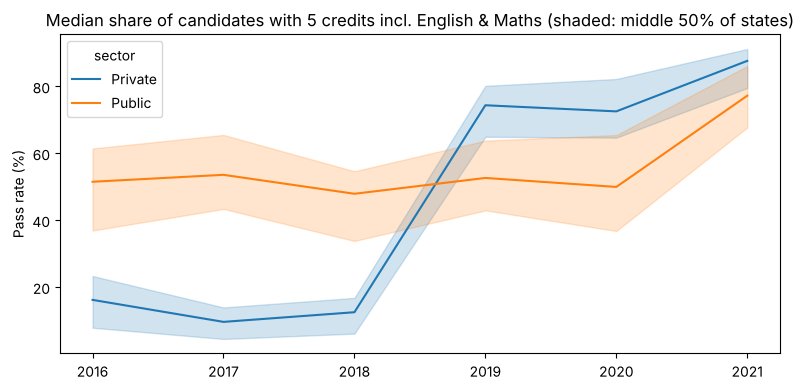

In [280]:
# Pass rate over time by sector
fig, ax = plt.subplots(figsize=(8, 4))
sns.lineplot(data=analysis, x="year", y=OUTCOME, hue="sector", estimator="median", errorbar=("pi", 50), ax=ax)
ax.set(title="Median share of candidates with 5 credits incl. English & Maths (shaded: middle 50% of states)",
       ylabel="Pass rate (%)", xlabel="")
plt.tight_layout(); plt.show()

The private-school pass rate rises sharply between 2018 and 2019. The percentages in the source files agree with their own
counts, so this is not a cleaning error; it most likely reflects a change in which candidates the private tables report.
Every analysis below works **within year and sector**, so a level shift like this does not
create a false link with any resource.

# CORRELATION ANALYSIS

Two measures are used for each indicator against the pass rate:

* **Pearson's r** measures straight-line association and is sensitive to outliers.
* **Spearman's ρ** uses ranks and catches any consistently increasing or decreasing relationship.

Because the 2016–18 and 2019–21 private figures are on different levels, the correlations are computed on
**year-demeaned** values (each value minus that year and sector's mean), as well as on the raw pooled values for
comparison.

In [281]:
# Defining a function to correlate every indicator with the pass rate
def correlate(df, label):
    out = []
    for c in RESOURCES:
        d = df[[c, OUTCOME]].dropna()
        if len(d) < 10:
            continue
        r, pr = stats.pearsonr(d[c], d[OUTCOME])
        rho, ps = stats.spearmanr(d[c], d[OUTCOME])
        out.append({"indicator": c, "n": len(d), "pearson_r": r, "pearson_p": pr,
                    "spearman_rho": rho, "spearman_p": ps})
    res = pd.DataFrame(out).set_index("indicator")
    res.columns = pd.MultiIndex.from_product([[label], res.columns])
    return res

# Removing each year-and-sector mean, so only differences between states within a year remain
demeaned = analysis.copy()
for c in RESOURCES + [OUTCOME]:
    demeaned[c] = demeaned[c] - demeaned.groupby(["year", "sector"])[c].transform("mean")

corr_table = pd.concat([
    correlate(analysis, "Pooled (raw)"),
    correlate(demeaned, "Within year & sector"),
    correlate(demeaned[demeaned["sector"] == "Public"], "Public only"),
    correlate(demeaned[demeaned["sector"] == "Private"], "Private only"),
], axis=1)
corr_table.round(3)

Pooled (raw)                                             Within year & sector                                              \
                                          n pearson_r pearson_p spearman_rho spearman_p                    n pearson_r pearson_p spearman_rho spearman_p   
indicator                                                                                                                                                  
student_teacher_ratio                   403     0.020     0.690        0.029      0.565                  403    -0.107     0.031       -0.197      0.000   
qualified_teacher_pct                   403     0.152     0.002        0.140      0.005                  403    -0.053     0.284        0.006      0.912   
students_per_qualified_teacher          399    -0.033     0.516       -0.058      0.250                  399    -0.045     0.372       -0.078      0.118   
students_per_school                     148     0.347     0.000        0.472      0.000                  148    -0.194     0.018       -0.419      0.000   
students_per_good_classroom             222     0.001     0.992       -0.291      0.000                  222     0.003     0.966       -0.014      0.840   
good_classroom_pct                      222     0.166     0.013        0.194      0.004                  222    -0.054     0.425       -0.042      0.532   
students_per_toilet                     221    -0.059     0.386       -0.241      0.000                  221    -0.004     0.949       -0.090      0.181   

                               Public only                                             Private only                                              
                                         n pearson_r pearson_p spearman_rho spearman_p            n pearson_r pearson_p spearman_rho spearman_p  
indicator                                                                                                                                        
student_teacher_ratio                  220    -0.165     0.015       -0.303      0.000          183     0.126     0.090        0.105      0.156  
qualified_teacher_pct                  220    -0.100     0.138       -0.025      0.715          183     0.026     0.729        0.063      0.400  
students_per_qualified_teacher         220    -0.069     0.307       -0.140      0.039          179     0.071     0.344        0.073      0.332  
students_per_school                     74    -0.193     0.099       -0.374      0.001           74    -0.197     0.092       -0.299      0.010  
students_per_good_classroom            111    -0.103     0.282       -0.086      0.367          111     0.024     0.802        0.029      0.760  
good_classroom_pct                     111    -0.124     0.196       -0.136      0.155          111     0.084     0.380        0.128      0.179  
students_per_toilet                    111     0.017     0.856       -0.132      0.166          110    -0.032     0.736        0.056      0.560

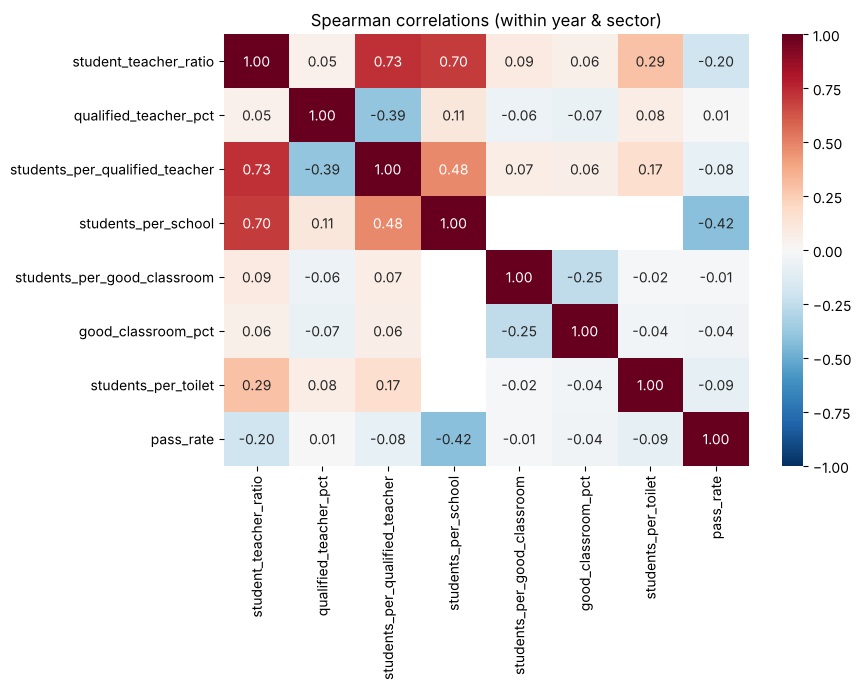

In [282]:
# Heatmap of Spearman correlations between the indicators and the pass rate (within year & sector)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(demeaned[RESOURCES + [OUTCOME]].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlations (within year & sector)")
plt.tight_layout(); plt.show()

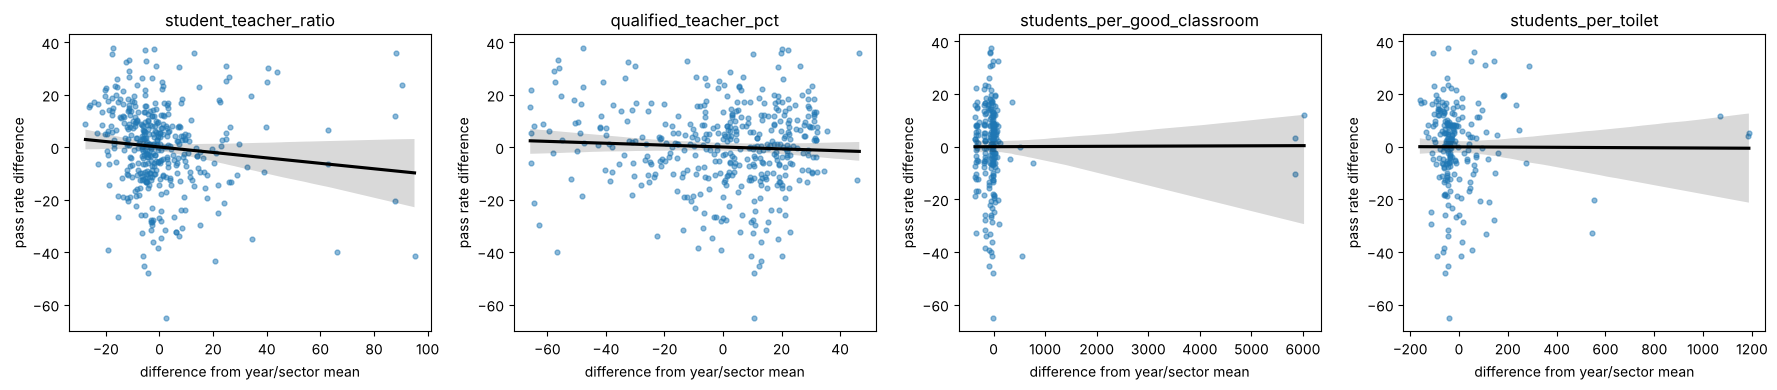

In [283]:
# Scatter plots of the main indicators against the pass rate
main = ["student_teacher_ratio", "qualified_teacher_pct", "students_per_good_classroom", "students_per_toilet"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, main):
    sns.regplot(data=demeaned, x=c, y=OUTCOME, ax=ax, scatter_kws={"s": 12, "alpha": .5}, line_kws={"color": "black"})
    ax.set(title=c, xlabel="difference from year/sector mean", ylabel="pass rate difference")
plt.tight_layout(); plt.show()

# PARTIAL CORRELATION

An ordinary correlation looks at **one resource at a time**. If two resources move together (for example, states with
more students per teacher may also have fewer qualified teachers), an ordinary correlation cannot tell which of them is
linked to the pass rate. A **partial correlation** answers this: it measures the correlation between one resource and the
pass rate **after removing the part of both that is explained by the other resources**.

How it is computed for each resource:

1. Regress the resource on the **other resources** and on **year × sector dummies**, and keep the residuals
   (what is left of the resource that the others and the year/sector cannot explain).
2. Do the same for the pass rate.
3. Correlate the two sets of residuals. That correlation is the partial correlation.

The year × sector dummies play the same role as the year-and-sector demeaning in the correlation section, so the private
2018–2019 jump and other year shifts cannot create a false link. Two versions are reported:

* **Pearson partial r**, using the log of the "students per …" ratios;
* **Spearman partial ρ**, computed on ranks, which is robust to outliers.

The p-value uses a t-test with *n − 2 − k* degrees of freedom, where *k* is the number of controls (the other resources
plus the year × sector dummies). The 95% confidence interval uses Fisher's z transformation.

In [284]:
# Defining a function for the partial correlation of each feature with the outcome, controlling for the others
def partial_corr(df, features, label, method="pearson"):
    d = df[["year", "sector", OUTCOME] + features].dropna().copy()
    if method == "spearman":                                   # rank every variable first
        for c in features + [OUTCOME]:
            d[c] = d[c].rank()
    groups = pd.get_dummies(d["year"].astype(str) + "_" + d["sector"], drop_first=True, dtype=float)
    out = []
    for f in features:
        others = [c for c in features if c != f]
        Z = np.column_stack([np.ones(len(d)), d[others].values, groups.values])    # controls
        res_x = d[f].values - Z @ np.linalg.lstsq(Z, d[f].values, rcond=None)[0]
        res_y = d[OUTCOME].values - Z @ np.linalg.lstsq(Z, d[OUTCOME].values, rcond=None)[0]
        r = np.corrcoef(res_x, res_y)[0, 1]
        k = Z.shape[1] - 1                                     # number of controls (excluding the constant)
        dof = len(d) - 2 - k
        t = r * np.sqrt(dof / (1 - r ** 2))
        p = 2 * stats.t.sf(abs(t), dof)
        z, se = np.arctanh(r), 1 / np.sqrt(len(d) - 3 - k)    # Fisher z interval
        out.append({"set": label, "feature": f.replace("log_", ""), "method": method, "n": len(d), "controls": k,
                    "partial_r": r, "ci_low": np.tanh(z - 1.96 * se), "ci_high": np.tanh(z + 1.96 * se), "p_value": p})
    return pd.DataFrame(out)

Three feature sets, because the resources cover different years. `students_per_qualified_teacher` is left out of the
sets: it is the student-teacher ratio divided by the qualified share, so it adds no information once those two are in.

| Set | Years | Features |
|---|---|---|
| A: teachers | 2016–2021 | student-teacher ratio, qualified-teacher % |
| B: all resources | 2019–2021 | student-teacher ratio, qualified-teacher %, students per good classroom, students per toilet |
| C: school size | 2016–2017 | student-teacher ratio, qualified-teacher %, students per school |

Each set is run on both sectors together, on public schools only and on private schools only.

In [285]:
SETS = {
    "A: teachers, 2016–2021": (["log_student_teacher_ratio", "qualified_teacher_pct"], range(2016, 2022)),
    "B: all resources, 2019–2021": (["log_student_teacher_ratio", "qualified_teacher_pct",
                                     "log_students_per_good_classroom", "log_students_per_toilet"], range(2019, 2022)),
    "C: school size, 2016–2017": (["log_student_teacher_ratio", "qualified_teacher_pct", "log_students_per_school"],
                                  range(2016, 2018)),
}
SAMPLES = {"Both sectors": analysis,
           "Public": analysis[analysis["sector"] == "Public"],
           "Private": analysis[analysis["sector"] == "Private"]}

tables = []
for set_name, (feats, years) in SETS.items():
    for sample_name, data in SAMPLES.items():
        d = data[data["year"].isin(years)]
        for method in ("pearson", "spearman"):
            t = partial_corr(d, feats, set_name, method)
            t["sample"] = sample_name
            tables.append(t)
partial = pd.concat(tables, ignore_index=True)
partial["sig"] = np.select([partial["p_value"] < .01, partial["p_value"] < .05, partial["p_value"] < .1], ["***", "**", "*"], "")

# Side-by-side view: Pearson and Spearman partial correlations for every set and sample
view = partial.pivot_table(index=["set", "sample", "feature"], columns="method",
                           values=["partial_r", "p_value"], aggfunc="first")
view.columns = [f"{m}_{v}" for v, m in view.columns]
view = view[["pearson_partial_r", "pearson_p_value", "spearman_partial_r", "spearman_p_value"]].round(3)
view

pearson_partial_r  pearson_p_value  spearman_partial_r  spearman_p_value
set                         sample       feature                                                                                              
A: teachers, 2016–2021      Both sectors qualified_teacher_pct                   -0.050            0.325               0.033             0.521
                                         student_teacher_ratio                   -0.107            0.035              -0.148             0.003
                            Private      qualified_teacher_pct                    0.037            0.620               0.063             0.404
                                         student_teacher_ratio                    0.126            0.094               0.109             0.148
                            Public       qualified_teacher_pct                   -0.058            0.401               0.044             0.525
                                         student_teacher_ratio                   -0.267            0.000              -0.298             0.000
B: all resources, 2019–2021 Both sectors qualified_teacher_pct                    0.090            0.194               0.160             0.021
                                         student_teacher_ratio                   -0.102            0.143              -0.099             0.153
                                         students_per_good_classroom              0.001            0.984               0.027             0.702
                                         students_per_toilet                      0.002            0.982              -0.026             0.704
                            Private      qualified_teacher_pct                    0.094            0.343               0.145             0.144
                                         student_teacher_ratio                    0.145            0.145               0.107             0.280
                                         students_per_good_classroom              0.042            0.671               0.063             0.528
                                         students_per_toilet                     -0.020            0.842               0.036             0.720
                            Public       qualified_teacher_pct                    0.120            0.227               0.176             0.074
                                         student_teacher_ratio                   -0.253            0.010              -0.275             0.005
                                         students_per_good_classroom             -0.014            0.886               0.045             0.651
                                         students_per_toilet                      0.031            0.755              -0.002             0.986
C: school size, 2016–2017   Both sectors qualified_teacher_pct                   -0.160            0.099              -0.053             0.590
                                         student_teacher_ratio                   -0.076            0.435              -0.025             0.797
                                         students_per_school                     -0.218            0.024              -0.287             0.003
                            Private      qualified_teacher_pct                   -0.234            0.176              -0.201             0.247
                                         student_teacher_ratio                   -0.122            0.484              -0.178             0.307
                                         students_per_school                     -0.152            0.382              -0.210             0.226
                            Public       qualified_teacher_pct                   -0.161            0.179               0.008             0.950
                                         student_teacher_ratio                   -0.003            0.981              -0.062             0.608
                                         students_per_school      

## Partial correlation compared with ordinary correlation (public schools)

The chart puts the ordinary within-year Spearman correlation from the correlation section next to the Spearman partial
correlation for each resource in public schools. If a bar shrinks towards zero, part of the ordinary correlation came
from the other resources; if it holds its size, the resource is linked to the pass rate in its own right.

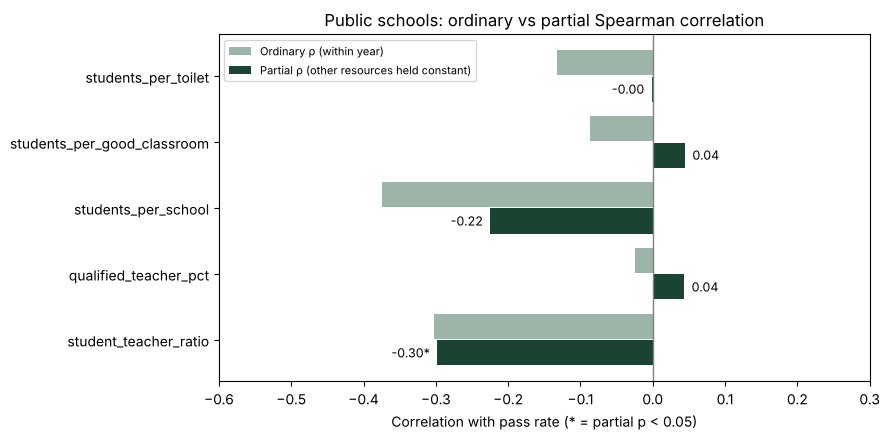

,ordinary ρ,partial ρ,partial p
student_teacher_ratio,-0.303,-0.298,0.000
qualified_teacher_pct,-0.025,0.044,0.525
students_per_school,-0.374,-0.225,0.059
students_per_good_classroom,-0.086,0.045,0.651
students_per_toilet,-0.132,-0.002,0.986


In [286]:
# Ordinary (within year and sector) vs partial Spearman correlation, public schools
pick = {"student_teacher_ratio": "A: teachers, 2016–2021", "qualified_teacher_pct": "A: teachers, 2016–2021",
        "students_per_school": "C: school size, 2016–2017", "students_per_good_classroom": "B: all resources, 2019–2021",
        "students_per_toilet": "B: all resources, 2019–2021"}
sp = partial[(partial["sample"] == "Public") & (partial["method"] == "spearman")]
compare_df = pd.DataFrame({
    "ordinary ρ": {f: corr_table.loc[f, ("Public only", "spearman_rho")] for f in pick},
    "partial ρ": {f: sp[(sp["set"] == s) & (sp["feature"] == f)]["partial_r"].iloc[0] for f, s in pick.items()},
    "partial p": {f: sp[(sp["set"] == s) & (sp["feature"] == f)]["p_value"].iloc[0] for f, s in pick.items()},
})

fig, ax = plt.subplots(figsize=(9, 4.5))
y = np.arange(len(compare_df))
ax.barh(y + 0.2, compare_df["ordinary ρ"], height=0.38, color="#9DB4A8", label="Ordinary ρ (within year)")
ax.barh(y - 0.2, compare_df["partial ρ"], height=0.38, color="#1B4332", label="Partial ρ (other resources held constant)")
for yi, (v, p) in enumerate(zip(compare_df["partial ρ"], compare_df["partial p"])):
    ax.text(v + (0.01 if v >= 0 else -0.01), yi - 0.2, f"{v:.2f}{'*' if p < .05 else ''}",
            va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(compare_df.index)
ax.axvline(0, color="grey", lw=1); ax.set_xlim(-0.6, 0.3)
ax.set_xlabel("Correlation with pass rate (* = partial p < 0.05)")
ax.set_title("Public schools: ordinary vs partial Spearman correlation")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout(); plt.show()
compare_df.round(3)

## Partial correlations with 95% confidence intervals

Each dot is a Spearman partial correlation and each line its 95% confidence interval, for both sectors together, public
schools and private schools. A line that crosses zero means the resource is not distinguishable from no association
once the other resources are held constant.

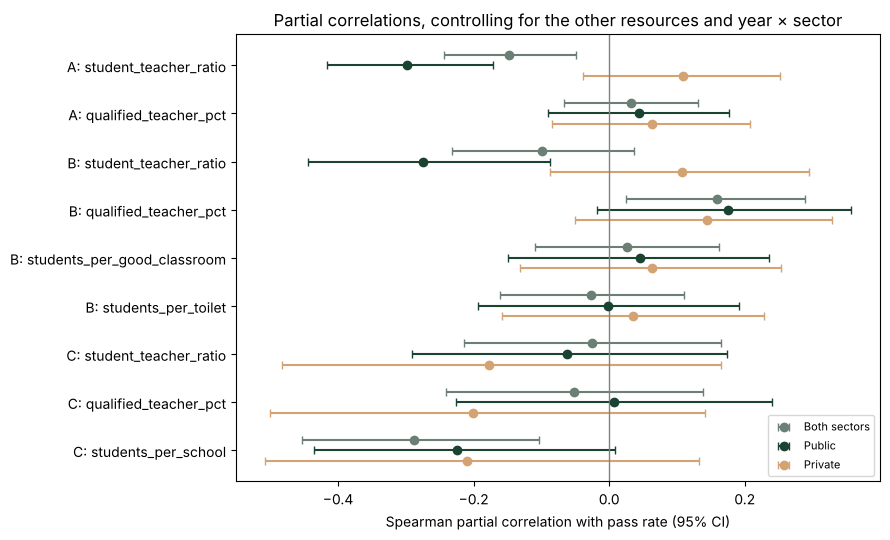

In [287]:
# Forest plot of the Spearman partial correlations
sp_all = partial[partial["method"] == "spearman"].copy()
sp_all["row"] = sp_all["set"].str[:1] + ": " + sp_all["feature"]
rows = list(dict.fromkeys(sp_all["row"]))
colors = {"Both sectors": "#6B7F75", "Public": "#1B4332", "Private": "#D4A373"}
fig, ax = plt.subplots(figsize=(9, 5.5))
for off, (sample, g) in zip((-0.22, 0, 0.22), sp_all.groupby("sample", sort=False)):
    yy = [rows.index(r) + off for r in g["row"]]
    ax.errorbar(g["partial_r"], yy, xerr=[g["partial_r"] - g["ci_low"], g["ci_high"] - g["partial_r"]],
                fmt="o", capsize=3, color=colors[sample], label=sample)
ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows); ax.invert_yaxis()
ax.axvline(0, color="grey", lw=1)
ax.set_xlabel("Spearman partial correlation with pass rate (95% CI)")
ax.set_title("Partial correlations, controlling for the other resources and year × sector")
ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

In [288]:
# Checking the features in each set are not too closely related to each other (variance inflation factors)
from statsmodels.stats.outliers_influence import variance_inflation_factor
vif = {}
for set_name, (feats, years) in SETS.items():
    d = analysis[analysis["year"].isin(years)][feats].dropna()
    Xv = sm.add_constant(d)
    vif[set_name] = pd.Series([variance_inflation_factor(Xv.values, i) for i in range(1, Xv.shape[1])],
                              index=[f.replace("log_", "") for f in feats])
pd.DataFrame(vif).round(2)

,"A: teachers, 2016–2021","B: all resources, 2019–2021","C: school size, 2016–2017"
qualified_teacher_pct,1.06,1.07,1.21
student_teacher_ratio,1.06,1.53,2.41
students_per_good_classroom,NaN,1.40,NaN
students_per_school,NaN,NaN,2.52
students_per_toilet,NaN,1.45,NaN


#### What to look for
* **Partial vs ordinary.** A resource whose correlation keeps its size once the others are held constant is linked to the
  pass rate in its own right. One that shrinks to zero was only borrowing another resource's association.
* **Public vs private.** The public data are the most complete. Private results are affected by the 2018–2019 level shift
  and the missing 2017 private teacher file, so they should be read with caution.
* **VIF.** Values below about 5 mean the features are distinct enough for their partial correlations to be separated.

# COMPARING THE APPROACHES

The table lines up, for each resource, the ordinary within-year correlation and the partial correlation (Spearman, set A
for the teacher measures, set B for classrooms and toilets, set C for school size), for both sectors together and for
public schools.

In [289]:
# Ordinary vs partial correlation, both sectors and public schools
def partial_value(sample, feature, col):
    s = pick[feature]
    row = partial[(partial["sample"] == sample) & (partial["method"] == "spearman") &
                  (partial["set"] == s) & (partial["feature"] == feature)]
    return row[col].iloc[0]

summary = pd.DataFrame({
    "ordinary ρ (both)": corr_table.loc[list(pick), ("Within year & sector", "spearman_rho")].values,
    "partial ρ (both)": [partial_value("Both sectors", f, "partial_r") for f in pick],
    "partial p (both)": [partial_value("Both sectors", f, "p_value") for f in pick],
    "ordinary ρ (public)": corr_table.loc[list(pick), ("Public only", "spearman_rho")].values,
    "partial ρ (public)": [partial_value("Public", f, "partial_r") for f in pick],
    "partial p (public)": [partial_value("Public", f, "p_value") for f in pick],
}, index=list(pick))
summary.round(3)

,ordinary ρ (both),partial ρ (both),partial p (both),ordinary ρ (public),partial ρ (public),partial p (public)
student_teacher_ratio,-0.197,-0.148,0.003,-0.303,-0.298,0.000
qualified_teacher_pct,0.006,0.033,0.521,-0.025,0.044,0.525
students_per_school,-0.419,-0.287,0.003,-0.374,-0.225,0.059
students_per_good_classroom,-0.014,0.027,0.702,-0.086,0.045,0.651
students_per_toilet,-0.090,-0.026,0.704,-0.132,-0.002,0.986


# DOCUMENTATION OF FINDINGS

## 1. What was done

* **Data.** 44 cleaned CSV files: students, teachers, classrooms and toilets (educational resources) and WAEC results
  (student outcomes), for public and private secondary schools in the 36 states and the FCT, 2016–2021.
* **Cleaning** (same approach as the original notebook):
  * State names standardised (footnote stars removed, spellings such as *Nassarawa*, *Platea*, *Cross Rivers*,
    *Akwa-Ibom*, *FCT-Abuja* unified; *National*/*Total* renamed *Nigeria*).
  * Column names made the same across years (e.g. `num_schools` → `number_of_schools`, `sss1_male` → `ss1_male`,
    `quaified_teachers_male` → `qualified_teachers_male`, `pub_cands_total` → `candidates_total`).
  * Missing values filled with the **median of the column**, and every total recalculated as the **sum of its parts**
    (male + female, SS1 + SS2 + SS3, good + bad classrooms, qualified + non-qualified teachers). Where a state reported a
    total but not its breakdown, the reported total was kept and only the breakdown was filled.
  * **Taraba was added to the 2018 public WAEC file** as an empty row and filled the same way.
  * Missing WAEC credit counts were filled from the median *pass rate* of the column times the state's own candidates,
    because a median *count* gave impossible results (more credits than candidates for small states such as Gombe 2017).
  * A state reporting 0 toilets or 0 classrooms with blank breakdowns was treated as missing, not as a real zero.
  * The national row was rebuilt as the sum of the states after filling.
* **Panel.** 37 states × 2 sectors = 74 units, 2016–2021 (444 state-sector-years). Outcome: percentage of WAEC candidates
  with five credits including English and Mathematics.
* **Methods compared.** Pearson and Spearman correlation (pooled, and within year and sector), and **partial correlation**
  (Pearson on log ratios and Spearman on ranks) of each resource with the pass rate, controlling for the other resources
  and for year × sector. Three feature sets (teachers 2016–2021; all resources 2019–2021; school size 2016–2017), each
  for both sectors, public schools and private schools; variance inflation factors to check the features are distinct.

## 2. Main findings

**1. The student-teacher ratio is the resource most consistently linked to WAEC results, and only in public schools.**

* Within the same year and sector, states with more students per teacher have lower pass rates
  (Spearman ρ = −0.20, p < 0.001; public schools alone ρ = −0.30, p < 0.001).
* **Holding the qualified-teacher share and year × sector constant, the link is unchanged in public schools:** partial
  ρ = −0.30 (p < 0.001; Pearson partial r = −0.27, p < 0.001). For both sectors together it is −0.15 (p = 0.003).
* With classrooms and toilets also held constant (public, 2019–2021) it stays at **partial ρ = −0.28 (p = 0.005)**.
* It is the only resource that keeps a significant partial correlation in every public-school set where school size is
  not included. When students per school is added (2016–2017), the two share their effect (they are closely related,
  ρ = 0.70), and neither is significant on its own in public schools.

**2. The share of qualified teachers has a positive but weak association.**

* The raw pooled correlation is positive (ρ = 0.14, p = 0.005), but it disappears once each year and sector is compared
  with itself (ρ = 0.01, p = 0.91).
* Its partial correlation is close to zero for 2016–2021 (partial ρ = 0.03, p = 0.52; public 0.04, p = 0.53). It is
  positive for 2019–2021 once classrooms and toilets are held constant (both sectors 0.16, p = 0.021; public 0.18,
  p = 0.074), so it points in the expected direction but is weaker and less consistent than the student-teacher ratio.

**3. Classrooms and toilets show no reliable association (2019–2021).**

* Students per good classroom and students per toilet are not significant in any partial correlation
  (all |partial ρ| ≤ 0.06, all p > 0.5), and their ordinary within-year correlations were already small (|ρ| ≤ 0.09).
* Their raw pooled correlations are significant (e.g. students per good classroom ρ = −0.29), but that reflects the
  difference between sectors: private schools have fewer students per classroom and higher pass rates. It is not a
  difference between states.
* Only three years are available, the classroom data are aggregated, and the toilet files have many gaps, so the
  absence of an effect may reflect weak data rather than no real link.

**4. School size (2016–2017 only).** States with more students per school had clearly lower pass rates
(within-year ρ = −0.42, p < 0.001). Holding the student-teacher ratio and qualified-teacher share constant, it keeps a
partial correlation of −0.29 (p = 0.003) for both sectors and −0.23 (p = 0.059) for public schools. There are only two
years of school counts, so this result rests on a small sample.

**5. Private-school results are not reliable enough to draw conclusions.**

* No resource has a significant partial correlation in private schools (all p > 0.14); the private student-teacher ratio
  is even slightly positive (partial ρ = +0.11, p = 0.15).
* The private pass rate jumps between 2018 and 2019 (the source percentages match their counts, so the jump is in the
  data itself), and private teacher data are missing for 2017 and partly reused from 2018 in 2019–2021.

## 3. Comparing the approaches

| | Ordinary correlation (within year) | Partial correlation (other resources held constant) |
|---|---|---|
| Uses | one resource at a time, within year and sector | one resource after removing the others and year × sector |
| Student-teacher ratio (public) | −0.30, significant | −0.30 (2016–21) and −0.28 (2019–21), significant |
| Qualified teachers (public) | none (−0.03) | none (0.04, 2016–21); weak positive (0.18, p = 0.074, 2019–21) |
| Students per school (public, 2016–17) | −0.37, significant | −0.23 (p = 0.059) |
| Classrooms / toilets (public) | small (−0.09, −0.13), n.s. | about zero (0.05, −0.00), n.s. |

* **Ordinary correlation** is quick and robust to outliers when rank-based (Spearman), but it cannot hold other resources
  constant, and raw pooled correlations are misleading here because sector and year differences dominate.
* **Partial correlation** keeps the simplicity of a correlation but removes the part of each resource that is shared with
  the others. A resource whose correlation survives this is linked to the pass rate in its own right; one that shrinks
  was borrowing another resource's association.
* The student-teacher ratio is the only resource whose correlation keeps its size once the others are held constant.
* The variance inflation factors are all below 2.6, so the resources are not so closely related that their partial
  correlations cannot be separated.

## 4. Conclusion

Among the resources with usable data, the **number of students per teacher** is the one most closely associated with
the share of candidates obtaining five credits including English and Mathematics. In public schools a lower ratio goes
with a higher pass rate, and the relationship holds in both the ordinary and the partial correlations, including when
classrooms, toilets and teacher qualification are held constant. **Teacher qualification** points in the expected
positive direction but is weaker and less certain. **Classroom condition and toilet provision** show no detectable
association in the three years available.

## 5. Limitations

* The data are state-level aggregates, so they show associations between states, not effects on individual students
  or schools, and they do not prove cause and effect.
* Several series are reused from earlier years (students 2017–2018, teachers 2018–2021, classrooms 2018), which hides
  real year-to-year change.
* There are no classroom or toilet files for 2016–2018 and no private teacher file for 2017; those combinations were
  left out rather than invented.
* Median imputation pulls filled states toward the middle, which slightly weakens any association they are part of.
* Private WAEC figures change level between 2018 and 2019, which suggests a change in what is reported. Working within
  year and sector absorbs the shift, but private-school results should be read with caution.
* Partial correlation holds constant only the resources in the data. Other drivers of WAEC performance (household income,
  funding, location, exam conditions) are not in the data.